# End-to-End NLP Pipeline for Customer Feedback Intelligence and Sentiment-Driven Decision Support
**MSc Artificial Intelligence | Module: Natural Language Processing**

**Dataset:** Twitter US Airline Sentiment (CrowdFlower, 2015): 14,640 tweets addressed to six US airlines, crowd-labelled for sentiment and complaint reason.
**Source:** https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment


### How to run
1. **Runtime → Change runtime type → T4 GPU** (needed for Task 4; Tasks 1–3 also run on CPU).
2. **Runtime → Run all.** The dataset downloads automatically through `kagglehub`. If that fails, an upload dialog asks for `Tweets.csv`.
3. A full run takes about **20–25 minutes** on a T4. Each task saves its outputs to `outputs/` and its figures to `figures/taskN/`, and later tasks read them from there, so no manual uploads are needed between tasks.
4. The final cell downloads `nlp_pipeline_outputs.zip` with every figure and table.

All randomness is seeded (`SEED = 42`). The train/test split is created once in Task 2 and reused by Tasks 3 and 4.

In [1]:
# Install essential NLP and Transformer libraries
!pip install -q emoji kagglehub wordcloud gensim sentence-transformers accelerate
!python -m spacy download en_core_web_sm 2>&1 | tail -n 1

'Restart kernel' or 'Restart runtime' option.


# Task 1: Preprocessing and Exploratory Analysis of Customer Feedback
**Module:** Natural Language Processing (MSc Artificial Intelligence)
**Project:** End-to-End NLP Pipeline for Customer Feedback Intelligence and Sentiment-Driven Decision Support

**Dataset:** Twitter US Airline Sentiment: 14,640 tweets addressed to six US airlines (February 2015), crowd-annotated for sentiment (negative / neutral / positive) and, for negative tweets, a complaint reason.
**Source:** Figure Eight (CrowdFlower), hosted on Kaggle: https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment

**What this notebook does**

| Section | Content |
|---|---|
| 1.0 | Environment set-up |
| 1.1 | Load and inspect the data |
| 1.2 | Data-quality audit (duplicates, sparse columns, label confidence, airline handles) |
| 1.3 | Repair of a label-string substitution artefact in the source text |
| 1.4 | Exploratory analysis of labels and metadata |
| 1.5 | Twitter-aware text cleaning |
| 1.6 / 1.7 | NLTK and spaCy preprocessing pipelines (tokenisation, lemmatisation, stop words) |
| 1.8 | NLTK vs spaCy comparison (quantitative + qualitative) |
| 1.9 | Stop-word handling and negation |
| 1.10 | Token frequencies, distinctive terms, complaint bigrams, word clouds, length distributions |
| 1.11 | spaCy Named Entity Recognition |
| 1.12 | Domain adaptation with a spaCy EntityRuler (airlines, service touchpoints, issues) |
| 1.13 | Save processed data for Tasks 2–4 |

## 1.0 Environment set-up

In [2]:
# System and utility imports
import os, re, html, time, random, shutil, warnings
from collections import Counter

# Data analysis and plotting libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import ListedColormap
import seaborn as sns

# NLTK components for text processing
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from nltk.tag import PerceptronTagger

# spaCy and text visualization tools
import spacy
from spacy import displacy
import emoji
from wordcloud import WordCloud
from IPython.display import display

# Set seed for reproducible results
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)

# Create folders for output files
FIG_DIR, OUT_DIR = "figures/task1", "outputs"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# Configure plot styles and sentiment colors
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.titleweight": "bold", "axes.titlesize": 12})
SENT_ORDER = ["negative", "neutral", "positive"]
SENT_PALETTE = {"negative": "#C0392B", "neutral": "#95A5A6", "positive": "#27AE60"}

# Increase text column display width
pd.set_option("display.max_colwidth", 140)

# Helper function to save plots
def save_fig(name):
    path = os.path.join(FIG_DIR, f"{name}.png")
    plt.savefig(path)
    print(f"Saved figure → {path}")

# Print installed library versions
print(f"pandas {pd.__version__} | NLTK {nltk.__version__} | spaCy {spacy.__version__}")

pandas 2.2.3 | NLTK 3.9.1 | spaCy 3.8.16


In [3]:
# List NLTK resources for both old and new versions
NLTK_RESOURCES = ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
                  "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng",
                  "maxent_ne_chunker", "maxent_ne_chunker_tab", "words"]

# Download each resource quietly
for resource in NLTK_RESOURCES:
    nltk.download(resource, quiet=True)
# Confirm downloads are complete
print("NLTK resources ready.")

NLTK resources ready.


## 1.1 Load and inspect the dataset
The loader tries three routes in order: a local path (if you uploaded `Tweets.csv` yourself), a direct download through `kagglehub` (no API key needed for public datasets), and finally a manual upload dialog in Colab.

In [4]:
# Set Kaggle dataset reference and optional local path
KAGGLE_REF = "crowdflower/twitter-airline-sentiment"
DATA_PATH = None

# Function to load tweets from local path, Kaggle, or manual upload
def load_tweets(data_path=DATA_PATH):
    # Check if local file exists first
    if data_path and os.path.exists(data_path):
        print(f"Loading local file: {data_path}")
        return pd.read_csv(data_path)
    # Try downloading dataset automatically via kagglehub
    try:
        import kagglehub
        folder = kagglehub.dataset_download(KAGGLE_REF)
        print(f"Downloaded via kagglehub → {folder}")
        return pd.read_csv(os.path.join(folder, "Tweets.csv"))
    # Fallback to manual file upload in Google Colab
    except Exception as err:
        print(f"kagglehub download failed ({err}).\nPlease upload Tweets.csv manually:")
        from google.colab import files
        uploaded = files.upload()
        return pd.read_csv(next(iter(uploaded)))
# Load the dataset and display basic dimensions and preview
raw = load_tweets()
print(f"Raw data: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
raw.head(3)

Using Colab cache for faster access to the 'twitter-airline-sentiment' dataset.
Downloaded via kagglehub → /kaggle/input/twitter-airline-sentiment
Raw data: 14,640 rows × 15 columns


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials to the experience... tacky.,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I need to take another trip!,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)


In [5]:
# Function to get the first non-null value truncated to 60 chars
def first_valid(col):
    s = col.dropna()
    return str(s.iloc[0])[:60] if len(s) else None

# Build summary DataFrame with data types, missing %, unique counts, and examples
overview = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_%": (raw.isna().mean() * 100).round(1),
    "n_unique": raw.nunique(),
    "example": raw.apply(first_valid),
})
overview

,dtype,missing_%,n_unique,example
tweet_id,int64,0.0,14485,570306133677760513
airline_sentiment,object,0.0,3,neutral
airline_sentiment_confidence,float64,0.0,1023,1.0
negativereason,object,37.3,10,Bad Flight
negativereason_confidence,float64,28.1,1410,0.0
airline,object,0.0,6,Virgin America
airline_sentiment_gold,object,99.7,3,negative
name,object,0.0,7701,cairdin
negativereason_gold,object,99.8,13,Late Flight\nFlight Attendant Complaints
retweet_count,int64,0.0,18,0


In [6]:
# Sample two random tweets from each sentiment class
raw.groupby("airline_sentiment").sample(2, random_state=SEED)[
    ["airline_sentiment", "negativereason", "airline", "text"]]

,airline_sentiment,negativereason,airline,text
1151,negative,longlines,United,@united gate C 24 IAD. U released passengers to board w/others deplaning .50 peopleOn bridge while next flight board http://t.co/HfoF33...
9111,negative,Late Flight,US Airways,@USAirways 1729 connecting in charlotte to houston. Mechanical issue determined while q'd to take off. And we checked our bags.
7049,neutral,NaN,Delta,JetBlue reading the NYTimes. “@JetBlue: Our fleet's on fleek. http://t.co/lvIrTDtqly”
11484,neutral,NaN,US Airways,@USAirways just realized my @AmericanAir advantage number wasn't used for my flight. How do I get my ff miles?
8168,positive,NaN,Delta,@JetBlue you don't remember our date Monday night back to NYC? #heartbroken
11053,positive,NaN,US Airways,@USAirways thank you finally got our bag. Customer services reps were wonderful.


## 1.2 Data-quality audit
Before any NLP, we check for issues that would silently bias every later task: duplicated tweets (which leak between train and test splits in Tasks 2 and 4), conflicting labels, near-empty columns, low-agreement annotations, and whether the `airline` field matches the account the customer actually addressed.

In [7]:
# Check for exact duplicate rows and duplicated tweet IDs
n_dup_rows = raw.duplicated().sum()
dup_id_mask = raw.tweet_id.duplicated(keep=False)
conflicting_ids = raw[dup_id_mask].groupby("tweet_id").airline_sentiment.nunique().gt(1).sum()

# Deduplicate by tweet_id keeping highest confidence
df = (raw.sort_values("airline_sentiment_confidence", ascending=False)
         .drop_duplicates("tweet_id", keep="first"))
n_after_id = len(df)

# Deduplicate by identical text content
conflicting_texts = df.groupby("text").airline_sentiment.nunique().gt(1).sum()
df = (df.drop_duplicates("text", keep="first")
        .sort_index()
        .reset_index(drop=True)
        .rename(columns={"text": "text_raw"}))

# Drop gold standard columns with almost all missing values
df = df.drop(columns=["airline_sentiment_gold", "negativereason_gold"])

# Create summary table of dataset cleaning steps
dq = pd.Series({
    "Raw rows": len(raw),
    "Fully identical duplicate rows": n_dup_rows,
    "Duplicated tweet_ids (rows)": int(dup_id_mask.sum()),
    "  of which tweet_ids with conflicting labels": conflicting_ids,
    "Rows after tweet_id de-duplication": n_after_id,
    "Identical texts with conflicting labels": conflicting_texts,
    "Rows after text de-duplication (final)": len(df),
}, name="count").to_frame()
dq

,count
Raw rows,14640
Fully identical duplicate rows,36
Duplicated tweet_ids (rows),310
of which tweet_ids with conflicting labels,18
Rows after tweet_id de-duplication,14485
Identical texts with conflicting labels,7
Rows after text de-duplication (final),14427


In [8]:
# Calculate confidence metric and tag low-confidence tweets
conf = df.airline_sentiment_confidence
df["low_confidence"] = conf < 0.6

# Print overall confidence statistics
print(f"Median confidence: {conf.median():.2f} | tweets with full agreement (1.0): {(conf == 1).mean():.1%}")
print(f"Tweets below 0.6 confidence: {df.low_confidence.sum():,} ({df.low_confidence.mean():.1%})")

# Print percentage of non-unanimous tweets by sentiment class
print("\nShare of tweets with confidence < 1.0, by class:")
print(df.groupby("airline_sentiment").airline_sentiment_confidence.apply(lambda s: (s < 1).mean()).map("{:.1%}".format))

Median confidence: 1.00 | tweets with full agreement (1.0): 71.7%
Tweets below 0.6 confidence: 231 (1.6%)

Share of tweets with confidence < 1.0, by class:
airline_sentiment
negative    19.4%
neutral     49.7%
positive    34.9%
Name: airline_sentiment_confidence, dtype: object


In [9]:
# Extract the first @handle mentioned in each tweet
first_handle = df.text_raw.str.extract(r"@(\w+)", expand=False).str.lower()

# Audit how consistently each airline label matches the extracted handle
handle_audit = (df.assign(first_handle=first_handle)
                  .groupby("airline")["first_handle"]
                  .agg(most_common_handle=lambda s: s.value_counts().index[0],
                       share_of_tweets=lambda s: s.value_counts(normalize=True).iloc[0]))

# Format percentages and display summary
handle_audit["share_of_tweets"] = handle_audit.share_of_tweets.map("{:.1%}".format)
handle_audit

,most_common_handle,share_of_tweets
airline,,
American,americanair,99.8%
Delta,jetblue,99.7%
Southwest,southwestair,99.8%
US Airways,usairways,99.7%
United,united,99.9%
Virgin America,virginamerica,100.0%


> **Finding:** tweets labelled **Delta** are addressed to **@JetBlue**. The `airline` field is therefore mislabelled for one of the six carriers. Any per-airline insight (or fairness analysis across airlines in Task 5) must take this into account. In charts we label this group **Delta\* (@JetBlue)**.

In [10]:
# Rename Delta in plot label to clarify handle mismatch
df["airline_plot"] = df.airline.replace({"Delta": "Delta* (@JetBlue)"})

# Display tweet count per airline label
df.airline_plot.value_counts()

,count
airline_plot,
United,3805
US Airways,2906
American,2594
Southwest,2408
Delta* (@JetBlue),2211
Virgin America,503


## 1.3 Repairing a label-string substitution artefact
While inspecting the text we found that the dataset contains **no lower-case occurrences of "late", "cancel" or "booking"**. Instead, those substrings were overwritten with negative-reason label names during dataset preparation. For example, *"cancelled"* became *"Cancelled Flight**led**"*, *"later"* became *"Late Flight**r**"*, *"related"* became *"re**Late Flight**d"*, and *"rebooking"* became *"re**Flight Booking Problems**"*.

Left untreated, this artefact (i) inflates the count of *flight*, (ii) creates non-words (*Flightled*, *Flightr*) that fragment the vocabulary and break lemmatisation, (iii) produces capitalised spans that NER may tag as organisations, and (iv) would distort embeddings and retrieval in Task 3 (a query such as *"my flight was cancelled"* could not match the original wording). Because the substitution was a plain string replacement, it can be reversed exactly.

In [11]:
# Map injected dataset labels back to their original substring forms
ARTEFACT_MAP = {
    "Cancelled Flight": "cancel",
    "Late Flight": "late",
    "Flight Booking Problems": "booking",
}

# Function to replace injected label strings with original text
def repair_artefacts(text):
    for injected, original in ARTEFACT_MAP.items():
        text = text.replace(injected, original)
    return text

# Apply artefact repair to raw tweet text
df["text_repaired"] = df.text_raw.map(repair_artefacts)

# Helper function to count tweets matching a regex pattern
def count_tweets(series, pattern):
    regex = re.compile(pattern)
    return int(series.map(lambda t: bool(regex.search(t))).sum())

# Build comparison table showing keyword counts before and after repair
evidence = pd.DataFrame({
    "before repair": [count_tweets(df.text_raw, "|".join(map(re.escape, ARTEFACT_MAP))),
                      count_tweets(df.text_raw, r"\bcancel"),
                      count_tweets(df.text_raw, r"\blate\b"),
                      count_tweets(df.text_raw, r"\bbooking\b"),
                      int(df.text_raw.str.lower().str.count(r"\bflight").sum())],
    "after repair":  [count_tweets(df.text_repaired, "|".join(map(re.escape, ARTEFACT_MAP))),
                      count_tweets(df.text_repaired, r"\bcancel"),
                      count_tweets(df.text_repaired, r"\blate\b"),
                      count_tweets(df.text_repaired, r"\bbooking\b"),
                      int(df.text_repaired.str.lower().str.count(r"\bflight").sum())],
}, index=["Tweets containing an injected label string",
          "Tweets with lower-case 'cancel…'",
          "Tweets with lower-case 'late'",
          "Tweets with lower-case 'booking'",
          "Occurrences of 'flight…' (any case)"])
display(evidence)

# Count pseudo-words created by label string concatenations
pseudo = Counter(m.group(0) for t in df.text_raw
                 for m in re.finditer(r"\w*(?:Cancelled Flight|Late Flight|Flight Booking Problems)\w*", t))
print("Most frequent artefact forms:", pseudo.most_common(8))

# Display random examples comparing raw vs repaired text
examples = df[df.text_raw != df.text_repaired].sample(4, random_state=SEED)[["text_raw", "text_repaired"]]
examples

,before repair,after repair
Tweets containing an injected label string,1525,0
Tweets with lower-case 'cancel…',0,998
Tweets with lower-case 'late',0,235
Tweets with lower-case 'booking',0,86
Occurrences of 'flight…' (any case),5654,4050


Most frequent artefact forms: [('Cancelled Flightled', 497), ('Late Flight', 246), ('Cancelled Flighted', 219), ('Late Flightr', 155), ('Cancelled Flight', 142), ('Flight Booking Problems', 89), ('reFlight Booking Problems', 48), ('Cancelled Flighting', 43)]


,text_raw,text_repaired
8671,@JetBlue I understand but everyone said different things and there was a flight out Late Flightr that night but only one of us got to ta...,@JetBlue I understand but everyone said different things and there was a flight out later that night but only one of us got to take it
1038,"@united Not appropriate to ask in public (hence the dm). each united employee, each a new answer. your process was such a hassle i Cance...","@united Not appropriate to ask in public (hence the dm). each united employee, each a new answer. your process was such a hassle i cance..."
10563,@USAirways I fucking hate your customer service. I've been on hold all morning trying to figure out why you Cancelled Flighted my flight.,@USAirways I fucking hate your customer service. I've been on hold all morning trying to figure out why you canceled my flight.
13754,"@AmericanAir -- This is after you Cancelled Flightled our flight into Buffalo because of ""weather"" and lied to us and said other airline...","@AmericanAir -- This is after you cancelled our flight into Buffalo because of ""weather"" and lied to us and said other airlines cancelled"


## 1.4 Exploratory analysis of labels and metadata

Saved figure → figures/task1/fig1_01_sentiment_distribution.png


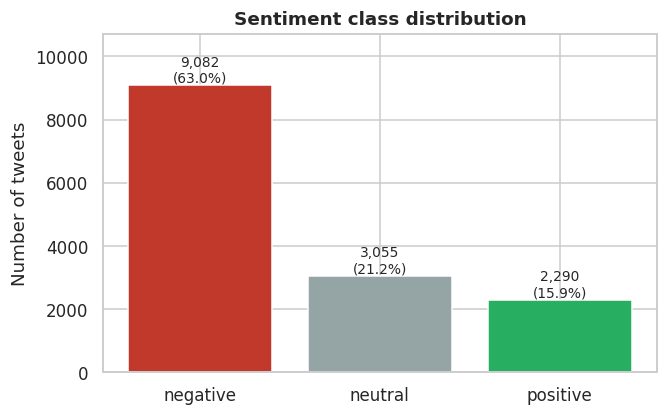

Imbalance ratio (majority / minority): 4.0 : 1
Accuracy of always predicting 'negative': 63.0%  → use macro-F1 in Tasks 2 and 4


In [12]:
# Reindex sentiment value counts by predefined class order
counts = df.airline_sentiment.value_counts().reindex(SENT_ORDER)

# Create figure and bar plot with class-specific colors
fig, ax = plt.subplots(figsize=(6.5, 4))
bars = ax.bar(counts.index, counts.values, color=[SENT_PALETTE[s] for s in counts.index])

# Annotate each bar with raw counts and percentage of total
for bar, value in zip(bars, counts.values):
    ax.annotate(f"{value:,}\n({value / len(df):.1%})", (bar.get_x() + bar.get_width() / 2, value),
                ha="center", va="bottom", fontsize=9)

# Set title, labels, and padding
ax.set(title="Sentiment class distribution", ylabel="Number of tweets", xlabel="")
ax.margins(y=0.18)

# Save figure and render plot
save_fig("fig1_01_sentiment_distribution"); plt.show()

# Print class imbalance ratio and baseline majority accuracy
print(f"Imbalance ratio (majority / minority): {counts.max() / counts.min():.1f} : 1")
print(f"Accuracy of always predicting 'negative': {counts['negative'] / len(df):.1%}  → use macro-F1 in Tasks 2 and 4")

Saved figure → figures/task1/fig1_02_sentiment_by_airline.png


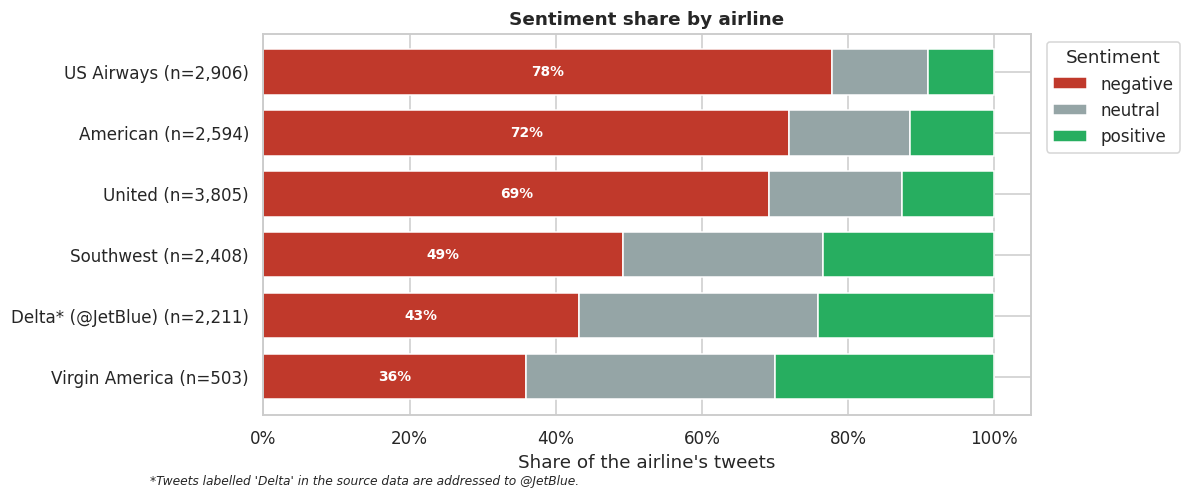

In [13]:
# Compute normalized sentiment proportions per airline sorted by negative share
share = pd.crosstab(df.airline_plot, df.airline_sentiment, normalize="index")[SENT_ORDER].sort_values("negative")
n_by_airline = df.airline_plot.value_counts()

# Initialize horizontal stacked bar plot with class colors
fig, ax = plt.subplots(figsize=(9, 4.5))
share.plot(kind="barh", stacked=True, ax=ax, width=0.75,
           color=[SENT_PALETTE[s] for s in SENT_ORDER])

# Annotate negative percentage inside each bar
for i, (_, row) in enumerate(share.iterrows()):
    ax.text(row.negative / 2, i, f"{row.negative:.0%}", va="center", ha="center",
            color="white", fontsize=9, fontweight="bold")

# Format y-axis labels with sample size, x-axis as percentage, and title
ax.set_yticks(range(len(share)), [f"{a} (n={n_by_airline[a]:,})" for a in share.index])
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set(title="Sentiment share by airline", xlabel="Share of the airline's tweets", ylabel="")

# Position legend and add footnote explaining Delta label anomaly
ax.legend(title="Sentiment", bbox_to_anchor=(1.01, 1), loc="upper left")
fig.text(0.01, -0.03, "*Tweets labelled 'Delta' in the source data are addressed to @JetBlue.", fontsize=8, style="italic")

# Save figure and display plot
save_fig("fig1_02_sentiment_by_airline"); plt.show()

Saved figure → figures/task1/fig1_03_negative_reasons.png


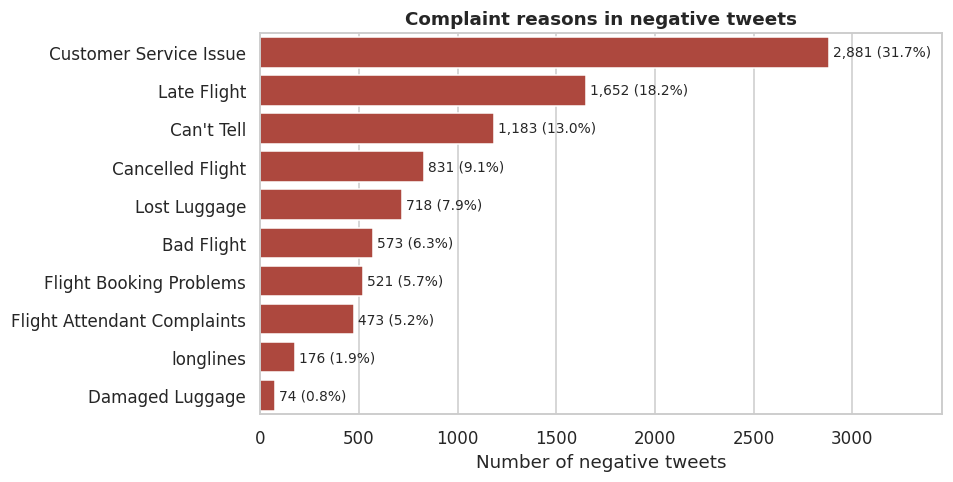

In [14]:
# Filter negative sentiment tweets and count complaint reasons
neg = df[df.airline_sentiment == "negative"]
reasons = neg.negativereason.value_counts()

# Create horizontal bar plot with negative sentiment color
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=reasons.values, y=reasons.index, color=SENT_PALETTE["negative"], ax=ax)

# Annotate each bar with raw count and percentage of negative tweets
for i, value in enumerate(reasons.values):
    ax.text(value + 20, i, f"{value:,} ({value / len(neg):.1%})", va="center", fontsize=9)

# Set title, labels, and plot margins
ax.set(title="Complaint reasons in negative tweets", xlabel="Number of negative tweets", ylabel="")
ax.margins(x=0.2)

# Save figure and render plot
save_fig("fig1_03_negative_reasons"); plt.show()

Saved figure → figures/task1/fig1_04_reason_by_airline_heatmap.png


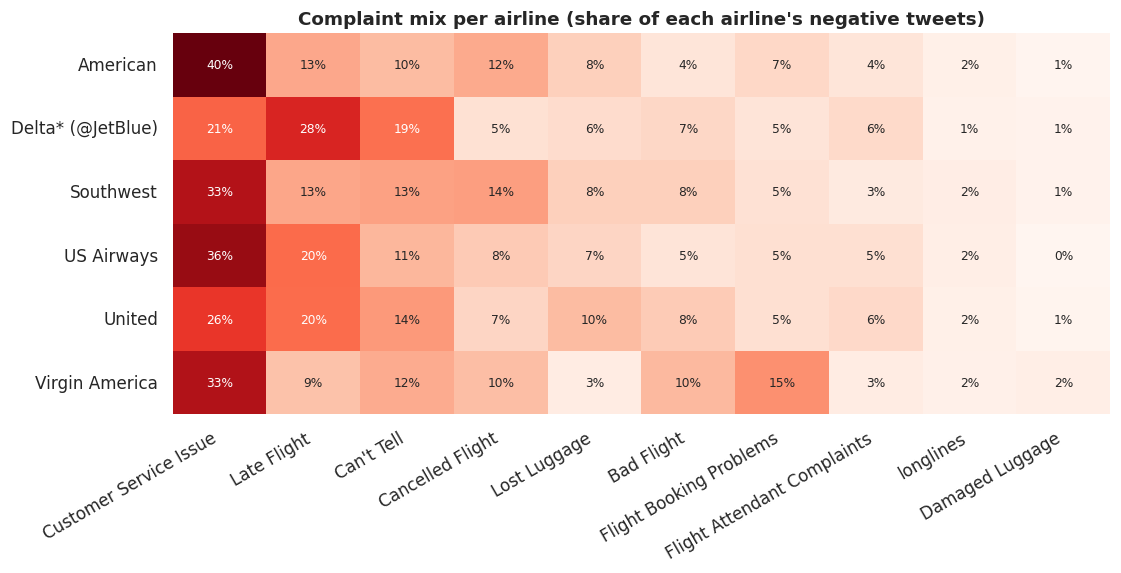

In [15]:
# Compute normalized complaint reason proportions per airline ordered by global frequency
reason_mix = pd.crosstab(neg.airline_plot, neg.negativereason, normalize="index")
reason_mix = reason_mix[reasons.index]

# Create heatmap showing complaint breakdown per airline
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(reason_mix, annot=True, fmt=".0%", cmap="Reds", cbar=False, ax=ax, annot_kws={"fontsize": 8})

# Format plot title, labels, and x-axis tick rotations
ax.set(title="Complaint mix per airline (share of each airline's negative tweets)", xlabel="", ylabel="")
plt.xticks(rotation=30, ha="right")

# Save figure and display plot
save_fig("fig1_04_reason_by_airline_heatmap"); plt.show()

Saved figure → figures/task1/fig1_05_label_confidence.png


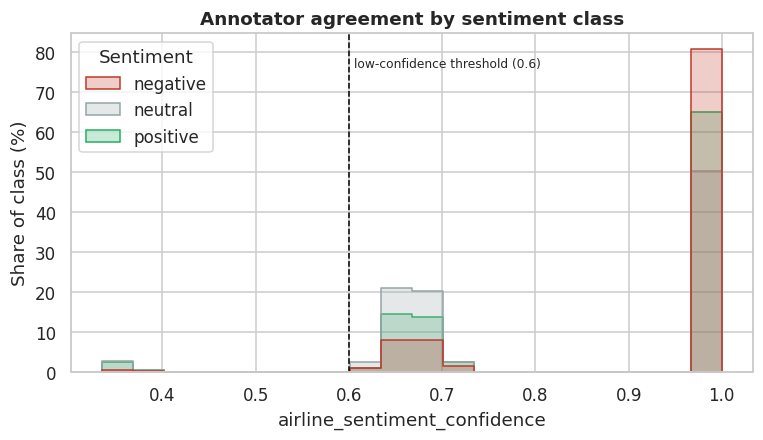

In [16]:
# Create histogram of annotator confidence grouped by sentiment class
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x="airline_sentiment_confidence", hue="airline_sentiment", hue_order=SENT_ORDER,
             palette=SENT_PALETTE, bins=20, stat="percent", common_norm=False, element="step", ax=ax)

# Position legend in upper left
sns.move_legend(ax, "upper left", title="Sentiment")

# Add vertical line and annotation text for low-confidence threshold at 0.6
ax.axvline(0.6, ls="--", c="black", lw=1)
ax.text(0.605, ax.get_ylim()[1] * 0.9, "low-confidence threshold (0.6)", fontsize=8)

# Set chart title and axis labels
ax.set(title="Annotator agreement by sentiment class", xlabel="airline_sentiment_confidence",
       ylabel="Share of class (%)")

# Save figure and render plot
save_fig("fig1_05_label_confidence"); plt.show()

## 1.5 Twitter-aware text cleaning
Generic cleaning recipes (lower-case everything, strip all punctuation) are a poor fit for tweets and would damage later steps. The design decisions below are deliberate:

| Step | Decision | Reason |
|---|---|---|
| HTML entities | `&amp;` → `&` | Raw Twitter export artefact |
| URLs | removed | No sentiment content; inflates vocabulary |
| Airline @handles | replaced by canonical names (`@united` → *United*) | Keeps the organisation entity visible to NER |
| Other @user handles | removed | Personal data (data minimisation) and noise |
| Hashtags | `#` dropped, CamelCase split (`#NeverAgain` → *Never Again*) | Hashtags often carry the sentiment |
| Emoticons / emoji | converted to words (`:(` → *sad_emoticon*, 😡 → *enraged_face*) | Strong sentiment cues that would otherwise be lost |
| Elongations | `soooo` → `soo` | Reduces vocabulary sparsity, keeps emphasis marker |
| Case & punctuation | **kept** at this stage | spaCy's tagger, lemmatiser and NER rely on capitalisation and punctuation; lower-casing happens *after* lemmatisation |

A second variant, `text_masked`, replaces airline names with the neutral token *airline*. Task 2 can then test whether a classifier relies on airline identity rather than on what the customer said, which links to fairness in Task 5.

In [17]:
# Map Twitter handles to official airline brand names
AIRLINE_HANDLES = {"virginamerica": "Virgin America", "united": "United", "southwestair": "Southwest",
                   "jetblue": "JetBlue", "delta": "Delta", "usairways": "US Airways",
                   "americanair": "American Airlines"}

# Compile regex patterns for URLs, mentions, hashtags, emoticons, and character elongations
URL_RE     = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@(\w+)")
HASHTAG_RE = re.compile(r"#(\w+)")
POS_EMO_RE = re.compile(r"(?<!\w)[:;=]-?[)D](?!\w)")
NEG_EMO_RE = re.compile(r"(?<!\w)[:;=]-?[(/\\](?!\w)")
ELONG_RE   = re.compile(r"([a-zA-Z])\1{2,}")

# Function to split camelCase hashtag strings into separate words
def split_camel(tag):
    return re.sub(r"(?<=[a-z])(?=[A-Z])", " ", tag)

# Twitter-aware text cleaning pipeline preserving casing and punctuation
def clean_tweet(text, mask_airlines=False):
    t = html.unescape(text)
    t = URL_RE.sub(" ", t)

    # Replace handle mentions with airline name, generic placeholder, or space
    def replace_mention(match):
        name = AIRLINE_HANDLES.get(match.group(1).lower())
        if name is None:
            return " "
        return " airline " if mask_airlines else f" {name} "

    # Apply regex replacements for mentions, hashtags, emoticons, emojis, and elongations
    t = MENTION_RE.sub(replace_mention, t)
    t = HASHTAG_RE.sub(lambda m: f" {split_camel(m.group(1))} ", t)
    t = POS_EMO_RE.sub(" happy_emoticon ", t)
    t = NEG_EMO_RE.sub(" sad_emoticon ", t)
    t = emoji.demojize(t, delimiters=(" ", " "))
    t = ELONG_RE.sub(r"\1\1", t)
    return re.sub(r"\s+", " ", t).strip()

# Apply cleaning to create standard and airline-masked text columns
df["text_clean"]  = df.text_repaired.map(clean_tweet)
df["text_masked"] = df.text_repaired.map(lambda t: clean_tweet(t, mask_airlines=True))

In [19]:
# Reference original text column for cleaning audit
src = df.text_repaired

# Helper function to check if a regex pattern matches each row
def matches(series, regex):
    return series.map(lambda t: bool(regex.search(t)))

# Check for non-airline user handles in tweets
other_mentions = src.map(lambda t: any(h.lower() not in AIRLINE_HANDLES for h in MENTION_RE.findall(t)))

# Create boolean matrix of cleaning rules applied to each tweet
audit_flags = pd.DataFrame({
    "HTML entities": matches(src, re.compile(r"&\w+;")),
    "URLs": matches(src, URL_RE),
    "Airline @handles": src.map(lambda t: any(h.lower() in AIRLINE_HANDLES for h in MENTION_RE.findall(t))),
    "Other @user handles": other_mentions,
    "Hashtags": matches(src, HASHTAG_RE),
    "Emoji": src.map(emoji.emoji_count) > 0,
    "Emoticons": matches(src, POS_EMO_RE) | matches(src, NEG_EMO_RE),
    "Elongated words": matches(src, ELONG_RE),
})

# Summary table showing affected tweet counts and percentages
cleaning_audit = pd.DataFrame({"tweets affected": audit_flags.sum(),
                               "share": audit_flags.mean().map("{:.1%}".format)})
display(cleaning_audit)

# Display sample tweets modified by at least three cleaning rules
rich = df[audit_flags.sum(axis=1) >= 3].sample(5, random_state=SEED)
rich[["text_repaired", "text_clean"]]

,tweets affected,share
HTML entities,715,5.0%
URLs,1163,8.1%
Airline @handles,14423,100.0%
Other @user handles,1149,8.0%
Hashtags,2350,16.3%
Emoji,488,3.4%
Emoticons,342,2.4%
Elongated words,107,0.7%


,text_repaired,text_clean
8474,@JetBlue I had 2 fight 2 get a credit for the value of my bag but I got it. #skytrax #jetblue #corpgreed #nevertakeno http://t.co/6MBVJF...,JetBlue I had 2 fight 2 get a credit for the value of my bag but I got it. skytrax jetblue corpgreed nevertakeno
9984,"@USAirways your customer service in Philly is deplorable, rude &amp; unprofessional gate agents after delays &amp; cancelations #takingt...","US Airways your customer service in Philly is deplorable, rude & unprofessional gate agents after delays & cancelations takingthistothetop"
5581,@SouthwestAir yeah haha. Never been in one. It's expensive 😂😂 and we will!!!!! So much fun! #destinationdragons,Southwest yeah haha. Never been in one. It's expensive face_with_tears_of_joy face_with_tears_of_joy and we will!!!!! So much fun! desti...
5967,@SouthwestAir @FortuneMagazine Superb choice - SWA. I am a raving fan. They even take stress out of weather-related glitches! #custexp,Southwest Superb choice - SWA. I am a raving fan. They even take stress out of weather-related glitches! custexp
8115,@JetBlue Has DC Thinking About Summer With New Nantucket Service - @MarketWatch http://t.co/yI4wGUk5tr,JetBlue Has DC Thinking About Summer With New Nantucket Service -


## 1.6 NLTK preprocessing pipeline
* **Tokenisation:** `word_tokenize` (Penn Treebank conventions, e.g. *didn't* → *did* + *n't*).
* **Lemmatisation:** WordNet lemmatiser **with POS tags** from the perceptron tagger. Without POS information WordNet treats every word as a noun, so *delayed* would stay *delayed*.
* **Stop words:** NLTK's English list **minus negation words**. Removing *not*/*never*/*no* would flip *"not happy"* into *"happy"*, which is unacceptable for sentiment analysis (see 1.9).
* Lemmas are lower-cased **after** tagging, because the tagger uses capitalisation.

In [20]:
# Define negation words to preserve and subtract them from NLTK English stopwords
NEGATIONS = {"no", "not", "nor", "never", "n't", "none", "nobody", "nothing",
             "neither", "nowhere", "cannot", "without"}
NLTK_STOP = set(stopwords.words("english")) - NEGATIONS

# Initialize WordNet lemmatizer and pre-load POS tagger instance
lemmatizer = WordNetLemmatizer()
pos_tagger = PerceptronTagger()

# Filter out numbers and standalone punctuation, keeping words, emoji names, and contractions
CONTENT_RE = re.compile(r"^[a-z][a-z_'\-]*$")
def is_content(token_lower):
    return bool(CONTENT_RE.match(token_lower))

# Convert Penn Treebank POS tags to WordNet POS constants
def penn_to_wordnet(tag):
    if tag.startswith("J"): return wordnet.ADJ
    if tag.startswith("V"): return wordnet.VERB
    if tag.startswith("R"): return wordnet.ADV
    return wordnet.NOUN

# Tokenize, tag, lemmatize, and filter text into multiple token/lemma lists
def nltk_process(text):
    tokens = word_tokenize(text)
    tagged = pos_tagger.tag(tokens)
    lemmas = [lemmatizer.lemmatize(tok.lower(), penn_to_wordnet(tag)) for tok, tag in tagged]
    content = [(tok.lower(), lem) for tok, lem in zip(tokens, lemmas) if is_content(tok.lower())]
    return {"nltk_tokens": tokens,
            "nltk_lemmas_all": lemmas,
            "nltk_lemmas": [lem for _, lem in content],
            "nltk_lemmas_nostop": [lem for tok, lem in content if tok not in NLTK_STOP]}

# Measure execution time and run NLTK processing across all cleaned tweets
timings = {}
t0 = time.perf_counter()
nltk_out = pd.DataFrame([nltk_process(t) for t in df.text_clean], index=df.index)
timings["nltk"] = time.perf_counter() - t0
df = df.join(nltk_out)

# Print completion time and display sample output columns
print(f"NLTK processed {len(df):,} tweets in {timings['nltk']:.1f}s")
df[["text_clean", "nltk_tokens", "nltk_lemmas_nostop"]].head(3)

NLTK processed 14,427 tweets in 31.8s


,text_clean,nltk_tokens,nltk_lemmas_nostop
0,Virgin America What said.,"[Virgin, America, What, said, .]","[virgin, america, say]"
1,Virgin America plus you've added commercials to the experience... tacky.,"[Virgin, America, plus, you, 've, added, commercials, to, the, experience, ..., tacky, .]","[virgin, america, plus, add, commercial, experience, tacky]"
2,Virgin America I didn't today... Must mean I need to take another trip!,"[Virgin, America, I, did, n't, today, ..., Must, mean, I, need, to, take, another, trip, !]","[virgin, america, n't, today, must, mean, need, take, another, trip]"


## 1.7 spaCy preprocessing pipeline
`en_core_web_sm` runs tokenisation, POS tagging, rule-based lemmatisation and NER in one statistical pipeline. The dependency parser is disabled because no step here needs it, which roughly halves processing time. The stop-word policy is the same as for NLTK (spaCy's default list minus negations), so that the two libraries are compared on equal terms.

In [21]:
# Load English spaCy model disabling syntactic dependency parser for speed
nlp = spacy.load("en_core_web_sm", disable=["parser"])
SPACY_STOP = nlp.Defaults.stop_words - NEGATIONS
print("Active pipeline components:", nlp.pipe_names)

# Extract tokens, lemmas, non-stopwords, and named entities from spaCy doc
def spacy_process(doc):
    content = [(t.lower_, t.lemma_.lower()) for t in doc if is_content(t.lower_)]
    return {"spacy_tokens": [t.text for t in doc],
            "spacy_lemmas_all": [t.lemma_.lower() for t in doc],
            "spacy_lemmas": [lem for _, lem in content],
            "spacy_lemmas_nostop": [lem for tok, lem in content if tok not in SPACY_STOP],
            "spacy_ents": [(e.text, e.label_) for e in doc.ents]}

# Process all cleaned tweets using spaCy batch processing and measure runtime
t0 = time.perf_counter()
spacy_out = pd.DataFrame([spacy_process(doc) for doc in nlp.pipe(df.text_clean, batch_size=256)],
                         index=df.index)
timings["spacy"] = time.perf_counter() - t0
df = df.join(spacy_out)

# Print total processing time and display initial output rows
print(f"spaCy processed {len(df):,} tweets in {timings['spacy']:.1f}s (tagger + lemmatiser + NER)")
df[["text_clean", "spacy_tokens", "spacy_lemmas_nostop", "spacy_ents"]].head(3)

Active pipeline components: ['tok2vec', 'tagger', 'attribute_ruler', 'lemmatizer', 'ner']
spaCy processed 14,427 tweets in 62.4s (tagger + lemmatiser + NER)


,text_clean,spacy_tokens,spacy_lemmas_nostop,spacy_ents
0,Virgin America What said.,"[Virgin, America, What, said, .]","[virgin, america, say]","[(Virgin America, LOC)]"
1,Virgin America plus you've added commercials to the experience... tacky.,"[Virgin, America, plus, you, 've, added, commercials, to, the, experience, ..., tacky, .]","[virgin, america, plus, add, commercial, experience, tacky]","[(Virgin America, LOC)]"
2,Virgin America I didn't today... Must mean I need to take another trip!,"[Virgin, America, I, did, n't, today, ..., Must, mean, I, need, to, take, another, trip, !]","[virgin, america, not, today, mean, need, trip]","[(Virgin America, LOC), (today, DATE)]"


## 1.8 NLTK vs spaCy comparison
### 1.8.1 Corpus-level statistics

In [22]:
# Extract unique vocabulary tokens from a Series of token lists
def vocab(list_series):
    return {tok for lst in list_series for tok in lst}

# Extract unique lowercased content tokens from raw token lists
def surface_vocab(token_series):
    return {t.lower() for toks in token_series for t in toks if is_content(t.lower())}

# Compute corpus-level statistics comparing NLTK and spaCy processing outputs
stats = {}
for lib, stop in [("NLTK", NLTK_STOP), ("spaCy", SPACY_STOP)]:
    p = lib.lower()
    toks, lem, nostop = df[f"{p}_tokens"], df[f"{p}_lemmas"], df[f"{p}_lemmas_nostop"]
    v_surface, v_lemma, v_nostop = surface_vocab(toks), vocab(lem), vocab(nostop)
    n_content, n_nostop = lem.str.len().sum(), nostop.str.len().sum()
    stats[lib] = {
        "Total tokens (incl. punctuation)": f"{toks.str.len().sum():,}",
        "Mean tokens per tweet": f"{toks.str.len().mean():.1f}",
        "Content tokens (words, emoji names)": f"{n_content:,}",
        "Vocabulary: surface forms": f"{len(v_surface):,}",
        "Vocabulary: lemmas (change)": f"{len(v_lemma):,} ({len(v_lemma) / len(v_surface) - 1:+.1%})",
        "Stop-word list size (negations kept)": f"{len(stop)}",
        "Tokens after stop-word removal (change)": f"{n_nostop:,} ({n_nostop / n_content - 1:+.1%})",
        "Vocabulary after stop-word removal": f"{len(v_nostop):,}",
        "Processing time (s)": f"{timings[p]:.1f}",
    }

# Build and display comparison DataFrame
corpus_comparison = pd.DataFrame(stats)
corpus_comparison

,NLTK,spaCy
Total tokens (incl. punctuation),"297,289","299,982"
Mean tokens per tweet,20.6,20.8
"Content tokens (words, emoji names)","251,741","253,511"
Vocabulary: surface forms,"11,313","10,963"
Vocabulary: lemmas (change),"9,685 (-14.4%)","9,291 (-15.3%)"
Stop-word list size (negations kept),195,314
Tokens after stop-word removal (change),"148,650 (-41.0%)","131,765 (-48.0%)"
Vocabulary after stop-word removal,"9,569","9,086"
Processing time (s),31.8,62.4


### 1.8.2 Tokenisation differences

In [23]:
# Compare sequence alignment between NLTK and spaCy token outputs
aligned = [a == b for a, b in zip(df.nltk_tokens, df.spacy_tokens)]
print(f"Tweets with identical token sequences: {np.mean(aligned):.1%}")

# Count token frequency differences between NLTK and spaCy
only_nltk, only_spacy = Counter(), Counter()
for a, b in zip(df.nltk_tokens, df.spacy_tokens):
    ca, cb = Counter(a), Counter(b)
    only_nltk.update(ca - cb)
    only_spacy.update(cb - ca)

# Create summary table showing top token discrepancies for each tokenizer
tok_diff = pd.DataFrame({
    "NLTK-only token": [f"{t!r} ({n})" for t, n in only_nltk.most_common(12)],
    "spaCy-only token": [f"{t!r} ({n})" for t, n in only_spacy.most_common(12)],
})
display(tok_diff)

# Print first three tweets where NLTK and spaCy tokenizers produce different outputs
for i in [i for i, same in enumerate(aligned) if not same][:3]:
    print("TEXT :", df.text_clean[i])
    print("NLTK :", df.nltk_tokens[i])
    print("spaCy:", df.spacy_tokens[i], "\n")

Tweets with identical token sequences: 83.1%


,NLTK-only token,spaCy-only token
0,'``' (458),"'""' (897)"
1,"""''"" (452)",'-' (850)
2,'’' (139),'/' (336)
3,'.' (55),'.' (169)
4,'t' (46),'nt' (140)
5,'cant' (38),'+' (118)
6,"""y'all"" (35)",'w' (74)
7,'>' (34),'all' (64)
8,'dont' (31),'m' (58)
9,'(' (29),'am' (57)


TEXT : Virgin America it's really aggressive to blast obnoxious "entertainment" in your guests' faces & they have little recourse
NLTK : ['Virgin', 'America', 'it', "'s", 'really', 'aggressive', 'to', 'blast', 'obnoxious', '``', 'entertainment', "''", 'in', 'your', 'guests', "'", 'faces', '&', 'they', 'have', 'little', 'recourse']
spaCy: ['Virgin', 'America', 'it', "'s", 'really', 'aggressive', 'to', 'blast', 'obnoxious', '"', 'entertainment', '"', 'in', 'your', 'guests', "'", 'faces', '&', 'they', 'have', 'little', 'recourse'] 

TEXT : Virgin America yes, nearly every time I fly VX this “ear worm” won’t go away happy_emoticon
NLTK : ['Virgin', 'America', 'yes', ',', 'nearly', 'every', 'time', 'I', 'fly', 'VX', 'this', '“', 'ear', 'worm', '”', 'won', '’', 't', 'go', 'away', 'happy_emoticon']
spaCy: ['Virgin', 'America', 'yes', ',', 'nearly', 'every', 'time', 'I', 'fly', 'VX', 'this', '“', 'ear', 'worm', '”', 'wo', 'n’t', 'go', 'away', 'happy_emoticon'] 

TEXT : Virgin America Well, I d

### 1.8.3 Lemmatisation differences (on tweets where both tokenisers agree)

In [24]:
# Build a set of airline name tokens to exclude from customer language analysis
AIRLINE_NAME_TOKENS = {w for name in AIRLINE_HANDLES.values() for w in name.split()}

# Calculate lemmatization agreement between NLTK and spaCy on aligned tokens
disagree, n_agree, n_total = Counter(), 0, 0
for same, toks, ln, ls in zip(aligned, df.nltk_tokens, df.nltk_lemmas_all, df.spacy_lemmas_all):
    if not same:
        continue
    for tok, a, b in zip(toks, ln, ls):
        if not is_content(tok.lower()) or tok in AIRLINE_NAME_TOKENS:
            continue
        n_total += 1
        if a == b:
            n_agree += 1
        else:
            disagree[(tok.lower(), a, b)] += 1

# Print overall lemmatization agreement percentage
lemma_agreement = n_agree / n_total
print(f"Lemma agreement on {n_total:,} aligned content tokens: {lemma_agreement:.1%}")

# Display the top 15 token lemmatization discrepancies between NLTK and spaCy
lemma_diff = pd.DataFrame([(t, a, b, n) for (t, a, b), n in disagree.most_common(15)],
                          columns=["token", "NLTK lemma", "spaCy lemma", "count"])
display(lemma_diff)

# Extract content tokens and measure how often POS tagging alters WordNet lemmatization
all_tok = [(tok.lower(), lem) for toks, lems in zip(df.nltk_tokens, df.nltk_lemmas_all)
           for tok, lem in zip(toks, lems) if is_content(tok.lower())]
changed_by_pos = np.mean([lemmatizer.lemmatize(tok) != lem for tok, lem in all_tok])
print(f"Share of NLTK tokens whose lemma depends on the POS tag: {changed_by_pos:.1%}")

Lemma agreement on 186,283 aligned content tokens: 94.8%


,token,NLTK lemma,spaCy lemma,count
0,n't,n't,not,1691
1,me,me,i,1532
2,thanks,thanks,thank,814
3,ca,ca,can,444
4,us,u,we,438
5,as,a,as,323
6,them,them,they,213
7,hrs,hr,hrs,146
8,best,best,good,129
9,wo,wo,will,127


Share of NLTK tokens whose lemma depends on the POS tag: 10.0%


### 1.8.4 Entity detection: NLTK `ne_chunk` vs spaCy NER
NLTK's chunker only knows `PERSON`, `ORGANIZATION`, `GPE` (and a few rarer types), while spaCy's model is trained on OntoNotes 5 with 18 entity types, including `DATE`, `TIME` and `MONEY`, which matter for complaints. Both are compared on the same random sample.

In [25]:
# Sample random subset of tweets for NER performance comparison
NER_SAMPLE = 1000
sample_idx = df.sample(NER_SAMPLE, random_state=SEED).index

# Process sample with NLTK tokenization, POS tagging, and named entity chunking
t0 = time.perf_counter()
tagged_sents = [pos_tagger.tag(word_tokenize(t)) for t in df.loc[sample_idx, "text_clean"]]
nltk_trees = list(nltk.ne_chunk_sents(tagged_sents))
nltk_ner_time = time.perf_counter() - t0

# Extract NLTK entity text and labels from output parse trees
nltk_ents = pd.Series([[(" ".join(w for w, _ in node.leaves()), node.label())
                        for node in tree if isinstance(node, nltk.Tree)] for tree in nltk_trees],
                      index=sample_idx)
spacy_ents_sample = df.loc[sample_idx, "spacy_ents"]

# Build summary comparison table for entity detection rates and top labels
ner_cmp = pd.DataFrame({
    "NLTK ne_chunk": [f"{nltk_ents.map(bool).mean():.1%}", f"{nltk_ents.str.len().sum():,}",
                      ", ".join(f"{l} ({n})" for l, n in Counter(l for es in nltk_ents for _, l in es).most_common(5))],
    "spaCy NER": [f"{spacy_ents_sample.map(bool).mean():.1%}", f"{spacy_ents_sample.str.len().sum():,}",
                  ", ".join(f"{l} ({n})" for l, n in Counter(l for es in nltk_ents for _, l in es).most_common(5))],
}, index=["Tweets with ≥1 entity", "Entities found", "Most frequent labels"])
display(ner_cmp)

# Filter tweets containing date, time, or money entities for visual side-by-side comparison
has_rich = spacy_ents_sample.map(lambda es: len({l for _, l in es} & {"DATE", "TIME", "MONEY"}) > 0)
ex_idx = spacy_ents_sample[has_rich].sample(5, random_state=SEED).index

# Display comparison DataFrame showing detected entities for sample tweets
ner_examples = pd.DataFrame({
    "text": df.loc[ex_idx, "text_clean"],
    "NLTK entities": nltk_ents[ex_idx].map(lambda es: "; ".join(f"{t} [{l}]" for t, l in es) or "–"),
    "spaCy entities": spacy_ents_sample[ex_idx].map(lambda es: "; ".join(f"{t} [{l}]" for t, l in es) or "–"),
})
ner_examples

,NLTK ne_chunk,spaCy NER
Tweets with ≥1 entity,96.3%,80.9%
Entities found,"1,888","1,664"
Most frequent labels,"GPE (832), ORGANIZATION (761), PERSON (259), GSP (29), FACILITY (4)","GPE (832), ORGANIZATION (761), PERSON (259), GSP (29), FACILITY (4)"


,text,NLTK entities,spaCy entities
3474,"United Hi, booked a flight yesterday and received an email w/ confirmation number but today I got this error ""no active flight segments""",United [GPE]; Hi [PERSON],yesterday [DATE]; today [DATE]
14184,American Airlines why was my flight from Miami to Dallas Monday rescheduled to Tuesday?,American [GPE]; Airlines [ORGANIZATION]; Miami [GPE]; Dallas [PERSON],American Airlines [ORG]; Miami [GPE]; Dallas [GPE]; Monday [DATE]; Tuesday [DATE]
13970,American Airlines are you expecting flights out of DFW to be cancelled tomorrow AM and afternoon?,American [GPE]; Airlines [ORGANIZATION]; DFW [ORGANIZATION],American Airlines [ORG]; DFW [ORG]; tomorrow AM and afternoon [TIME]
9728,"US Airways Yea, they will give you 5 cents on the dollar!",US [GPE]; Airways Yea [ORGANIZATION],US [GPE]; 5 cents [MONEY]
1748,"United thanks for having no one to pilot my last two flights, and all but stranding me in Houston tonight. Airlines are the absolute worst",United [GPE]; Houston [GPE],two [CARDINAL]; Houston [GPE]; tonight [TIME]


### 1.8.5 Summary table for the report
The numeric cells are filled automatically from this run. The last column states the practical consequence for a customer-feedback pipeline.

In [27]:
# Helper function to format the top 5 lemma disagreements for a given library
def lemma_examples(lib):
    return "; ".join(f"{t}→{a if lib == 'nltk' else b}" for (t, a, b), _ in disagree.most_common(5))

# Construct a comprehensive summary table comparing NLTK and spaCy across key NLP dimensions
summary_table = pd.DataFrame([
    ["Tokenisation", "Penn Treebank rules (word_tokenize)",
     "Rule-based tokenizer with prefix/suffix/infix exceptions",
     f"Token streams identical for {np.mean(aligned):.0%} of tweets; differences concentrate on quotes, hyphens/slashes, times (10am → 10 + am) and informal contractions (dont, cant)."],
    ["Tokens (mean per tweet)", stats["NLTK"]["Total tokens (incl. punctuation)"] + f" ({stats['NLTK']['Mean tokens per tweet']})",
     stats["spaCy"]["Total tokens (incl. punctuation)"] + f" ({stats['spaCy']['Mean tokens per tweet']})",
     "Similar volumes, so downstream TF-IDF feature spaces will be of comparable size."],
    ["Vocabulary: surface → lemma", f"{stats['NLTK']['Vocabulary: surface forms']} → {stats['NLTK']['Vocabulary: lemmas (change)']}",
     f"{stats['spaCy']['Vocabulary: surface forms']} → {stats['spaCy']['Vocabulary: lemmas (change)']}",
     "Lemmatisation shrinks sparse features, which helps classical models on a 14k-tweet corpus."],
    ["Lemmatisation examples", lemma_examples("nltk"), lemma_examples("spacy"),
     f"{lemma_agreement:.0%} agreement; WordNet needs explicit POS mapping, and errors such as us→u corrupt pronoun features."],
    ["Stop words (negations kept)", f"{len(NLTK_STOP)} words", f"{len(SPACY_STOP)} words",
     "spaCy's larger list removes more tokens; both lists must be edited to keep negations for sentiment."],
    ["Named entities", f"{ner_cmp.loc['Tweets with ≥1 entity', 'NLTK ne_chunk']} of tweets; PERSON/ORG/GPE only",
     f"{ner_cmp.loc['Tweets with ≥1 entity', 'spaCy NER']} of tweets; incl. DATE, TIME, MONEY",
     "Only spaCy captures delay durations, dates and fees, which are central to complaint analytics."],
    ["Processing time (full corpus)", f"{timings['nltk']:.1f}s (tag + lemmatise)", f"{timings['spacy']:.1f}s (tag + lemmatise + NER)",
     "spaCy delivers more annotation per second via batched nlp.pipe; NLTK is lighter but less integrated."],
], columns=["Dimension", "NLTK", "spaCy", "Practical implication"]).set_index("Dimension")

# Save comparison summary tables to CSV files
summary_table.to_csv(os.path.join(OUT_DIR, "task1_nltk_vs_spacy_summary.csv"))
corpus_comparison.to_csv(os.path.join(OUT_DIR, "task1_corpus_statistics.csv"))

# Apply left-alignment and wrapping styles for display in Jupyter Notebook
summary_table.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"})

,NLTK,spaCy,Practical implication
Dimension,,,
Tokenisation,Penn Treebank rules (word_tokenize),Rule-based tokenizer with prefix/suffix/infix exceptions,"Token streams identical for 83% of tweets; differences concentrate on quotes, hyphens/slashes, times (10am → 10 + am) and informal contractions (dont, cant)."
Tokens (mean per tweet),"297,289 (20.6)","299,982 (20.8)","Similar volumes, so downstream TF-IDF feature spaces will be of comparable size."
Vocabulary: surface → lemma,"11,313 → 9,685 (-14.4%)","10,963 → 9,291 (-15.3%)","Lemmatisation shrinks sparse features, which helps classical models on a 14k-tweet corpus."
Lemmatisation examples,n't→n't; me→me; thanks→thanks; ca→ca; us→u,n't→not; me→i; thanks→thank; ca→can; us→we,"95% agreement; WordNet needs explicit POS mapping, and errors such as us→u corrupt pronoun features."
Stop words (negations kept),195 words,314 words,spaCy's larger list removes more tokens; both lists must be edited to keep negations for sentiment.
Named entities,96.3% of tweets; PERSON/ORG/GPE only,"80.9% of tweets; incl. DATE, TIME, MONEY","Only spaCy captures delay durations, dates and fees, which are central to complaint analytics."
Processing time (full corpus),31.8s (tag + lemmatise),62.4s (tag + lemmatise + NER),spaCy delivers more annotation per second via batched nlp.pipe; NLTK is lighter but less integrated.


## 1.9 Stop-word handling and negation
Two questions: (i) how much of the token distribution consists of stop words, and (ii) what would a default stop-word list remove that matters for sentiment?

Stop words make up 48.0% of all content tokens (spaCy list, negations kept).
Saved figure → figures/task1/fig1_06_stopword_effect_top_tokens.png


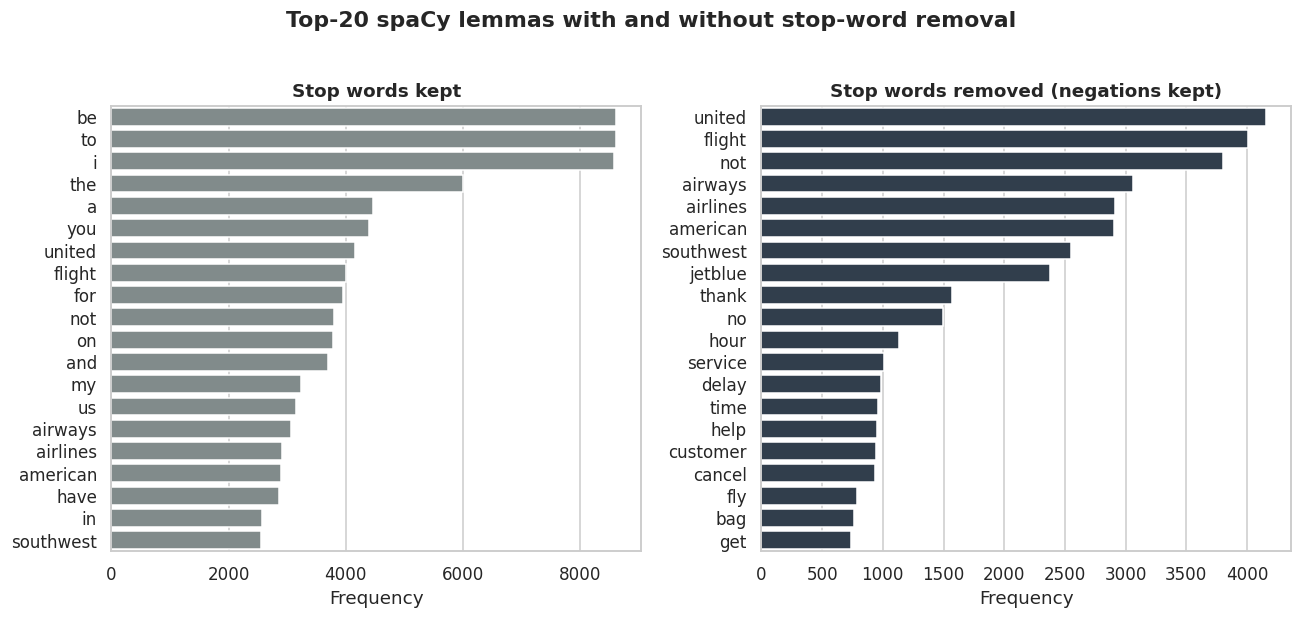

In [28]:
# Calculate token frequency counts before and after stop word removal
kept_counts = Counter(l for ls in df.spacy_lemmas for l in ls)
removed_counts = Counter(l for ls in df.spacy_lemmas_nostop for l in ls)
stop_share = 1 - sum(removed_counts.values()) / sum(kept_counts.values())
print(f"Stop words make up {stop_share:.1%} of all content tokens (spaCy list, negations kept).")

# Initialize subplots for comparing top 20 lemmas before and after stop word removal
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, cnt, title, colour in [(axes[0], kept_counts, "Stop words kept", "#7F8C8D"),
                               (axes[1], removed_counts, "Stop words removed (negations kept)", "#2C3E50")]:
    top = pd.Series(dict(cnt.most_common(20)))
    sns.barplot(x=top.values, y=top.index, color=colour, ax=ax)
    ax.set(title=title, xlabel="Frequency", ylabel="")

# Format figure layout and titles
fig.suptitle("Top-20 spaCy lemmas with and without stop-word removal", fontweight="bold", y=1.02)
plt.tight_layout()

# Save figure and render plots
save_fig("fig1_06_stopword_effect_top_tokens"); plt.show()

Negation words that the DEFAULT lists would delete:
  NLTK : ['no', 'nor', 'not']
  spaCy: ['cannot', "n't", 'neither', 'never', 'no', 'nobody', 'none', 'nor', 'not', 'nothing', 'nowhere', 'without']
Saved figure → figures/task1/fig1_07_negation_by_sentiment.png


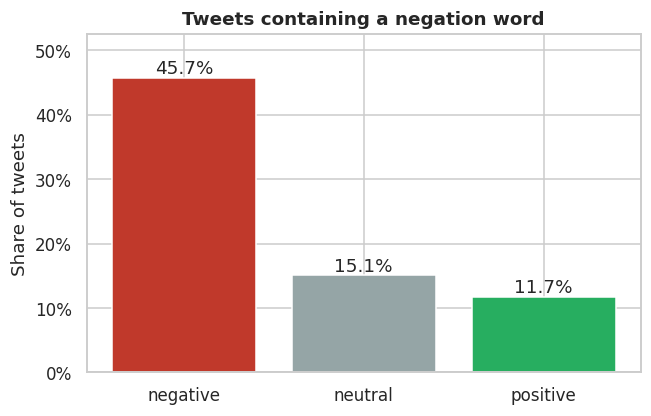

                  empty after removal ≤ 2 tokens left
airline_sentiment                                    
negative                         0.0%            0.9%
neutral                          0.0%            5.4%
positive                         0.0%            5.0%


In [29]:
# Set negation lemmas and display which negations default stop-word lists exclude
NEG_LEMMAS = {"not", "no", "never", "nothing", "nobody", "none", "nor", "neither", "nowhere", "cannot", "without"}
print("Negation words that the DEFAULT lists would delete:")
print("  NLTK :", sorted(NEGATIONS & set(stopwords.words("english"))))
print("  spaCy:", sorted(NEGATIONS & nlp.Defaults.stop_words))

# Identify tweets containing negation terms and compute negation rates per sentiment
df["has_negation"] = df.spacy_lemmas.map(lambda ls: any(l in NEG_LEMMAS for l in ls))
neg_rate = df.groupby("airline_sentiment").has_negation.mean().reindex(SENT_ORDER)

# Create bar plot showing negation word presence across sentiment classes
fig, ax = plt.subplots(figsize=(6.5, 4))
bars = ax.bar(neg_rate.index, neg_rate.values, color=[SENT_PALETTE[s] for s in neg_rate.index])

# Annotate bars with percentage values
for bar, v in zip(bars, neg_rate.values):
    ax.annotate(f"{v:.1%}", (bar.get_x() + bar.get_width() / 2, v), ha="center", va="bottom")

# Format y-axis as percentages and set chart titles and labels
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set(title="Tweets containing a negation word", ylabel="Share of tweets", xlabel="")
ax.margins(y=0.15)

# Save figure and render plot
save_fig("fig1_07_negation_by_sentiment"); plt.show()

# Calculate and display proportions of short or empty tweets post stop-word removal by sentiment
short_after = df.spacy_lemmas_nostop.str.len()
print(pd.DataFrame({
    "empty after removal": df.assign(e=short_after.eq(0)).groupby("airline_sentiment").e.mean().map("{:.1%}".format),
    "≤ 2 tokens left": df.assign(e=short_after.le(2)).groupby("airline_sentiment").e.mean().map("{:.1%}".format),
}).reindex(SENT_ORDER))

## 1.10 Token frequencies, distinctive terms and complaint themes
For visualisation only, airline names and the ubiquitous word *flight* are hidden, because they dominate every class without telling us anything about sentiment. The stored token lists are **not** altered.

Saved figure → figures/task1/fig1_08_top_lemmas_by_sentiment.png


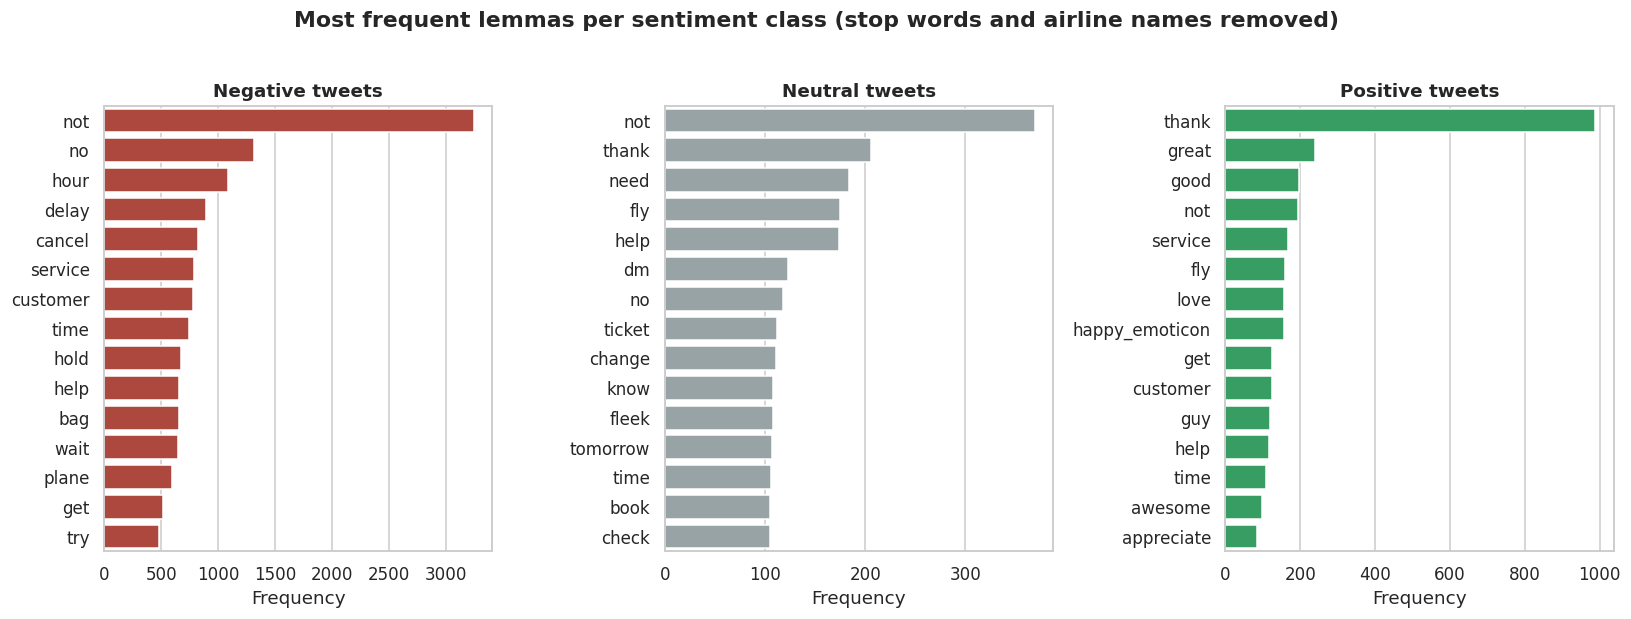

In [30]:
# Define domain-specific stop words to exclude airline names and general aviation terms
DOMAIN_STOP = {"united", "southwest", "delta", "jetblue", "virgin", "america", "american",
               "airlines", "airline", "us", "airways", "usairways", "americanair", "southwestair", "virginamerica"}
CHART_STOP = DOMAIN_STOP | {"flight"}

# Count lemma frequencies per sentiment class excluding domain stop words
class_counts = {s: Counter(l for ls in df.loc[df.airline_sentiment == s, "spacy_lemmas_nostop"]
                           for l in ls if l not in CHART_STOP) for s in SENT_ORDER}

# Initialize grid of horizontal bar charts for each sentiment class
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, s in zip(axes, SENT_ORDER):
    top = pd.Series(dict(class_counts[s].most_common(15)))
    sns.barplot(x=top.values, y=top.index, color=SENT_PALETTE[s], ax=ax)
    ax.set(title=f"{s.capitalize()} tweets", xlabel="Frequency", ylabel="")

# Format overall figure title and layout
fig.suptitle("Most frequent lemmas per sentiment class (stop words and airline names removed)",
             fontweight="bold", y=1.02)
plt.tight_layout()

# Save image file and render plots
save_fig("fig1_08_top_lemmas_by_sentiment"); plt.show()

Raw frequencies are dominated by words shared across classes (*get*, *hour*, *time*). The **weighted log-odds ratio with an informative Dirichlet prior** (Monroe, Colaresi and Quinn, 2008) instead identifies the terms that are *statistically distinctive* for negative versus positive tweets, while controlling for word frequency.

Saved figure → figures/task1/fig1_09_distinctive_terms_logodds.png


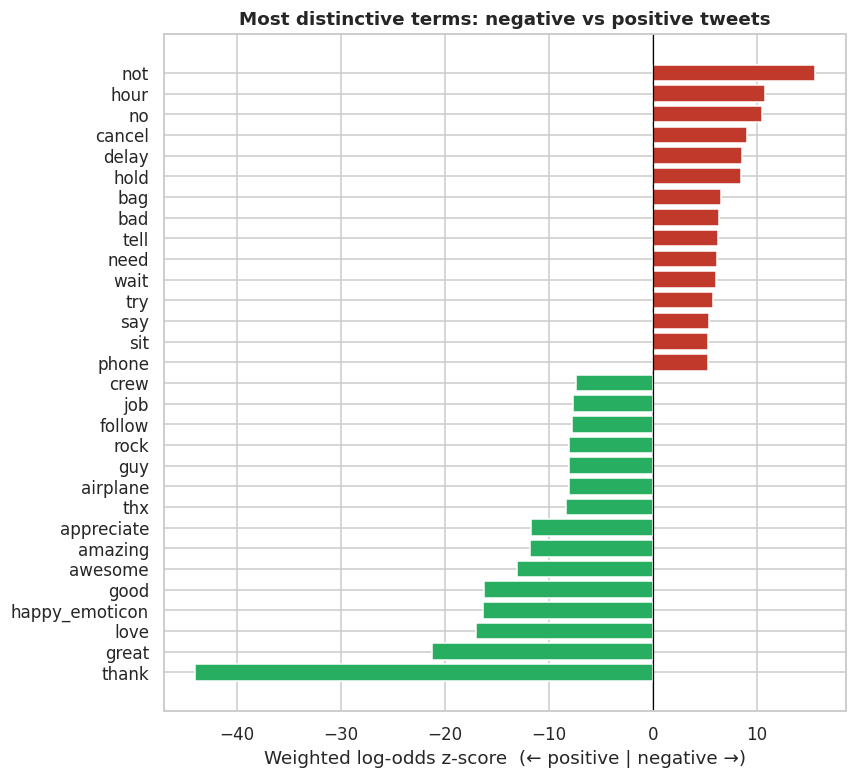

In [31]:
# Compute weighted log-odds z-scores with Dirichlet prior to rank distinctive terms between two corpora
def weighted_log_odds(counts_a, counts_b, alpha0=1000, min_count=10):
    vocab_ = [w for w in set(counts_a) | set(counts_b) if counts_a[w] + counts_b[w] >= min_count]
    pooled = {w: counts_a[w] + counts_b[w] for w in vocab_}
    n_pooled = sum(pooled.values())
    prior = {w: alpha0 * pooled[w] / n_pooled for w in vocab_}
    a0 = sum(prior.values())
    n_a, n_b = sum(counts_a[w] for w in vocab_), sum(counts_b[w] for w in vocab_)
    rows = []
    for w in vocab_:
        ya, yb, aw = counts_a[w], counts_b[w], prior[w]
        delta = (np.log((ya + aw) / (n_a + a0 - ya - aw)) - np.log((yb + aw) / (n_b + a0 - yb - aw)))
        rows.append((w, delta / np.sqrt(1 / (ya + aw) + 1 / (yb + aw))))
    return pd.DataFrame(rows, columns=["term", "z"]).sort_values("z")

# Calculate log-odds z-scores between negative and positive sentiment classes
lo = weighted_log_odds(class_counts["negative"], class_counts["positive"])
top_lo = pd.concat([lo.head(15), lo.tail(15)])

# Plot top distinctive terms for negative vs positive tweets in horizontal bar chart
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(top_lo.term, top_lo.z, color=[SENT_PALETTE["negative"] if z > 0 else SENT_PALETTE["positive"] for z in top_lo.z])

# Add vertical baseline, title, and axis labels
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Most distinctive terms: negative vs positive tweets",
       xlabel="Weighted log-odds z-score  (← positive | negative →)", ylabel="")

# Save plot figure and render output
save_fig("fig1_09_distinctive_terms_logodds"); plt.show()

Saved figure → figures/task1/fig1_10_negative_bigrams.png


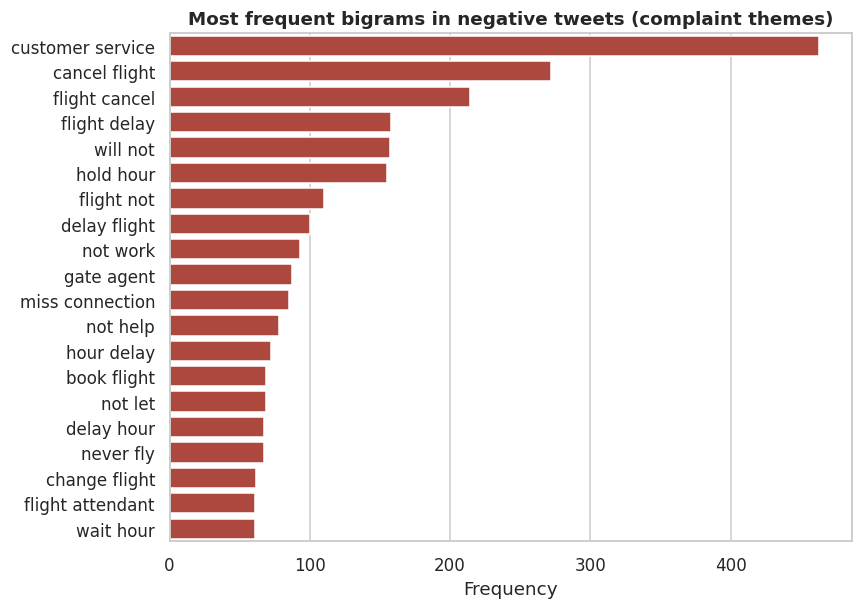

In [32]:
# Helper function to generate contiguous n-grams from a sequence of tokens
def ngrams(seq, n=2):
    return zip(*(seq[i:] for i in range(n)))

# Extract and count top bigram frequencies from negative tweets excluding domain stop words
neg_mask = df.airline_sentiment == "negative"
neg_bigrams = Counter(" ".join(bg) for ls in df.loc[neg_mask, "spacy_lemmas_nostop"]
                      for bg in ngrams([l for l in ls if l not in DOMAIN_STOP]))
top_bg = pd.Series(dict(neg_bigrams.most_common(20)))

# Create horizontal bar plot showing most frequent complaint bigrams
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=top_bg.values, y=top_bg.index, color=SENT_PALETTE["negative"], ax=ax)

# Set chart title and axis labels
ax.set(title="Most frequent bigrams in negative tweets (complaint themes)", xlabel="Frequency", ylabel="")

# Save figure and render plot
save_fig("fig1_10_negative_bigrams"); plt.show()

Saved figure → figures/task1/fig1_11_wordclouds.png


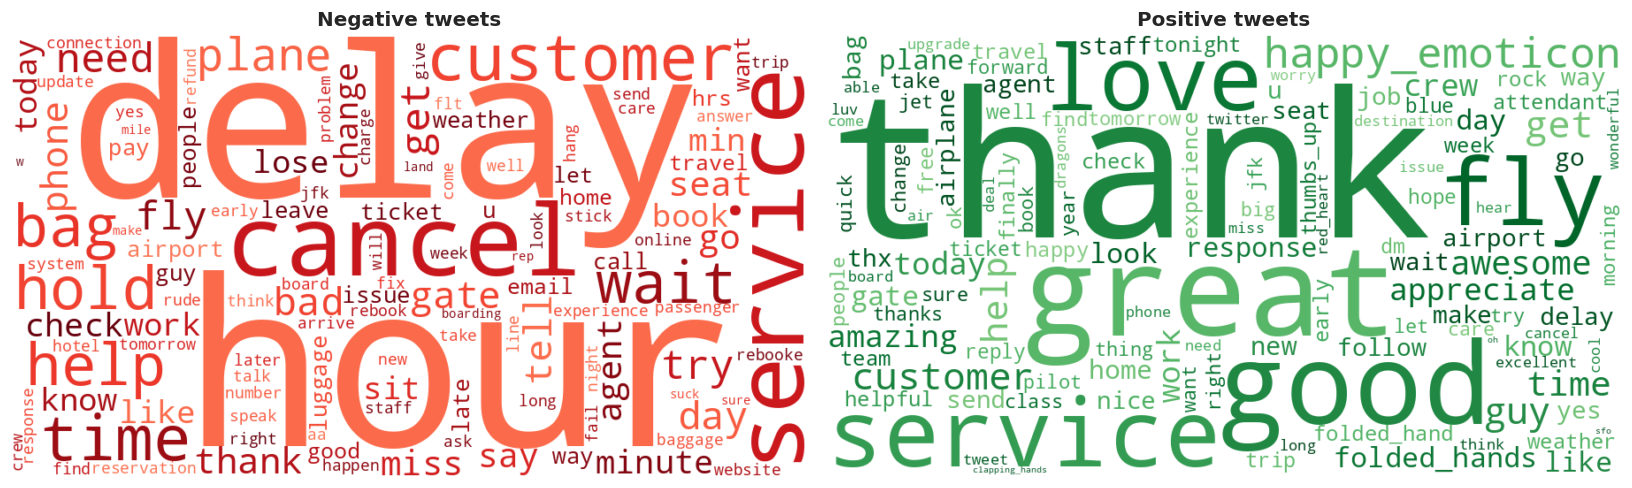

In [33]:
# Initialize subplots for negative and positive word clouds
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Truncate sequential colormaps to exclude light end-colors for text legibility
def dark_cmap(name, start=0.45):
    return ListedColormap(plt.get_cmap(name)(np.linspace(start, 1, 256)))

# Generate and plot sentiment-specific word clouds excluding negation words
for ax, s, cmap in [(axes[0], "negative", dark_cmap("Reds")), (axes[1], "positive", dark_cmap("Greens"))]:
    freqs = {w: n for w, n in class_counts[s].items() if w not in NEG_LEMMAS}
    wc = WordCloud(width=900, height=500, background_color="white", colormap=cmap,
                   max_words=120, random_state=SEED).generate_from_frequencies(freqs)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(f"{s.capitalize()} tweets", fontsize=13, fontweight="bold")
    ax.axis("off")

# Apply tight layout, save visualization, and display figure
plt.tight_layout()
save_fig("fig1_11_wordclouds"); plt.show()

Saved figure → figures/task1/fig1_12_length_distribution.png


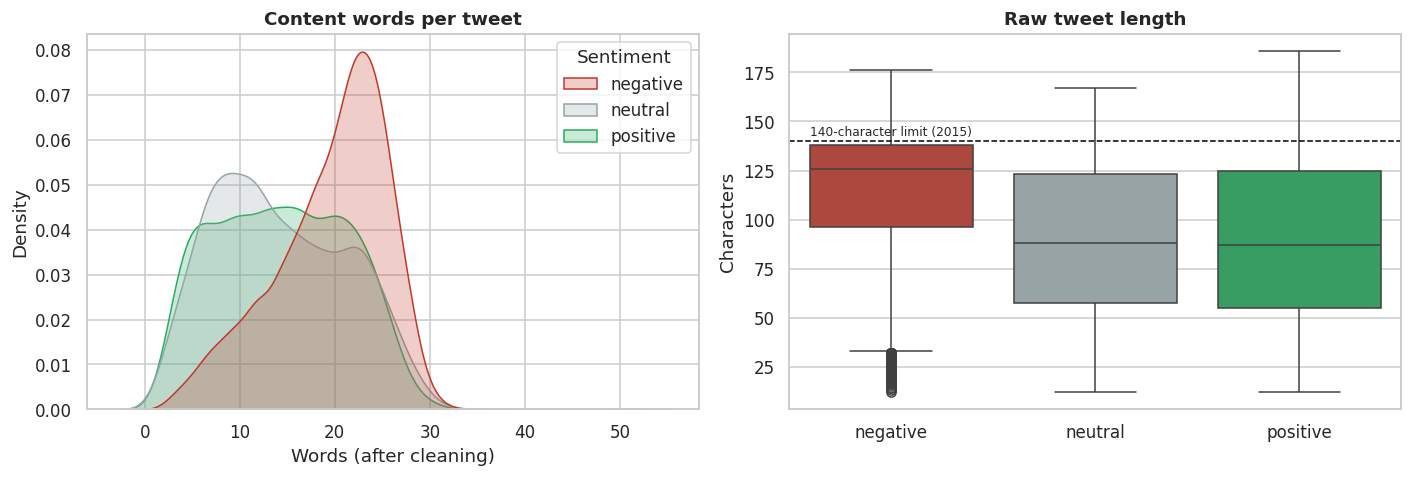

n_words                         n_chars                \
                     mean   50%   95%   99%   max    mean    50%    95%   
airline_sentiment                                                         
negative             19.5  21.0  27.0  29.0  33.0   113.9  126.0  146.0   
neutral              14.2  13.0  26.0  29.0  33.0    87.7   88.0  140.0   
positive             14.3  14.0  25.0  28.0  51.0    87.4   87.0  140.0   

                                 
                     99%    max  
airline_sentiment                
negative           154.0  176.0  
neutral            146.5  167.0  
positive           146.0  186.0

→ 99% of tweets have ≤ 29 content words; useful for choosing max_length for transformer tokenisation in Task 4.


In [34]:
# Compute character and word length metrics per tweet
df["n_chars"] = df.text_raw.str.len()
df["n_words"] = df.spacy_lemmas.str.len()

# Initialize subplots for word density and raw character length distributions
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Plot kernel density estimates of content word counts by sentiment class
sns.kdeplot(data=df, x="n_words", hue="airline_sentiment", hue_order=SENT_ORDER, palette=SENT_PALETTE,
            common_norm=False, fill=True, alpha=0.25, ax=axes[0])
sns.move_legend(axes[0], "upper right", title="Sentiment")
axes[0].set(title="Content words per tweet", xlabel="Words (after cleaning)", ylabel="Density")

# Plot boxplots of raw character lengths against Twitter's historical 140-character limit
sns.boxplot(data=df, x="airline_sentiment", y="n_chars", hue="airline_sentiment", order=SENT_ORDER,
            palette=SENT_PALETTE, legend=False, ax=axes[1])
axes[1].axhline(140, ls="--", c="black", lw=1)
axes[1].text(-0.4, 143, "140-character limit (2015)", fontsize=8)
axes[1].set(title="Raw tweet length", xlabel="", ylabel="Characters")

# Format layout, save figure, and render length distribution plots
plt.tight_layout()
save_fig("fig1_12_length_distribution"); plt.show()

# Calculate summary length statistics and display percentiles for model tokenization limits
length_stats = df.groupby("airline_sentiment")[["n_words", "n_chars"]].describe(percentiles=[.5, .95, .99])
display(length_stats.loc[SENT_ORDER, (slice(None), ["mean", "50%", "95%", "99%", "max"])].round(1))
print("→ 99% of tweets have ≤", int(df.n_words.quantile(.99)), "content words; "
      "useful for choosing max_length for transformer tokenisation in Task 4.")

## 1.11 Named Entity Recognition with spaCy

Tweets with ≥1 entity: 82.9% | entity types used: 18
Saved figure → figures/task1/fig1_13_entity_type_frequency.png


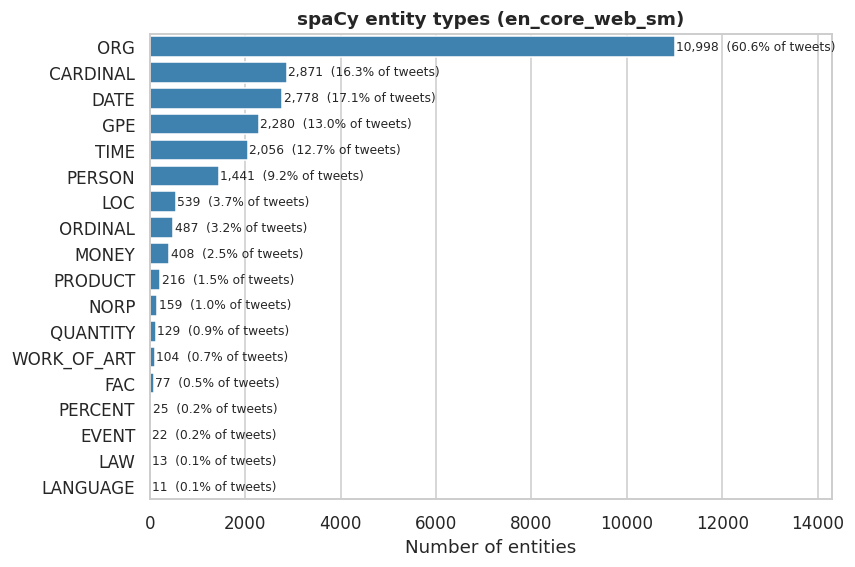

In [35]:
# Compute entity frequencies and the proportion of tweets containing each entity type
ent_counts = Counter(label for ents in df.spacy_ents for _, label in ents)
tweet_share = {lab: df.spacy_ents.map(lambda es, lab=lab: any(l == lab for _, l in es)).mean() for lab in ent_counts}
ent_df = pd.DataFrame({"entities": ent_counts, "tweets_%": tweet_share}).sort_values("entities", ascending=False)
print(f"Tweets with ≥1 entity: {df.spacy_ents.map(bool).mean():.1%} | entity types used: {len(ent_df)}")

# Initialize horizontal bar chart for spaCy entity type frequencies
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.barplot(x=ent_df.entities, y=ent_df.index, color="#2E86C1", ax=ax)

# Annotate bars with total entity counts and tweet percentage shares
for i, (n, share) in enumerate(zip(ent_df.entities, ent_df["tweets_%"])):
    ax.text(n + 30, i, f"{n:,}  ({share:.1%} of tweets)", va="center", fontsize=8)

# Set chart title, axis labels, and right margin spacing
ax.set(title="spaCy entity types (en_core_web_sm)", xlabel="Number of entities", ylabel="")
ax.margins(x=0.3)

# Save visualization figure and display output
save_fig("fig1_13_entity_type_frequency"); plt.show()

In [36]:
# Select key named entity types relevant to airline customer feedback analysis
KEY_TYPES = ["ORG", "GPE", "PERSON", "DATE", "TIME", "MONEY", "CARDINAL"]

# Count most frequent surface forms per key entity type and pad short lists to length 8
top_entities = {}
for lab in KEY_TYPES:
    c = Counter(t for es in df.spacy_ents for t, l in es if l == lab)
    top_entities[lab] = [f"{t} ({n})" for t, n in c.most_common(8)] + [""] * (8 - min(8, len(c)))

# Display summary DataFrame showing top entity surface forms per category
pd.DataFrame(top_entities)

,ORG,GPE,PERSON,DATE,TIME,MONEY,CARDINAL
0,US Airways (2477),US (341),JFK (137),today (377),tonight (144),200 (37),2 (311)
1,American Airlines (2389),Dallas (79),thumbs_up (33),tomorrow (262),an hour (83),25 (20),one (158)
2,JetBlue (589),Boston (74),Vegas (29),yesterday (100),2 hours (76),50 (17),4 (142)
3,United (559),Denver (70),Twitter (29),Monday (41),this morning (62),100 (13),3 (136)
4,DM (120),Chicago (69),Jet Blue (21),all day (34),3 hours (50),75 (13),1 (109)
5,Virgin America (113),Newark (57),jfk (19),2 days (34),last night (44),150 (10),two (99)
6,DFW (113),Charlotte (52),Austin (18),Sunday (33),4 hours (33),8 (9),5 (65)
7,US Airways American Airlines (97),Houston (48),WiFi (14),Tuesday (29),hours (30),400 (8),10 (51)


**Audit: how does the generic model label the airline names?** Every airline handle was replaced by its canonical name in 1.5, so we know exactly where the airlines are mentioned. This allows a direct test of the model on the single most important entity type for this domain.

Saved figure → figures/task1/fig1_14_airline_ner_audit.png


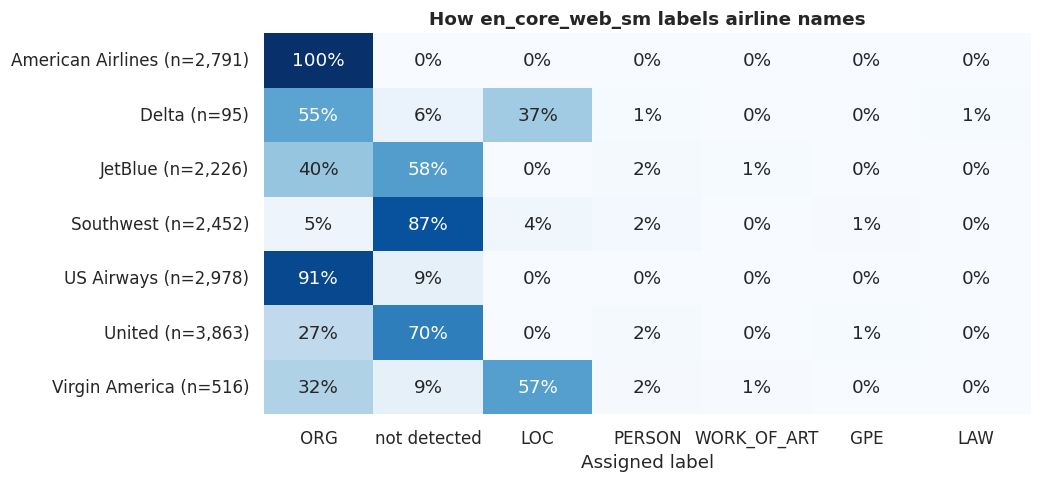

Airline mentions correctly labelled ORG: 51.9% of 14,921 mentions


In [37]:
# Sort airline names by length in descending order to prevent partial string matching
AIRLINE_NAMES = sorted(set(AIRLINE_HANDLES.values()), key=len, reverse=True)

# Audit spaCy named entity recognition labels assigned to airline name mentions
rows = []
for text, ents in zip(df.text_clean, df.spacy_ents):
    for name in AIRLINE_NAMES:
        if re.search(rf"\b{re.escape(name)}\b", text):
            label = next((l for t, l in ents if name in t), "not detected")
            rows.append((name, label))

# Build normalized cross-tabulation table of airline names versus detected NER labels
airline_ner = pd.crosstab(*zip(*rows), normalize="index", rownames=["airline name"], colnames=["spaCy label"])
airline_ner = airline_ner[airline_ner.sum().sort_values(ascending=False).index[:7]]
mentions_per_name = Counter(name for name, _ in rows)
airline_ner.index = [f"{name} (n={mentions_per_name[name]:,})" for name in airline_ner.index]

# Plot heatmap displaying spaCy entity label distributions across airline names
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(airline_ner, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=ax)
ax.set(title="How en_core_web_sm labels airline names", xlabel="Assigned label", ylabel="")

# Save heatmap visualization and render output
save_fig("fig1_14_airline_ner_audit"); plt.show()

# Calculate and print overall proportion of airline mentions correctly classified as ORG
correct = np.mean([l == "ORG" for _, l in rows])
print(f"Airline mentions correctly labelled ORG: {correct:.1%} of {len(rows):,} mentions")

Saved figure → figures/task1/fig1_15_entity_prevalence_by_sentiment.png


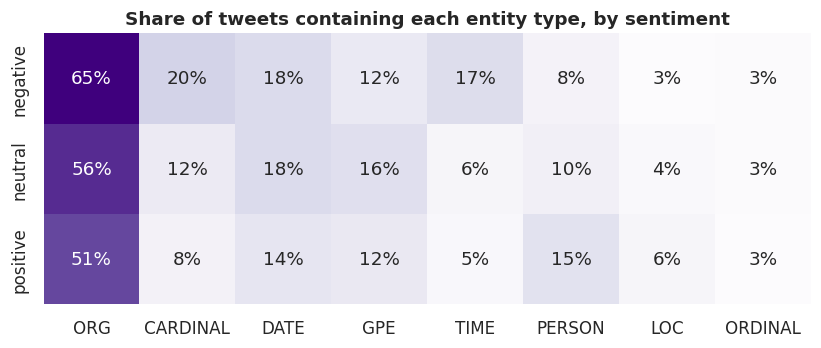

In [38]:
# Which entity types co-occur with which sentiment?  (Hypothesis for Task 2 NER features)
top_labels = [l for l, _ in ent_counts.most_common(8)]
prevalence = pd.DataFrame({lab: df.spacy_ents.map(lambda es, lab=lab: any(l == lab for _, l in es))
                           for lab in top_labels})
prevalence["sentiment"] = df.airline_sentiment
heat = prevalence.groupby("sentiment")[top_labels].mean().reindex(SENT_ORDER)

fig, ax = plt.subplots(figsize=(9, 3.2))
sns.heatmap(heat, annot=True, fmt=".0%", cmap="Purples", cbar=False, ax=ax)
ax.set(title="Share of tweets containing each entity type, by sentiment", xlabel="", ylabel="")
save_fig("fig1_15_entity_prevalence_by_sentiment"); plt.show()

In [39]:
# Filter negative tweets containing at least three distinct named entity types
demo = df[(df.airline_sentiment == "negative") & (df.spacy_ents.map(lambda es: len({l for _, l in es}) >= 3))]

# Process sample tweets through spaCy pipeline for entity visualization
docs = list(nlp.pipe(demo.text_clean.sample(3, random_state=SEED)))

# Render interactive named entity visualizations using spaCy's displacy
displacy.render(docs, style="ent", jupyter=True)

## 1.12 Domain adaptation with a spaCy EntityRuler
The audit above shows that a general-purpose NER model is unreliable on brand names and has no notion of *service-related terms*. A rule-based `EntityRuler` placed **before** the statistical NER adds three domain labels:

* `AIRLINE`: carrier names
* `SERVICE`: service touchpoints (baggage, check-in, gate agent, Wi-Fi, refund …)
* `ISSUE`: failure terms (delayed, cancelled, lost, stranded …)

The statistical model keeps detecting generic types such as `GPE`, `DATE`, `TIME` and `MONEY`. This hybrid design is cheap, transparent and auditable, but it is context-blind (e.g. *"lost"* in *"lost for words"*). That trade-off is worth discussing in Task 5.

In [40]:
# Define domain-specific vocabulary lists for customer service, operational issues, and airline entities
SERVICE_TERMS = ["customer service", "customer care", "agent", "gate agent", "flight attendant",
                 "flight attendants", "crew", "pilot", "baggage", "bag", "bags", "luggage", "suitcase",
                 "check-in", "check in", "boarding", "boarding pass", "gate", "seat", "seats", "legroom",
                 "wifi", "wi-fi", "entertainment", "refund", "voucher", "miles", "reservation", "booking",
                 "rebooking", "upgrade", "lounge", "app", "website", "phone", "email", "dm"]
ISSUE_TERMS = ["delay", "delayed", "delays", "late", "cancel", "cancelled", "canceled", "cancellation",
               "cancellations", "lost", "missing", "damaged", "broken", "overbooked", "stuck", "stranded",
               "missed connection", "diverted", "on hold", "rude", "waiting"]
AIRLINE_TERMS = list(AIRLINE_NAMES) + ["jet blue", "southwest airlines", "united airlines", "virgin", "american"]

# Construct rule patterns for EntityRuler matching
patterns = ([{"label": "AIRLINE", "pattern": p} for p in AIRLINE_TERMS] +
            [{"label": "SERVICE", "pattern": p} for p in SERVICE_TERMS] +
            [{"label": "ISSUE", "pattern": p} for p in ISSUE_TERMS])

# Initialize lightweight spaCy pipeline and add case-insensitive EntityRuler before standard NER
nlp_ruled = spacy.load("en_core_web_sm", exclude=["parser", "tagger", "attribute_ruler", "lemmatizer"])
ruler = nlp_ruled.add_pipe("entity_ruler", before="ner", config={"phrase_matcher_attr": "LOWER"})
ruler.add_patterns(patterns)
print("Pipeline:", nlp_ruled.pipe_names, "| patterns:", len(patterns))

# Process text corpus using EntityRuler pipeline and compute custom entity category prevalence rates
df["spacy_ents_ruled"] = [[(e.text, e.label_) for e in doc.ents]
                          for doc in nlp_ruled.pipe(df.text_clean, batch_size=256)]
for lab in ["AIRLINE", "SERVICE", "ISSUE"]:
    share_ = df.spacy_ents_ruled.map(lambda es, lab=lab: any(l == lab for _, l in es)).mean()
    print(f"Tweets with ≥1 {lab:<8}: {share_:.1%}")

Pipeline: ['tok2vec', 'entity_ruler', 'ner'] | patterns: 70
Tweets with ≥1 AIRLINE : 100.0%
Tweets with ≥1 SERVICE : 33.0%
Tweets with ≥1 ISSUE   : 22.6%


Saved figure → figures/task1/fig1_16_entityruler_before_after.png


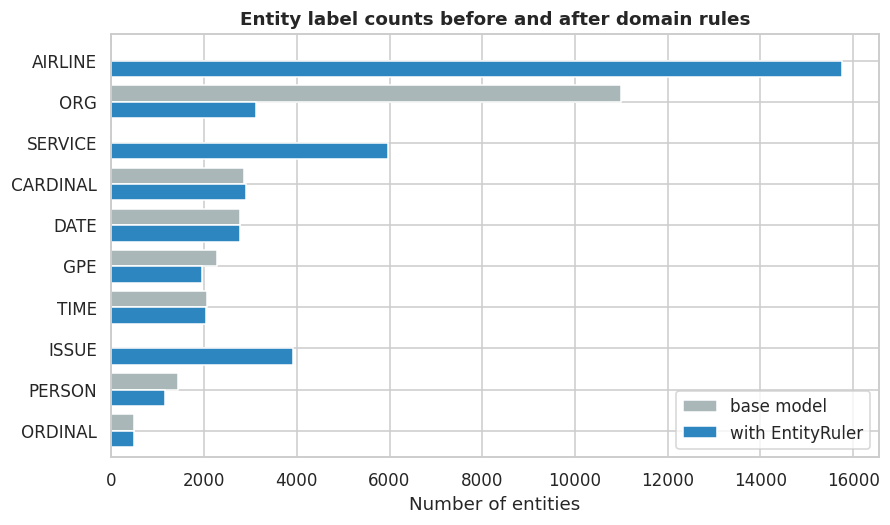

,base model,with EntityRuler
AIRLINE,0,15761
ORG,10998,3117
SERVICE,0,5958
CARDINAL,2871,2894
DATE,2778,2767
GPE,2280,1954
TIME,2056,2049
ISSUE,0,3911
PERSON,1441,1167
ORDINAL,487,495


In [41]:
# Compute entity label frequency counts before and after applying custom EntityRuler patterns
before = Counter(l for es in df.spacy_ents for _, l in es)
after = Counter(l for es in df.spacy_ents_ruled for _, l in es)
labels = [l for l, _ in (after + before).most_common(10)]
cmp_ner = pd.DataFrame({"base model": [before[l] for l in labels],
                        "with EntityRuler": [after[l] for l in labels]}, index=labels)

# Initialize horizontal grouped bar plot comparing base model vs EntityRuler entity counts
fig, ax = plt.subplots(figsize=(9, 5))
cmp_ner.plot(kind="barh", ax=ax, color=["#AAB7B8", "#2E86C1"], width=0.8)

# Format chart layout, invert y-axis, and set labels
ax.invert_yaxis()
ax.set(title="Entity label counts before and after domain rules", xlabel="Number of entities", ylabel="")

# Save plot visualization and display output
save_fig("fig1_16_entityruler_before_after"); plt.show()
cmp_ner

Saved figure → figures/task1/fig1_17_service_issue_terms.png


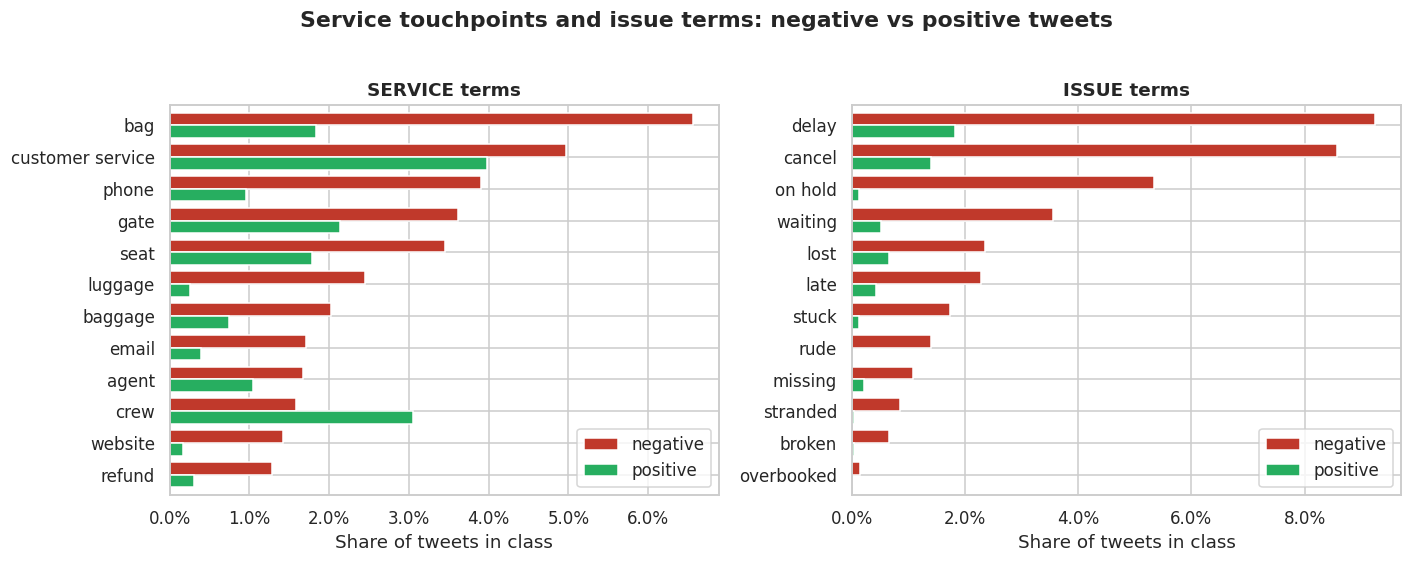

In [42]:
# Map term variations to canonical forms for consistent aggregation across entity categories
NORMALISE = {"bags": "bag", "seats": "seat", "delays": "delay", "delayed": "delay", "canceled": "cancel",
             "cancelled": "cancel", "cancellation": "cancel", "cancellations": "cancel",
             "flight attendants": "flight attendant", "wi-fi": "wifi", "check in": "check-in"}

# Calculate proportion of tweets containing each normalized entity term within a sentiment group
def term_share(mask, label):
    term_sets = df.loc[mask, "spacy_ents_ruled"].map(
        lambda es: {NORMALISE.get(t.lower(), t.lower()) for t, l in es if l == label})
    return pd.Series(Counter(t for s in term_sets for t in s)) / mask.sum()

# Initialize subplots for SERVICE and ISSUE entity category comparisons
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot top service and issue term proportions for negative vs positive sentiment classes
for ax, label in zip(axes, ["SERVICE", "ISSUE"]):
    share_df = pd.DataFrame({"negative": term_share(neg_mask, label),
                             "positive": term_share(df.airline_sentiment == "positive", label)}).fillna(0)
    share_df = share_df.sort_values("negative", ascending=False).head(12)
    share_df.plot(kind="barh", ax=ax, color=[SENT_PALETTE["negative"], SENT_PALETTE["positive"]], width=0.8)
    ax.invert_yaxis()
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set(title=f"{label} terms", xlabel="Share of tweets in class", ylabel="")

# Format figure layout, title, and save visualization output
fig.suptitle("Service touchpoints and issue terms: negative vs positive tweets", fontweight="bold", y=1.02)
plt.tight_layout()
save_fig("fig1_17_service_issue_terms"); plt.show()

In [43]:
# Define key NER labels to extract as quantitative feature columns
FEATURE_LABELS = ["ORG", "GPE", "PERSON", "DATE", "TIME", "MONEY", "CARDINAL", "AIRLINE", "SERVICE", "ISSUE"]

# Count occurrences of each entity label per tweet and store as new feature columns
for lab in FEATURE_LABELS:
    df[f"ent_{lab}"] = df.spacy_ents_ruled.map(lambda es, lab=lab: sum(l == lab for _, l in es))

# Display summary statistics (mean and max) for generated entity count features
df[[f"ent_{l}" for l in FEATURE_LABELS]].describe().T[["mean", "max"]].round(2)

,mean,max
ent_ORG,0.22,6.0
ent_GPE,0.14,5.0
ent_PERSON,0.08,5.0
ent_DATE,0.19,4.0
ent_TIME,0.14,4.0
ent_MONEY,0.03,4.0
ent_CARDINAL,0.20,5.0
ent_AIRLINE,1.09,5.0
ent_SERVICE,0.41,5.0
ent_ISSUE,0.27,5.0


## 1.13 Save processed data for Tasks 2–4


In [44]:
# Specify the subset of processed columns to retain in the final dataset
KEEP = (["tweet_id", "airline", "airline_plot", "airline_sentiment", "airline_sentiment_confidence",
         "low_confidence", "negativereason", "negativereason_confidence", "tweet_created",
         "text_raw", "text_repaired", "text_clean", "text_masked",
         "nltk_lemmas_nostop", "spacy_lemmas", "spacy_lemmas_nostop", "spacy_ents", "spacy_ents_ruled",
         "has_negation", "n_chars", "n_words"] + [f"ent_{l}" for l in FEATURE_LABELS])

# Create a clean copy of the dataframe with the selected feature set
processed = df[KEEP].copy()

# Save the full processed dataset including list-valued columns as a Pickle file
processed.to_pickle(os.path.join(OUT_DIR, "tweets_task1.pkl"))

# Identify list-valued columns and export a lightweight CSV without complex structures
list_cols = [c for c in KEEP if "lemmas" in c or c.startswith("spacy_ents")]
processed.drop(columns=list_cols).to_csv(os.path.join(OUT_DIR, "tweets_task1_light.csv"), index=False)

# Display export confirmation with row/column metrics and list saved plot files
print(f"Saved {len(processed):,} rows × {processed.shape[1]} columns to {OUT_DIR}/")
print("Figures:", sorted(os.listdir(FIG_DIR)))

Saved 14,427 rows × 31 columns to outputs/
Figures: ['fig1_01_sentiment_distribution.png', 'fig1_02_sentiment_by_airline.png', 'fig1_03_negative_reasons.png', 'fig1_04_reason_by_airline_heatmap.png', 'fig1_05_label_confidence.png', 'fig1_06_stopword_effect_top_tokens.png', 'fig1_07_negation_by_sentiment.png', 'fig1_08_top_lemmas_by_sentiment.png', 'fig1_09_distinctive_terms_logodds.png', 'fig1_10_negative_bigrams.png', 'fig1_11_wordclouds.png', 'fig1_12_length_distribution.png', 'fig1_13_entity_type_frequency.png', 'fig1_14_airline_ner_audit.png', 'fig1_15_entity_prevalence_by_sentiment.png', 'fig1_16_entityruler_before_after.png', 'fig1_17_service_issue_terms.png']


# Task 2: Classical NLP Baseline for Sentiment Classification
**Dataset:** Twitter US Airline Sentiment, cleaned in Task 1 (`tweets_task1.pkl`, 14,427 tweets)
**Task:** 3-class sentiment classification (negative / neutral / positive)

| Section | Content |
|---|---|
| 2.0 | Set-up and loading the Task 1 output |
| 2.1 | Fixed train/test split (re-used in Task 4 for a fair comparison) |
| 2.2 | Preprocessing ablation: which Task 1 text representation works best for TF-IDF? |
| 2.3 | Three classical models (Logistic Regression, Linear SVM, Complement Naive Bayes) with cross-validated tuning |
| 2.4 | Test-set evaluation: accuracy, precision, recall, F1, confusion matrices, bootstrap confidence intervals |
| 2.5 | Interpretability: what the model has learned |
| 2.6 | Error analysis and misclassified examples |
| 2.7 | Optional: do NER features help? |
| 2.8 | Slices relevant to Task 5: urgent complaint types, airlines, and an airline-bias mitigation test |
| 2.9 | Learning curve (links to the 1,000–5,000 example budget of Task 4) |
| 2.10 | Model comparison for business use, and saving outputs |

**Primary metric: macro-F1.** The classes are imbalanced (63% negative), so accuracy rewards a model that ignores the minority classes. Macro-F1 weights every class equally.

## 2.0 Set-up

In [45]:
# Import core system, array manipulation, and data collection utilities
import os, json, time, pickle, warnings
from collections import Counter

# Import data handling and visualization packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
import joblib

# Import Scikit-Learn tools for modeling, feature engineering, and evaluation
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix)

# Set global random seeds and suppress non-critical warnings
SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore")

# Define and create output directories for figure exports and model artifacts
FIG_DIR, OUT_DIR = "figures/task2", "outputs"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# Configure Seaborn and Matplotlib visualization themes, DPI settings, and palette mappings
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.titleweight": "bold", "axes.titlesize": 12})
SENT_ORDER = ["negative", "neutral", "positive"]
SENT_PALETTE = {"negative": "#C0392B", "neutral": "#95A5A6", "positive": "#27AE60"}
MODEL_PALETTE = {"Logistic Regression": "#2E86C1", "Linear SVM": "#8E44AD", "Complement NB": "#D68910"}
pd.set_option("display.max_colwidth", 160)

# Helper function to save generated plots to the task output directory
def save_fig(name):
    path = os.path.join(FIG_DIR, f"{name}.png")
    plt.savefig(path)
    print(f"Saved figure → {path}")

`tweets_task1.pkl` was written to `outputs/` by Task 1, so it loads directly. The upload dialog only appears if this section is run on its own in a new session.

In [46]:
# Set filename and potential file paths for loading the Task 1 processed dataset
PKL = "tweets_task1.pkl"
CANDIDATES = [os.path.join(OUT_DIR, PKL), PKL, f"/content/drive/MyDrive/nlp_assignment/outputs/{PKL}"]

# Function to locate and load the pickled Task 1 dataframe or prompt Google Colab upload
def load_task1_output():
    for path in CANDIDATES:
        if os.path.exists(path):
            print(f"Loading {path}")
            return pd.read_pickle(path)
    print(f"{PKL} not found. Please upload it (it is in the task1_tables.zip from Task 1).")
    from google.colab import files
    uploaded = files.upload()
    name = next(iter(uploaded))
    os.replace(name, os.path.join(OUT_DIR, PKL))
    return pd.read_pickle(os.path.join(OUT_DIR, PKL))

# Load preprocessed dataset, reset index, and display summary metrics with initial rows
df = load_task1_output().reset_index(drop=True)
print(f"{len(df):,} tweets | columns: {df.shape[1]}")
df[["airline_sentiment", "text_clean", "spacy_lemmas_nostop"]].head(3)

Loading outputs/tweets_task1.pkl
14,427 tweets | columns: 31


,airline_sentiment,text_clean,spacy_lemmas_nostop
0,neutral,Virgin America What said.,"[virgin, america, say]"
1,positive,Virgin America plus you've added commercials to the experience... tacky.,"[virgin, america, plus, add, commercial, experience, tacky]"
2,neutral,Virgin America I didn't today... Must mean I need to take another trip!,"[virgin, america, not, today, mean, need, trip]"


## 2.1 Fixed train/test split
A stratified 80/20 split is created **once** and saved to `outputs/task2_split.csv`. Task 4 must evaluate on exactly these test tweets, otherwise the classical-vs-transformer comparison would not be fair. A stratified 5,000-tweet training subsample is saved too, so Task 4's transformer and a classical model can be trained on the *same* small sample (Section 2.9).

The test set is touched only once, in Section 2.4. Every modelling decision before that uses 5-fold cross-validation on the training set.

In [47]:
# Create stratified train-test indices and a 5k stratified training subset
train_idx, test_idx = train_test_split(df.index, test_size=0.20, stratify=df.airline_sentiment,
                                       random_state=SEED)
sub5k_idx, _ = train_test_split(train_idx, train_size=5000, stratify=df.loc[train_idx, "airline_sentiment"],
                                random_state=SEED)

# Tag dataset splits and save split mapping metadata to CSV
df["split"] = "train"
df.loc[test_idx, "split"] = "test"
df["in_train_5k"] = df.index.isin(sub5k_idx)
df[["tweet_id", "split", "in_train_5k"]].to_csv(os.path.join(OUT_DIR, "task2_split.csv"), index=False)

# Subset train and test DataFrames and extract sentiment targets as plain NumPy string arrays
train, test = df.loc[train_idx].copy(), df.loc[test_idx].copy()
y_train, y_test = train.airline_sentiment.to_numpy(dtype=str), test.airline_sentiment.to_numpy(dtype=str)

# Calculate and display class balance distributions and sample sizes across dataset splits
split_summary = pd.DataFrame({
    "train": train.airline_sentiment.value_counts(normalize=True),
    "test": test.airline_sentiment.value_counts(normalize=True),
    "train 5k sample": df.loc[sub5k_idx, "airline_sentiment"].value_counts(normalize=True),
}).reindex(SENT_ORDER).map("{:.1%}".format)
split_summary.loc["n"] = [len(train), len(test), len(sub5k_idx)]
split_summary

,train,test,train 5k sample
airline_sentiment,,,
negative,62.9%,63.0%,62.9%
neutral,21.2%,21.2%,21.2%
positive,15.9%,15.9%,15.9%
n,11541,2886,5000


## 2.2 Preprocessing ablation: which text representation works best?
This tests the Task 1 preprocessing choices directly against classification performance. The model and TF-IDF settings are held fixed: Logistic Regression, word unigrams and bigrams, sublinear TF. Only the input text changes:

| Variant | Input |
|---|---|
| A | Cleaned text, every word kept |
| B | spaCy lemmas, stop words kept |
| C | spaCy lemmas, stop words removed, **negations kept** (Task 1 default) |
| D | spaCy lemmas, stop words **and negations** removed (a default stop list) |
| E | Cleaned text with airline names masked (`text_masked`) |

Comparing C and D measures the value of keeping negations. Comparing A and E measures how much the model relies on airline identity.

In [48]:
# Set up candidate text representations for the ablation study
NEG_LEMMAS = {"not", "no", "never", "nothing", "nobody", "none", "nor", "neither", "nowhere", "cannot", "without"}

df["in_A"] = df.text_clean
df["in_B"] = df.spacy_lemmas.map(" ".join)
df["in_C"] = df.spacy_lemmas_nostop.map(" ".join)
df["in_D"] = df.spacy_lemmas_nostop.map(lambda ls: " ".join(l for l in ls if l not in NEG_LEMMAS))
df["in_E"] = df.text_masked
VARIANTS = {"A": "Cleaned text (all words)", "B": "Lemmas, stop words kept",
            "C": "Lemmas, stop words removed, negations kept", "D": "Lemmas, stop words + negations removed",
            "E": "Cleaned text, airline names masked"}
train, test = df.loc[train_idx].copy(), df.loc[test_idx].copy()

# Regex pattern to retain contractions and multi-letter words while filtering single characters
TOKEN_PATTERN = r"(?u)\b\w[\w']+\b"

# Helper function to construct standard sublinear TF-IDF vectorizers
def make_tfidf(ngram_range=(1, 2), min_df=2):
    return TfidfVectorizer(lowercase=True, token_pattern=TOKEN_PATTERN, ngram_range=ngram_range,
                           min_df=min_df, sublinear_tf=True, strip_accents="unicode")

# Initialize 5-fold stratified cross-validation splitter
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Evaluate macro F1 performance across text input variants using cross-validation
ablation = []
for key, label in VARIANTS.items():
    pipe = Pipeline([("tfidf", make_tfidf()),
                     ("clf", LogisticRegression(max_iter=3000, class_weight="balanced", C=5))])
    scores = cross_val_score(pipe, train[f"in_{key}"], y_train, cv=CV, scoring="f1_macro", n_jobs=-1)
    n_feat = len(make_tfidf().fit(train[f"in_{key}"]).vocabulary_)
    ablation.append({"variant": key, "input": label, "macro_F1_mean": scores.mean(),
                     "macro_F1_sd": scores.std(), "n_features": n_feat})
    print(f"{key}: {label:<45} macro-F1 = {scores.mean():.4f} ± {scores.std():.4f}  ({n_feat:,} features)")
ablation = pd.DataFrame(ablation).set_index("variant")

A: Cleaned text (all words)                      macro-F1 = 0.7510 ± 0.0057  (25,118 features)
B: Lemmas, stop words kept                       macro-F1 = 0.7542 ± 0.0075  (22,355 features)
C: Lemmas, stop words removed, negations kept    macro-F1 = 0.7281 ± 0.0066  (13,460 features)
D: Lemmas, stop words + negations removed        macro-F1 = 0.7104 ± 0.0038  (12,882 features)
E: Cleaned text, airline names masked            macro-F1 = 0.7491 ± 0.0069  (24,585 features)


Saved figure → figures/task2/fig2_01_preprocessing_ablation.png


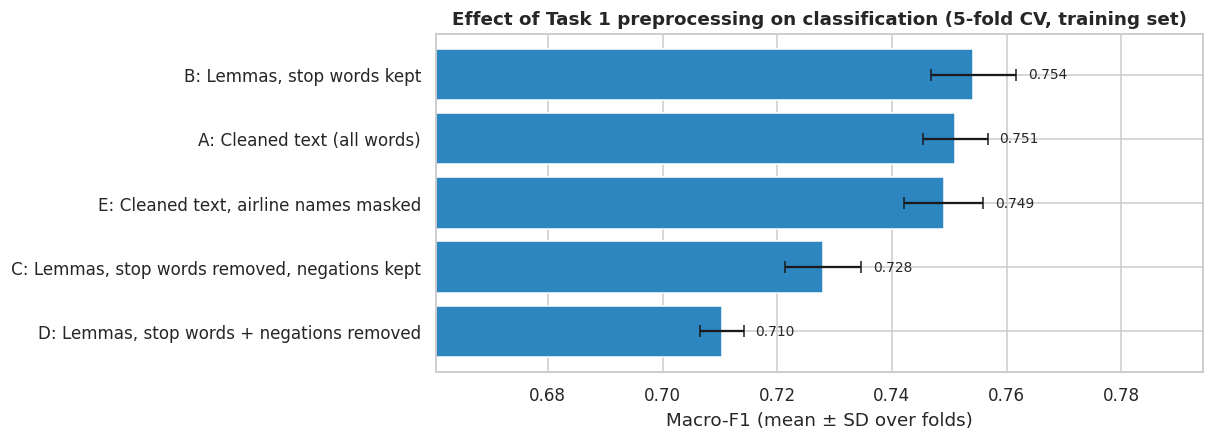

Keeping negations (C vs D): +0.0177 macro-F1
Lemmas + stop-word removal vs raw text (C vs A): -0.0230
Masking airline names (E vs A): -0.0020


In [49]:
# Initialize horizontal bar plot for cross-validation preprocessing ablation results
fig, ax = plt.subplots(figsize=(9, 4))
order = ablation.sort_values("macro_F1_mean").index
ax.barh([f"{k}: {VARIANTS[k]}" for k in order], ablation.loc[order, "macro_F1_mean"],
        xerr=ablation.loc[order, "macro_F1_sd"], color="#2E86C1", capsize=4)

# Annotate each bar with its mean macro-F1 score
for i, k in enumerate(order):
    end = ablation.loc[k, "macro_F1_mean"] + ablation.loc[k, "macro_F1_sd"]
    ax.text(end + 0.002, i, f"{ablation.loc[k, 'macro_F1_mean']:.3f}", va="center", fontsize=9)

# Format x-axis boundaries and set figure title/labels
lo = ablation.macro_F1_mean.min() - 0.05
ax.set_xlim(lo, ablation.macro_F1_mean.max() + 0.04)
ax.set(title="Effect of Task 1 preprocessing on classification (5-fold CV, training set)",
       xlabel="Macro-F1 (mean ± SD over folds)", ylabel="")

# Save visualization figure and display plot output
save_fig("fig2_01_preprocessing_ablation"); plt.show()

# Print comparative macro-F1 score differences for key preprocessing variants
print(f"Keeping negations (C vs D): {ablation.loc['C', 'macro_F1_mean'] - ablation.loc['D', 'macro_F1_mean']:+.4f} macro-F1")
print(f"Lemmas + stop-word removal vs raw text (C vs A): {ablation.loc['C', 'macro_F1_mean'] - ablation.loc['A', 'macro_F1_mean']:+.4f}")
print(f"Masking airline names (E vs A): {ablation.loc['E', 'macro_F1_mean'] - ablation.loc['A', 'macro_F1_mean']:+.4f}")

**Feature set.** Word n-grams cannot cope with misspellings, creative spellings or unseen inflections, which are all common in tweets. Character n-grams (`char_wb`, 2–5 characters) are a strong classical remedy. We test whether adding them to the best text variant helps.

In [50]:
# Identify best text representation variant from ablation study and set as model input
BEST_VARIANT = ablation.macro_F1_mean.idxmax()
print(f"Best text variant: {BEST_VARIANT} ({VARIANTS[BEST_VARIANT]})")
df["text_input"] = df[f"in_{BEST_VARIANT}"]
train, test = df.loc[train_idx].copy(), df.loc[test_idx].copy()

# Helper function to construct word-only or combined word/character-level TF-IDF feature union
def make_features(use_char):
    word = make_tfidf()
    if not use_char:
        return word
    char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True, lowercase=True)
    return FeatureUnion([("word", word), ("char", char)])

# Evaluate cross-validation macro-F1 score impact of adding character n-gram features
feat_cmp = {}
for use_char in [False, True]:
    pipe = Pipeline([("tfidf", make_features(use_char)),
                     ("clf", LogisticRegression(max_iter=3000, class_weight="balanced", C=5))])
    s = cross_val_score(pipe, train.text_input, y_train, cv=CV, scoring="f1_macro", n_jobs=-1)
    feat_cmp["word + char n-grams" if use_char else "word n-grams"] = (s.mean(), s.std())
    print(f"{'word + char' if use_char else 'word only':<12}: macro-F1 = {s.mean():.4f} ± {s.std():.4f}")

# Calculate performance gain from character n-grams and determine inclusion based on threshold
gain = feat_cmp["word + char n-grams"][0] - feat_cmp["word n-grams"][0]
USE_CHAR = gain > 0.01
print(f"\nGain from char n-grams: {gain:+.4f} → USE_CHAR = {USE_CHAR}"
      + ("" if USE_CHAR else " (gain too small to justify the loss of interpretability)"))

Best text variant: B (Lemmas, stop words kept)
word only   : macro-F1 = 0.7542 ± 0.0075
word + char : macro-F1 = 0.7531 ± 0.0064

Gain from char n-grams: -0.0011 → USE_CHAR = False (gain too small to justify the loss of interpretability)


## 2.3 Three classical models with cross-validated tuning
* **Logistic Regression:** linear, outputs class probabilities, and its coefficients can be read directly. `class_weight="balanced"` counters the class imbalance.
* **Linear SVM:** maximum-margin linear classifier, usually strong on sparse text, but it gives no probabilities.
* **Complement Naive Bayes:** a variant of Multinomial NB designed for imbalanced text (Rennie et al., 2003). It is very fast and a common sanity baseline.

The regularisation strength is tuned with 5-fold grid search on the training set, scored by macro-F1.

In [51]:
# Define target classifiers and hyperparameter search grids for grid search optimization
MODELS = {
    "Logistic Regression": (LogisticRegression(max_iter=3000, class_weight="balanced"),
                            {"clf__C": [0.5, 1, 2, 5, 10, 20]}),
    "Linear SVM":          (LinearSVC(class_weight="balanced"),
                            {"clf__C": [0.05, 0.1, 0.25, 0.5, 1, 2]}),
    "Complement NB":       (ComplementNB(),
                            {"clf__alpha": [0.05, 0.1, 0.25, 0.5, 1.0]}),
}

# Execute cross-validation grid searches to identify optimal hyperparameters per model
search_results, best_models, cv_summary = {}, {}, []
for name, (clf, grid) in MODELS.items():
    pipe = Pipeline([("tfidf", make_features(USE_CHAR)), ("clf", clf)])
    gs = GridSearchCV(pipe, grid, cv=CV, scoring="f1_macro", n_jobs=-1, return_train_score=True)
    t0 = time.perf_counter()
    gs.fit(train.text_input, y_train)
    search_time = time.perf_counter() - t0
    best_i = gs.best_index_
    cv_summary.append({"model": name, "best params": gs.best_params_,
                       "CV macro-F1": gs.cv_results_["mean_test_score"][best_i],
                       "CV SD": gs.cv_results_["std_test_score"][best_i],
                       "train macro-F1": gs.cv_results_["mean_train_score"][best_i],
                       "search time (s)": search_time})
    search_results[name] = pd.DataFrame(gs.cv_results_)
    best_models[name] = gs.best_estimator_
    print(f"{name:<20} best {gs.best_params_}  CV macro-F1 = {gs.best_score_:.4f}")

# Summarize hyperparameter tuning results and calculate train-validation overfitting gaps
cv_summary = pd.DataFrame(cv_summary).set_index("model")
cv_summary["overfit gap"] = cv_summary["train macro-F1"] - cv_summary["CV macro-F1"]
cv_summary.round(4)

Logistic Regression  best {'clf__C': 2}  CV macro-F1 = 0.7553
Linear SVM           best {'clf__C': 0.5}  CV macro-F1 = 0.7567
Complement NB        best {'clf__alpha': 0.25}  CV macro-F1 = 0.7274


,best params,CV macro-F1,CV SD,train macro-F1,search time (s),overfit gap
model,,,,,,
Logistic Regression,{'clf__C': 2},0.7553,0.0044,0.9451,73.4642,0.1899
Linear SVM,{'clf__C': 0.5},0.7567,0.0058,0.9743,23.8902,0.2176
Complement NB,{'clf__alpha': 0.25},0.7274,0.0084,0.9183,21.3016,0.1909


Saved figure → figures/task2/fig2_02_validation_curves.png


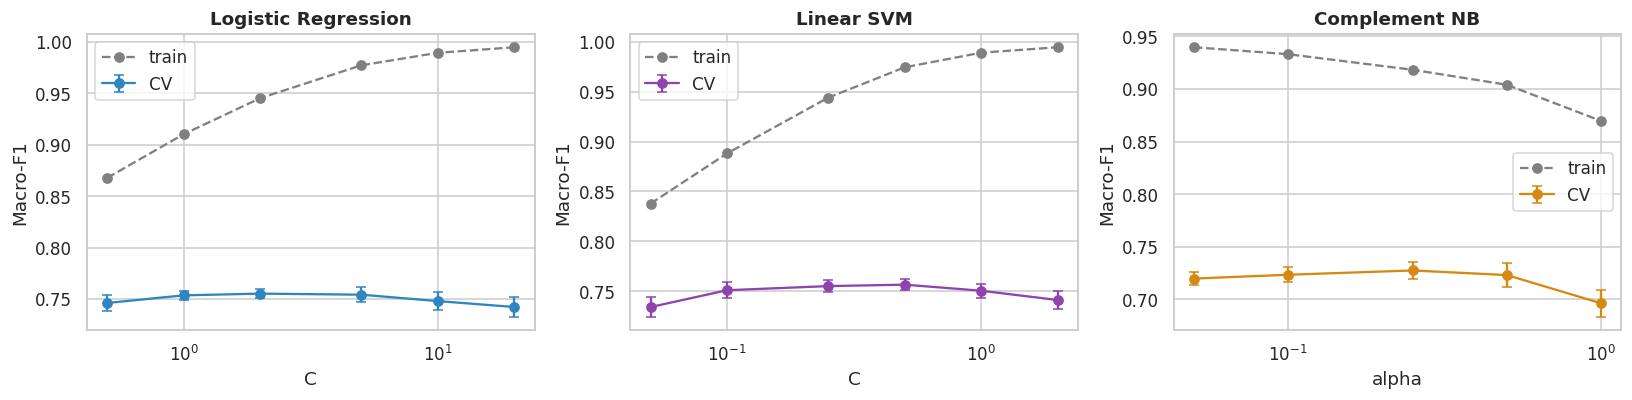

In [52]:
# Initialize subplots for model regularization parameter validation curves
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

# Plot training vs cross-validation macro-F1 curves across hyperparameter grids
for ax, (name, res) in zip(axes, search_results.items()):
    param = [c for c in res.columns if c.startswith("param_clf__")][0]
    x = res[param].astype(float)
    ax.plot(x, res.mean_train_score, "o--", color="grey", label="train")
    ax.errorbar(x, res.mean_test_score, yerr=res.std_test_score, fmt="o-", color=MODEL_PALETTE[name],
                capsize=3, label="CV")
    ax.set_xscale("log")
    ax.set(title=name, xlabel=param.replace("param_clf__", ""), ylabel="Macro-F1")
    ax.legend()

# Format layout, save validation curve plot, and display output
plt.tight_layout()
save_fig("fig2_02_validation_curves"); plt.show()

## 2.4 Test-set evaluation
The tuned models are refitted on the full training set (GridSearchCV does this automatically) and evaluated **once** on the held-out test set. We also measure inference speed and model size, which feed the business comparison in 2.10 and the Task 4 comparison. A 1,000-resample bootstrap gives a 95% confidence interval for macro-F1, which shows whether differences between models are meaningful.

In [53]:
# Function to calculate 95% bootstrap confidence intervals for macro-F1 scores
def bootstrap_ci(y_true, y_pred, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    scores = [f1_score(y_true[idx], y_pred[idx], average="macro")
              for idx in (rng.integers(0, len(y_true), len(y_true)) for _ in range(n_boot))]
    return np.percentile(scores, [2.5, 97.5])

# Helper function to compute serialized model object memory footprint in megabytes
def model_size_mb(model):
    return len(pickle.dumps(model)) / 1e6

# Refit best models on full training data, evaluate test performance, and compute latency/size metrics
test_results, predictions = [], {}
for name, model in best_models.items():
    t0 = time.perf_counter()
    model.fit(train.text_input, y_train)
    train_time = time.perf_counter() - t0
    t0 = time.perf_counter()
    y_pred = model.predict(test.text_input)
    infer_ms_per_1k = (time.perf_counter() - t0) / len(test) * 1000 * 1000
    predictions[name] = y_pred
    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
    lo, hi = bootstrap_ci(y_test, y_pred)
    test_results.append({
        "model": name, "accuracy": accuracy_score(y_test, y_pred),
        "macro precision": p, "macro recall": r, "macro F1": f,
        "macro F1 95% CI": f"[{lo:.3f}, {hi:.3f}]",
        "weighted F1": f1_score(y_test, y_pred, average="weighted"),
        "train time (s)": train_time, "inference (ms / 1k tweets)": infer_ms_per_1k,
        "n features": len(model.named_steps["tfidf"].get_feature_names_out()),
        "model size (MB)": model_size_mb(model)})

# Format test results DataFrame and print baseline majority-class benchmark comparison
test_results = pd.DataFrame(test_results).set_index("model")
majority = (y_test == "negative").mean()
print(f"Reference: always predicting 'negative' → accuracy {majority:.3f}, macro-F1 "
      f"{f1_score(y_test, ['negative'] * len(y_test), average='macro'):.3f}")
test_results.round(4)

Reference: always predicting 'negative' → accuracy 0.630, macro-F1 0.258


,accuracy,macro precision,macro recall,macro F1,macro F1 95% CI,weighted F1,train time (s),inference (ms / 1k tweets),n features,model size (MB)
model,,,,,,,,,,
Logistic Regression,0.8021,0.7470,0.7606,0.7533,"[0.736, 0.772]",0.8045,5.2031,211.0583,22355,1.0542
Linear SVM,0.8112,0.7617,0.7438,0.7521,"[0.734, 0.770]",0.8082,1.3142,97.5713,22355,1.0541
Complement NB,0.7914,0.7319,0.7178,0.7200,"[0.701, 0.739]",0.7848,0.4050,24.0744,22355,1.7695


In [54]:
# Identify top-performing model candidate based on test set macro-F1 score
BEST_NAME = test_results["macro F1"].idxmax()
best_model = best_models[BEST_NAME]
print(f"Best model on test macro-F1: {BEST_NAME}\n")

# Print per-class precision, recall, and F1 classification report for the best model
print(classification_report(y_test, predictions[BEST_NAME], digits=3, target_names=SENT_ORDER))

Best model on test macro-F1: Logistic Regression

              precision    recall  f1-score   support

    negative      0.891     0.860     0.875      1817
     neutral      0.615     0.664     0.639       611
    positive      0.735     0.758     0.746       458

    accuracy                          0.802      2886
   macro avg      0.747     0.761     0.753      2886
weighted avg      0.808     0.802     0.804      2886



Saved figure → figures/task2/fig2_03_confusion_matrices.png


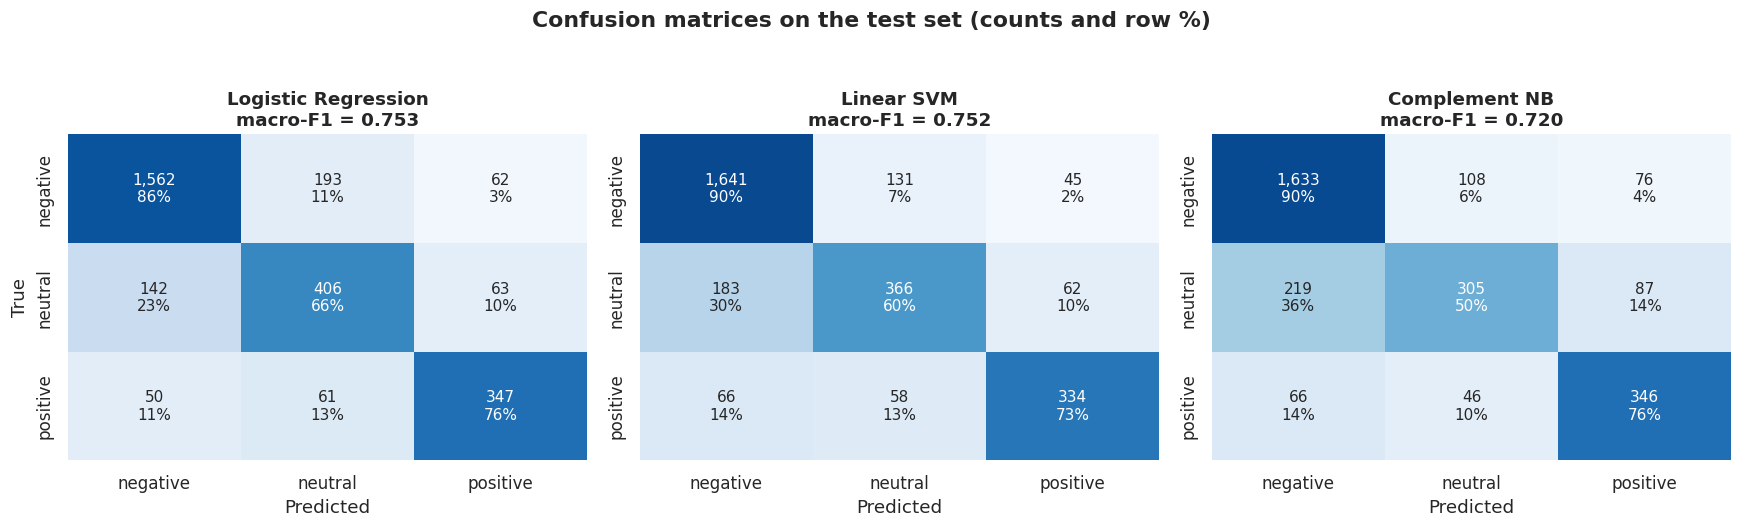

In [55]:
# Initialize subplots for test set confusion matrices across models
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# Plot normalized confusion matrices with raw counts and recall percentages per class
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=SENT_ORDER)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([[f"{cm[i, j]:,}\n{cm_norm[i, j]:.0%}" for j in range(3)] for i in range(3)])
    sns.heatmap(cm_norm, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=SENT_ORDER, yticklabels=SENT_ORDER, annot_kws={"fontsize": 10})
    ax.set(title=f"{name}\nmacro-F1 = {test_results.loc[name, 'macro F1']:.3f}",
           xlabel="Predicted", ylabel="True" if ax is axes[0] else "")

# Format figure title, adjust subplot spacing, and export confusion matrix visualization
plt.suptitle("Confusion matrices on the test set (counts and row %)", fontweight="bold", y=1.04)
plt.tight_layout()
save_fig("fig2_03_confusion_matrices"); plt.show()

Saved figure → figures/task2/fig2_04_per_class_f1.png


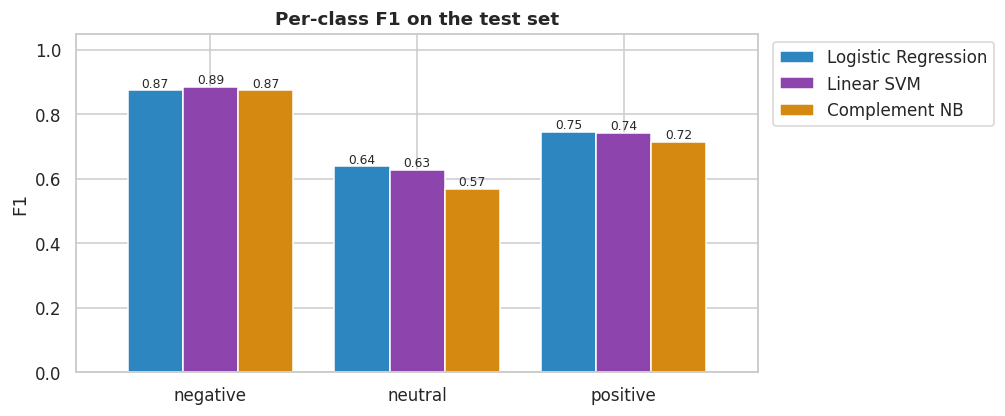

In [56]:
# Compute per-class F1 scores on the test set for each evaluated model
per_class = pd.DataFrame({name: f1_score(y_test, y_pred, average=None, labels=SENT_ORDER)
                          for name, y_pred in predictions.items()}, index=SENT_ORDER)

# Create a grouped bar plot comparing per-class F1 performance across models
ax = per_class.plot(kind="bar", figsize=(8, 4), color=[MODEL_PALETTE[m] for m in per_class.columns], rot=0, width=0.8)

# Annotate bars with numeric F1 values
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)

# Format y-axis boundaries, titles, and reposition legend outside plot frame
ax.set(title="Per-class F1 on the test set", ylabel="F1", ylim=(0, 1.05))
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")

# Save per-class F1 plot visualization and display output
save_fig("fig2_04_per_class_f1"); plt.show()

## 2.5 Interpretability: what has the model learned?
The Logistic Regression coefficients show which n-grams push a tweet towards each class. This transparency is the main business advantage of linear models: an analyst can check, explain and challenge every decision.

Saved figure → figures/task2/fig2_05_lr_top_features.png


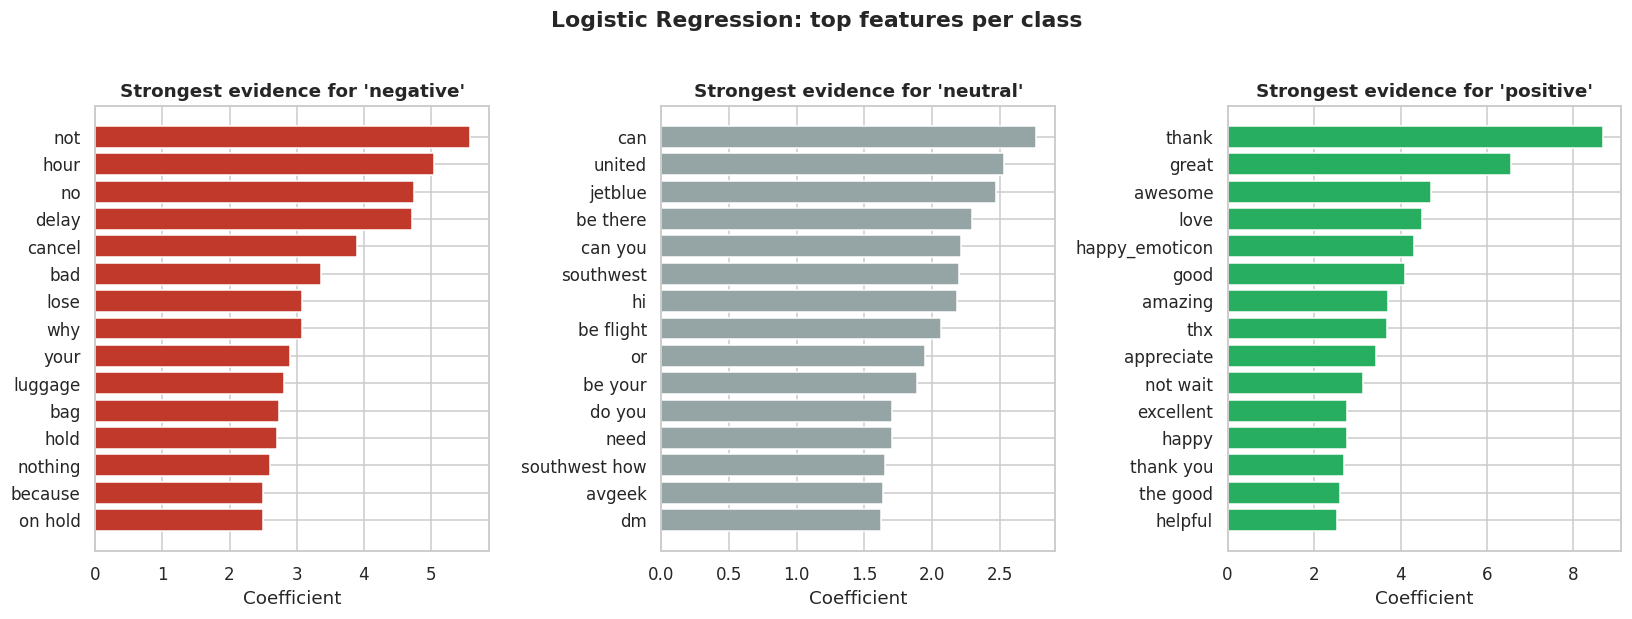

In [57]:
# Extract vectorizer, classifier, and cleaned feature names from the fitted Logistic Regression pipeline
lr = best_models["Logistic Regression"]
vec, clf_lr = lr.named_steps["tfidf"], lr.named_steps["clf"]
feature_names = np.array([f.split("__")[-1] for f in vec.get_feature_names_out()])

# Initialize subplots for horizontal bar plots showing top features per class
fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))

# Identify and plot top 15 positive coefficients for each sentiment class
for ax, cls in zip(axes, clf_lr.classes_):
    k = list(clf_lr.classes_).index(cls)
    top = np.argsort(clf_lr.coef_[k])[-15:]
    ax.barh(feature_names[top], clf_lr.coef_[k][top], color=SENT_PALETTE[cls])
    ax.set(title=f"Strongest evidence for '{cls}'", xlabel="Coefficient")

# Set figure title, adjust subplot layout, and save top feature visualization
plt.suptitle("Logistic Regression: top features per class", fontweight="bold", y=1.02)
plt.tight_layout()
save_fig("fig2_05_lr_top_features"); plt.show()

In [58]:
# List target airline brand names to inspect within the learned coefficient space
AIRLINE_TERMS = ["united", "southwest", "jetblue", "us airways", "american airlines", "virgin america", "delta",
                 "virgin", "american", "airways"]

# Retrieve class index for 'negative' sentiment and construct a feature-to-index mapping dictionary
k_neg = list(clf_lr.classes_).index("negative")
vocab = {f: i for i, f in enumerate(feature_names)}

# Extract negative-class coefficients for present airline features and sort in ascending order
airline_coef = pd.DataFrame([(t, clf_lr.coef_[k_neg][vocab[t]]) for t in AIRLINE_TERMS if t in vocab],
                            columns=["feature", "coef → negative"]).sort_values("coef → negative")

# Calculate relative rank of each airline feature coefficient among all vocabulary features
airline_coef["rank among all features"] = airline_coef["coef → negative"].map(
    lambda c: int((clf_lr.coef_[k_neg] > c).sum()) + 1)

# Display total vocabulary count and the airline coefficient ranking table
print(f"Vocabulary size: {len(feature_names):,}")
airline_coef

Vocabulary size: 22,355


,feature,coef → negative,rank among all features
2,jetblue,-3.990449,22354
1,southwest,-3.697241,22353
7,virgin,-1.641973,22340
5,virgin america,-1.436968,22334
0,united,-0.541398,21763
4,american airlines,-0.228728,19005
8,american,-0.127266,16649
6,delta,0.174074,4966
9,airways,0.413335,1149
3,us airways,0.664722,418


## 2.6 Error analysis and misclassified examples
First we look for **systematic** error patterns: annotator disagreement, negation, length and class confusions. Then we inspect individual errors with a per-tweet explanation that shows which features pushed the prediction.

Saved figure → figures/task2/fig2_06_error_patterns.png


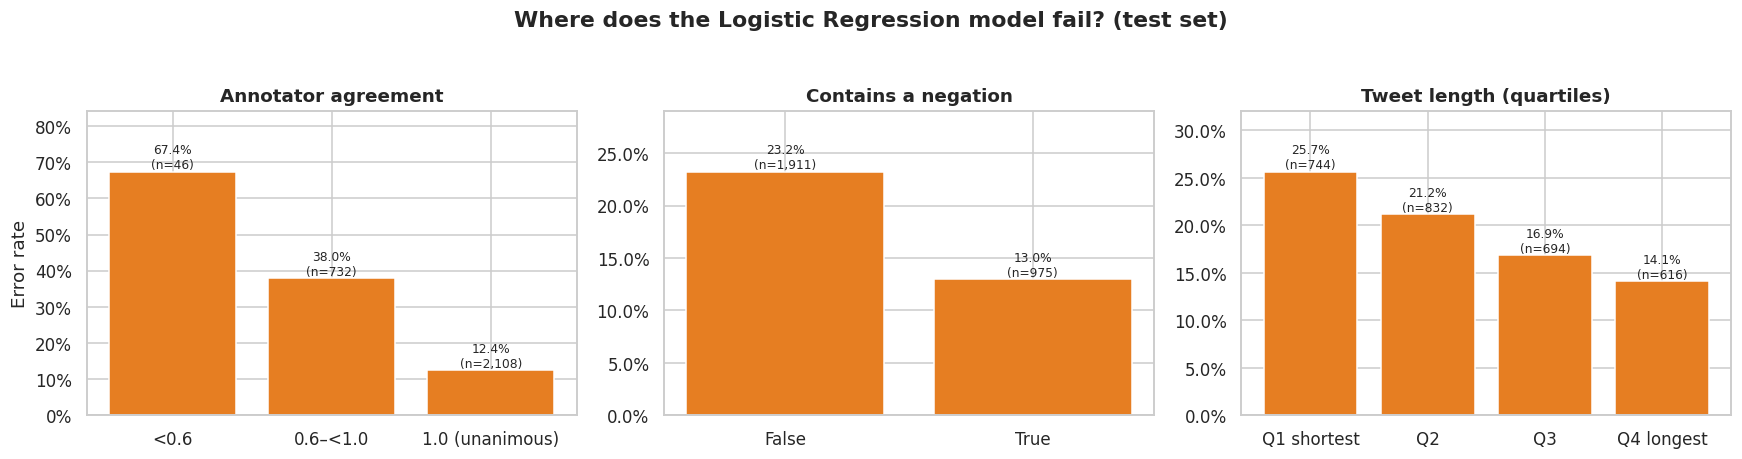

In [59]:
# Add predictions, correctness flags, confidence bins, and length quartiles to test DataFrame
test = test.assign(pred=predictions[BEST_NAME], correct=predictions[BEST_NAME] == y_test)
test["conf_bin"] = pd.cut(test.airline_sentiment_confidence, [0, 0.6, 0.999, 1.0],
                          labels=["<0.6", "0.6–<1.0", "1.0 (unanimous)"])
test["length_bin"] = pd.qcut(test.n_words, 4, labels=["Q1 shortest", "Q2", "Q3", "Q4 longest"])

# Initialize subplots to analyze error patterns across confidence, negation, and length categories
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in [(axes[0], "conf_bin", "Annotator agreement"),
                       (axes[1], "has_negation", "Contains a negation"),
                       (axes[2], "length_bin", "Tweet length (quartiles)")]:
    err = 1 - test.groupby(col, observed=True).correct.mean()
    n = test.groupby(col, observed=True).size()
    bars = ax.bar(err.index.astype(str), err.values, color="#E67E22")
    for b, e, k in zip(bars, err.values, n.values):
        ax.annotate(f"{e:.1%}\n(n={k:,})", (b.get_x() + b.get_width() / 2, e), ha="center", va="bottom", fontsize=8)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set(title=title, ylabel="Error rate" if ax is axes[0] else "", xlabel="")
    ax.margins(y=0.25)

# Format figure layout, set plot title, and save error analysis visualization
plt.suptitle(f"Where does the {BEST_NAME} model fail? (test set)", fontweight="bold", y=1.04)
plt.tight_layout()
save_fig("fig2_06_error_patterns"); plt.show()

> **Caution when reading Fig 2.6:** these slices are confounded with class. Negations are most common in negative tweets, which is the easiest class, so "contains a negation" can show a *lower* error rate even though negation scope is a known weakness of bag-of-words. The annotator-agreement panel is the cleanest signal: tweets that humans disagreed on are also the ones the model gets wrong, which points to label noise rather than only model failure.

**Explaining individual predictions.** For a linear model, a feature's contribution to a class score is *TF-IDF value × coefficient*. The function below lists the features that pushed the tweet towards the predicted class and towards the true class. It explains Logistic Regression decisions, so it is applied to that model.

In [60]:
# Helper function to compute class probabilities and top contributing TF-IDF feature weights for a text sample
def explain(text, true_label, model=lr, top=6):
    vec_, clf_ = model.named_steps["tfidf"], model.named_steps["clf"]
    x = vec_.transform([text])
    proba = clf_.predict_proba(x)[0]
    pred = clf_.classes_[proba.argmax()]
    out = {}
    for role, cls in [("pred", pred), ("true", true_label)]:
        k = list(clf_.classes_).index(cls)
        contrib = x.multiply(clf_.coef_[k]).tocsr()
        order = np.argsort(contrib.data)[::-1][:top]
        out[role] = ", ".join(f"{feature_names[contrib.indices[i]]} ({contrib.data[i]:+.2f})" for i in order)
    return pred, proba.max(), out

# Compute predictions and maximum predicted probabilities for test set samples
lr_pred = lr.predict(test.text_input)
lr_proba = lr.predict_proba(test.text_input).max(axis=1)

# Filter test set DataFrame to isolate prediction errors and print error rate summary
errors = test.assign(lr_pred=lr_pred, lr_conf=lr_proba)
errors = errors[errors.lr_pred != errors.airline_sentiment]
print(f"Logistic Regression errors on the test set: {len(errors):,} of {len(test):,} ({len(errors)/len(test):.1%})")

# Count and display most frequent misclassification error pairs (true vs predicted)
print(errors.groupby(["airline_sentiment", "lr_pred"]).size().sort_values(ascending=False)
      .rename("count").to_frame().rename_axis(["true", "predicted"]))

Logistic Regression errors on the test set: 571 of 2,886 (19.8%)
                    count
true     predicted       
negative neutral      193
neutral  negative     142
         positive      63
negative positive      62
positive neutral       61
         negative      50


In [61]:
# Helper function to extract top most confident error samples for a true/predicted label pair
def pick(true, pred, n=2):
    return errors[(errors.airline_sentiment == true) & (errors.lr_pred == pred)].nlargest(n, "lr_conf")

# Filter potential sarcasm errors where negative tweets containing positive polite words were predicted positive
sarcasm = errors[(errors.airline_sentiment == "negative") & (errors.lr_pred == "positive") &
                 errors.text_clean.str.contains(r"\b(?:thank|thanks|great|love|awesome)\b", case=False)]

# Assemble representative misclassifications across major error types and drop duplicates
candidates = pd.concat([pick("negative", "positive"), pick("positive", "negative"),
                        pick("neutral", "negative"), pick("negative", "neutral"),
                        sarcasm.nlargest(2, "lr_conf")]).drop_duplicates("tweet_id")

# Extract feature contribution explanations for each selected error candidate
rows = []
for _, r in candidates.iterrows():
    pred, conf, contrib = explain(r.text_input, r.airline_sentiment)
    rows.append({"text (cleaned)": r.text_clean, "true": r.airline_sentiment, "pred": pred,
                 "P(pred)": round(conf, 2), "annotator conf.": r.airline_sentiment_confidence,
                 "reason (if negative)": r.negativereason,
                 "features → predicted class": contrib["pred"], "features → true class": contrib["true"]})

# Format error explanations DataFrame, save as CSV, and render styled table
misclassified = pd.DataFrame(rows)
misclassified.to_csv(os.path.join(OUT_DIR, "task2_misclassified_examples.csv"), index=False)
misclassified.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"})

,text (cleaned),true,pred,P(pred),annotator conf.,reason (if negative),features → predicted class,features → true class
0,American Airlines thanks for the canned reply.,negative,positive,0.950000,0.678700,Customer Service Issue,"thank (+2.20), thank for (+0.79), airlines thank (+0.53), reply (+0.28), for the (+0.26), the (+0.03)","for (+0.17), thank for (+0.15), the (+0.10), airlines (-0.00), reply (-0.02), american (-0.03)"
1,United What a really GREAT & FLATTERING story about you! You should be very proud happy_emoticon (via ),negative,positive,0.910000,1.000000,Customer Service Issue,"great (+1.11), happy_emoticon (+0.79), very (+0.34), you you (+0.33), be very (+0.30), proud (+0.28)","you (+0.23), really (+0.22), be (+0.15), story (+0.13), about (+0.13), should (+0.12)"
2,"US Airways after missing my flight and rebooking 2x, I just walked onto another flight and my phone was still on the seat!!",positive,negative,0.980000,0.367800,nan,"miss (+0.32), still (+0.26), phone (+0.23), walk (+0.22), and (+0.21), my (+0.20)","just (+0.15), and rebooke (+0.07), and (+0.07), on the (+0.06), be still (+0.02), the (+0.01)"
3,US Airways we haven't departed yet so let's not get too high hopes. But everything has been on schedule so far,positive,negative,0.900000,0.704900,nan,"not (+0.73), but (+0.21), have (+0.20), have not (+0.15), not get (+0.13), be (+0.13)","so far (+0.20), everything (+0.20), so (+0.17), far (+0.14), too (+0.13), have be (+0.12)"
4,"Southwest I was under the impression when there is an 8 hour delay in your flight because of equipment failure, compensation is offered?",neutral,negative,0.970000,0.656300,nan,"hour (+0.53), delay (+0.52), because (+0.36), your (+0.27), be (+0.25), compensation (+0.20)","southwest be (+0.25), there (+0.20), southwest (+0.18), under (+0.16), impression (+0.11), your flight (+0.05)"
5,United Why have airlines always told us they can't open a cabin door once it has been closed? This plane has done it 3 times tonight.,neutral,negative,0.950000,0.647600,nan,"not (+0.37), why (+0.35), have (+0.22), tell (+0.20), door (+0.14), plane (+0.14)","can (+0.24), united (+0.16), do (+0.10), open (+0.09), it time (+0.09), it (+0.07)"
6,"United Freakin""",negative,neutral,0.970000,0.670000,Can't Tell,united (+2.53),united (-0.54)
7,Southwest When will the flight resume? I don's see it in the open schedule. sad_emoticon,negative,neutral,0.920000,1.000000,Late Flight,"southwest when (+0.32), will the (+0.30), southwest (+0.25), will (+0.23), schedule (+0.20), see it (+0.18)","sad_emoticon (+0.34), when (+0.23), it in (+0.16), when will (+0.11), the (+0.09), the flight (+0.08)"


> **For the report:** choose at least two of these examples. For each one, state the true and predicted label, quote the contributing features, and explain the failure mechanism. Typical mechanisms are sarcasm (*"thanks for nothing"*), politeness masking a complaint, a neutral question that contains complaint vocabulary, a negation scope that bag-of-words cannot represent, and a debatable gold label (look at the annotator confidence).

## 2.7 Optional: do NER features improve classification?
Binary indicators for each entity type from Task 1 (e.g. *contains a TIME*, *contains an ISSUE term*) are appended to the TF-IDF features of the Logistic Regression model. Both versions are evaluated on the **same CV folds** (paired comparison) and on the test set.

In [62]:
# Isolate named entity count columns and retrieve optimal Logistic Regression C parameter
ENT_COLS = [c for c in df.columns if c.startswith("ent_")]
lr_C = best_models["Logistic Regression"].named_steps["clf"].C

# Function to construct ColumnTransformer pipeline combining TF-IDF features with optional binary NER indicators
def lr_pipeline(with_ner):
    text_part = [("text", make_features(USE_CHAR), "text_input")]
    ner_part = [("ner", FunctionTransformer(np.sign), ENT_COLS)] if with_ner else []
    return Pipeline([("features", ColumnTransformer(text_part + ner_part)),
                     ("clf", LogisticRegression(max_iter=3000, class_weight="balanced", C=lr_C))])

# Evaluate cross-validation macro-F1 with and without custom NER entity features
cols = ["text_input"] + ENT_COLS
ner_cv = {}
for with_ner in [False, True]:
    ner_cv[with_ner] = cross_val_score(lr_pipeline(with_ner), train[cols], y_train, cv=CV,
                                       scoring="f1_macro", n_jobs=-1)

# Fit models on full training set and evaluate held-out test set macro-F1 scores
diff = ner_cv[True] - ner_cv[False]
ner_test = {w: f1_score(y_test, lr_pipeline(w).fit(train[cols], y_train).predict(test[cols]), average="macro")
            for w in [False, True]}

# Display comparative CV/test performance table and output paired fold difference summary
ner_table = pd.DataFrame({
    "CV macro-F1 (mean ± SD)": [f"{ner_cv[w].mean():.4f} ± {ner_cv[w].std():.4f}" for w in [False, True]],
    "test macro-F1": [f"{ner_test[w]:.4f}" for w in [False, True]],
}, index=["TF-IDF only", "TF-IDF + NER indicators"])
display(ner_table)
print(f"Paired per-fold difference: mean {diff.mean():+.4f}, folds improved: {(diff > 0).sum()}/5")
print("Entity indicators used:", ENT_COLS)

,CV macro-F1 (mean ± SD),test macro-F1
TF-IDF only,0.7553 ± 0.0044,0.7533
TF-IDF + NER indicators,0.7542 ± 0.0091,0.7535


Paired per-fold difference: mean -0.0011, folds improved: 1/5
Entity indicators used: ['ent_ORG', 'ent_GPE', 'ent_PERSON', 'ent_DATE', 'ent_TIME', 'ent_MONEY', 'ent_CARDINAL', 'ent_AIRLINE', 'ent_SERVICE', 'ent_ISSUE']


## 2.8 Slices relevant to Task 5: urgent complaints and airlines
Overall metrics can hide failures that matter commercially. Two questions: (i) are some complaint types more often missed (negative tweets not predicted as negative)? (ii) does performance differ by airline?

Saved figure → figures/task2/fig2_07_recall_by_complaint_type.png


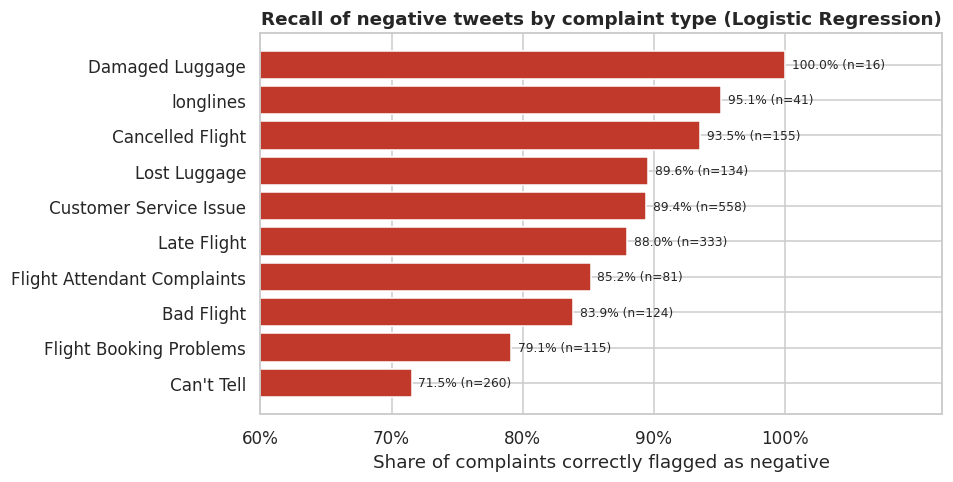

In [63]:
# Filter negative sentiment test set samples and calculate recall rate per complaint reason
neg_test = test[test.airline_sentiment == "negative"]
recall_by_reason = (neg_test.assign(hit=neg_test.pred == "negative")
                    .groupby("negativereason").hit.agg(["mean", "size"])
                    .sort_values("mean"))

# Initialize horizontal bar plot for negative sentiment recall across complaint types
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(recall_by_reason.index, recall_by_reason["mean"], color=SENT_PALETTE["negative"])

# Annotate each bar with recall percentage and sample count
for b, (rec, n) in zip(bars, recall_by_reason.values):
    ax.text(rec + 0.005, b.get_y() + b.get_height() / 2, f"{rec:.1%} (n={int(n)})", va="center", fontsize=8)

# Format x-axis as percentage, set plot boundaries, and assign titles
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlim(recall_by_reason["mean"].min() - 0.1, 1.12)
ax.set_xticks([t for t in ax.get_xticks() if t <= 1.0])
ax.set(title=f"Recall of negative tweets by complaint type ({BEST_NAME})",
       xlabel="Share of complaints correctly flagged as negative", ylabel="")

# Save recall analysis visualization and display plot output
save_fig("fig2_07_recall_by_complaint_type"); plt.show()

In [64]:
# Calculate performance metrics and sentiment distributions grouped by individual airline
airline_perf = (test.groupby("airline_plot")
                .apply(lambda g: pd.Series({
                    "n": len(g),
                    "macro F1": f1_score(g.airline_sentiment, g.pred, average="macro"),
                    "negative recall": (g.pred[g.airline_sentiment == "negative"] == "negative").mean(),
                    "true negative share": (g.airline_sentiment == "negative").mean(),
                    "predicted negative share": (g.pred == "negative").mean()}), include_groups=False)
                .sort_values("macro F1"))
display(airline_perf.round(3))

# Define an airline-identity baseline pipeline using one-hot encoding without text features
airline_only = Pipeline([("ohe", OneHotEncoder(handle_unknown="ignore")),
                         ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))])

# Evaluate cross-validation macro-F1 score for the airline-identity baseline model
s = cross_val_score(airline_only, train[["airline"]], y_train, cv=CV, scoring="f1_macro")
print(f"Airline-identity-only model, CV macro-F1: {s.mean():.3f} (chance level ≈ 0.33)")

,n,macro F1,negative recall,true negative share,predicted negative share
airline_plot,,,,,
Virgin America,86.0,0.717,0.676,0.430,0.326
US Airways,576.0,0.721,0.897,0.774,0.764
United,757.0,0.729,0.886,0.683,0.687
American,524.0,0.738,0.885,0.729,0.714
Delta* (@JetBlue),454.0,0.756,0.769,0.430,0.374
Southwest,489.0,0.775,0.796,0.491,0.454


Airline-identity-only model, CV macro-F1: 0.396 (chance level ≈ 0.33)


### 2.8.1 Airline-identity bias and a simple mitigation
Section 2.5 shows that airline names are among the model's strongest features (e.g. *jetblue* and *southwest* count as evidence *against* a tweet being negative). The model has learned each airline's base rate of complaints, not just the customer's words. As a result, complaints sent to airlines with a good reputation are more likely to be missed.

**Mitigation test:** retrain the same model with identical hyper-parameters after **removing airline names** from the input, then compare the share of complaints detected (negative recall) per airline. This turns a Task 5 fairness risk into a measured, mitigated result.

,test macro-F1,complaint recall: min airline,complaint recall: max airline,disparity (max − min)
with airline names,0.753,0.676,0.897,0.221
airline names removed,0.754,0.811,0.883,0.073


Saved figure → figures/task2/fig2_08_airline_bias_mitigation.png


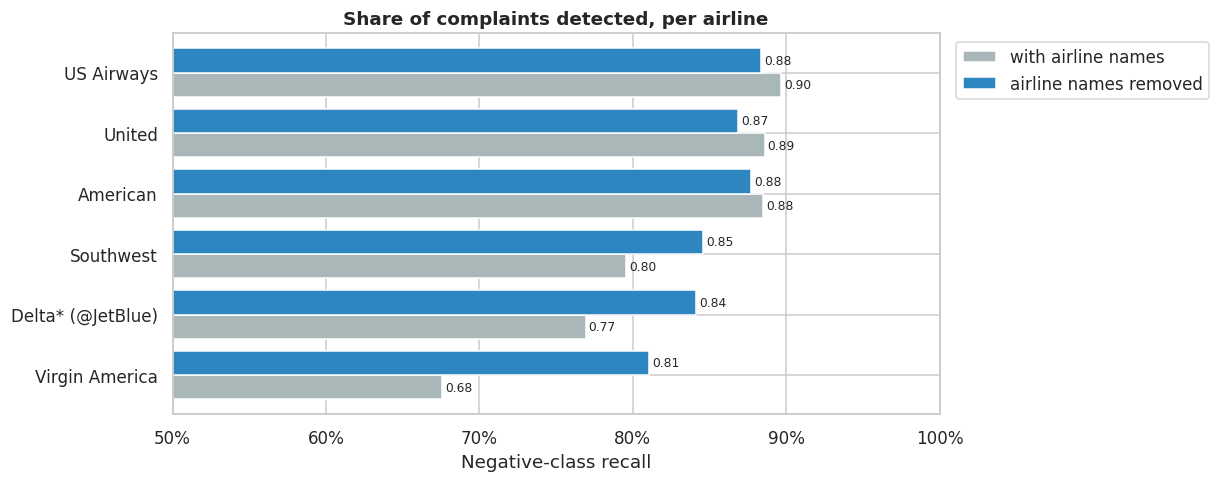

In [65]:
# Define set of airline brand terms and lemma tokens to mask for fairness evaluation
from sklearn.base import clone

AIRLINE_LEMMAS = {"united", "southwest", "jetblue", "delta", "virgin", "america", "american",
                  "airlines", "airline", "airways", "us"}

# Create airline-masked text input representations and refresh training and testing subset data
if BEST_VARIANT in ("A", "E"):
    df["text_input_masked"] = df.in_E
else:
    df["text_input_masked"] = df[f"in_{BEST_VARIANT}"].map(
        lambda s: " ".join(w for w in s.split() if w not in AIRLINE_LEMMAS))
train, test_m = df.loc[train_idx].copy(), df.loc[test_idx].copy()

# Fit cloned best model on masked text features and generate test set predictions
masked_model = clone(best_models[BEST_NAME]).fit(train.text_input_masked, y_train)
pred_masked = masked_model.predict(test_m.text_input_masked)
test["pred_masked"] = pred_masked

# Helper function to compute negative-class recall grouped by airline brand
def neg_recall_by_airline(pred_col):
    neg_rows = test[test.airline_sentiment == "negative"]
    return neg_rows.groupby("airline_plot").apply(lambda g: (g[pred_col] == "negative").mean(), include_groups=False)

# Compare per-airline complaint recall and summarize performance disparities before vs after masking
fair = pd.DataFrame({"with airline names": neg_recall_by_airline("pred"),
                     "airline names removed": neg_recall_by_airline("pred_masked")}).sort_values("with airline names")
fair_summary = pd.DataFrame({
    "test macro-F1": [f1_score(y_test, test.pred, average="macro"), f1_score(y_test, pred_masked, average="macro")],
    "complaint recall: min airline": fair.min().values,
    "complaint recall: max airline": fair.max().values,
    "disparity (max − min)": (fair.max() - fair.min()).values,
}, index=fair.columns)
display(fair_summary.round(3))

# Plot horizontal bar chart comparing per-airline negative recall across unmasked and masked models
ax = fair.plot(kind="barh", figsize=(9, 4.5), color=["#AAB7B8", "#2E86C1"], width=0.8)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8, padding=2)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlim(0.5, 1.0)
ax.set(title="Share of complaints detected, per airline", xlabel="Negative-class recall", ylabel="")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")

# Save fairness mitigation plot visualization and display output
save_fig("fig2_08_airline_bias_mitigation"); plt.show()

## 2.9 Learning curve: how much data does the classical model need?
Task 4 fine-tunes a transformer on 1,000–5,000 examples. For a fair comparison the classical model is also trained on the **same nested subsamples** (including the saved 5,000-tweet sample) and always evaluated on the same test set.

Saved figure → figures/task2/fig2_09_learning_curve.png


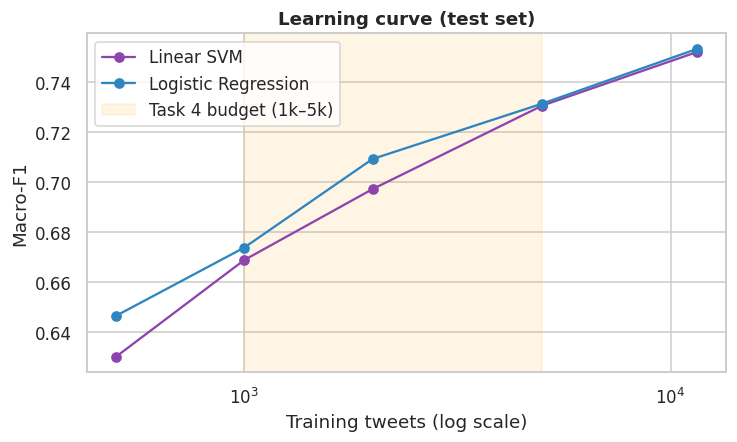

model,Linear SVM,Logistic Regression
n_train,,
500,0.6301,0.6464
1000,0.6688,0.6738
2000,0.6972,0.7092
5000,0.7306,0.7314
11541,0.7521,0.7533


In [66]:
# Compute learning curve macro-F1 scores across varied training set sample sizes
SIZES = [500, 1000, 2000, 5000, len(train_idx)]
curve = []
for n in SIZES:
    if n == 5000:
        idx = sub5k_idx
    elif n == len(train_idx):
        idx = train_idx
    else:
        idx, _ = train_test_split(train_idx, train_size=n, stratify=df.loc[train_idx, "airline_sentiment"],
                                  random_state=SEED)
    for name in ["Logistic Regression", "Linear SVM"]:
        m = best_models[name]
        m.fit(df.loc[idx, "text_input"], df.loc[idx, "airline_sentiment"])
        curve.append({"n_train": n, "model": name,
                      "macro F1": f1_score(y_test, m.predict(test.text_input), average="macro")})
curve = pd.DataFrame(curve)

# Initialize plot and render model learning curves across log-scaled dataset sizes
fig, ax = plt.subplots(figsize=(7.5, 4))
for name, g in curve.groupby("model"):
    ax.plot(g.n_train, g["macro F1"], "o-", color=MODEL_PALETTE[name], label=name)

# Highlight sample budget range, format logarithmic x-axis, and display legend
ax.axvspan(1000, 5000, color="orange", alpha=0.1, label="Task 4 budget (1k–5k)")
ax.set_xscale("log")
ax.set(title="Learning curve (test set)", xlabel="Training tweets (log scale)", ylabel="Macro-F1")
ax.legend()

# Save learning curve visualization, display plot output, and render pivoted score summary
save_fig("fig2_09_learning_curve"); plt.show()
display(curve.pivot(index="n_train", columns="model", values="macro F1").round(4))

# Refit all candidate models on the full training set to preserve optimal parameters
for name, m in best_models.items():
    m.fit(train.text_input, y_train)

## 2.10 Model comparison for business use and saving outputs

In [67]:
# Map qualitative interpretability assessments for each evaluated classifier family
INTERPRETABILITY = {"Logistic Regression": "High: signed coefficients + calibrated-ish probabilities",
                    "Linear SVM": "High: signed coefficients, but no probabilities",
                    "Complement NB": "Medium: per-class word weights, poorly calibrated probabilities"}

# Select core quantitative accuracy, speed, and memory metrics from test results
business = test_results[["accuracy", "macro F1", "macro F1 95% CI", "weighted F1",
                         "train time (s)", "inference (ms / 1k tweets)", "model size (MB)"]].copy()

# Append cross-validation macro-F1 scores to the comparison DataFrame
business["CV macro-F1"] = cv_summary["CV macro-F1"]

# Map probability support indicators and qualitative interpretability descriptions to each model
PROBA = {"Logistic Regression": "yes", "Linear SVM": "no (needs calibration)", "Complement NB": "yes (poorly calibrated)"}
business["probabilities for routing thresholds"] = business.index.map(PROBA)
business["interpretability"] = business.index.map(INTERPRETABILITY)

# Display final rounded business decision matrix table
business.round(3)

,accuracy,macro F1,macro F1 95% CI,weighted F1,train time (s),inference (ms / 1k tweets),model size (MB),CV macro-F1,probabilities for routing thresholds,interpretability
model,,,,,,,,,,
Logistic Regression,0.802,0.753,"[0.736, 0.772]",0.804,5.203,211.058,1.054,0.755,yes,High: signed coefficients + calibrated-ish probabilities
Linear SVM,0.811,0.752,"[0.734, 0.770]",0.808,1.314,97.571,1.054,0.757,no (needs calibration),"High: signed coefficients, but no probabilities"
Complement NB,0.791,0.720,"[0.701, 0.739]",0.785,0.405,24.074,1.769,0.727,yes (poorly calibrated),"Medium: per-class word weights, poorly calibrated probabilities"


In [68]:
# Assemble test set predictions, probability scores, and masked model outputs into an export DataFrame
pred_out = test[["tweet_id", "airline", "airline_plot", "airline_sentiment", "airline_sentiment_confidence",
                 "negativereason", "has_negation", "n_words", "text_clean"]].copy()
for name, y_pred in predictions.items():
    pred_out[f"pred_{name.replace(' ', '_')}"] = y_pred
pred_out["pred_best_airline_masked"] = test.pred_masked.to_numpy(dtype=str)

# Calculate and attach Logistic Regression predicted class probabilities for test samples
lr_probs = best_models["Logistic Regression"].predict_proba(test.text_input)
for k, cls in enumerate(best_models["Logistic Regression"].classes_):
    pred_out[f"proba_LR_{cls}"] = lr_probs[:, k]

# Export test predictions DataFrame to a CSV file for downstream tasks
pred_out.to_csv(os.path.join(OUT_DIR, "task2_test_predictions.csv"), index=False)

# Serialize best-performing model pipeline to joblib disk storage
joblib.dump(best_models[BEST_NAME], os.path.join(OUT_DIR, "task2_best_model.joblib"))

# Extract performance metrics for 5,000-sample training budget experiment
lr5k = curve[(curve.n_train == 5000)].set_index("model")["macro F1"].to_dict()

# Construct comprehensive dictionary aggregating test, CV, ablation, bias, and NER experiment metrics
metrics = {
    "best_model": BEST_NAME, "text_variant": f"{BEST_VARIANT}: {VARIANTS[BEST_VARIANT]}", "use_char_ngrams": bool(USE_CHAR),
    "test": test_results.drop(columns=["macro F1 95% CI"]).round(4).to_dict(orient="index"),
    "test_macro_f1_ci": test_results["macro F1 95% CI"].to_dict(),
    "cv": cv_summary[["CV macro-F1", "CV SD"]].round(4).to_dict(orient="index"),
    "ablation_cv_macro_f1": ablation.macro_F1_mean.round(4).to_dict(),
    "macro_f1_trained_on_5k": {k: round(v, 4) for k, v in lr5k.items()},
    "airline_bias": {"macro_f1": fair_summary["test macro-F1"].round(4).to_dict(),
                     "complaint_recall_disparity": fair_summary["disparity (max − min)"].round(4).to_dict(),
                     "complaint_recall_by_airline": fair.round(4).to_dict()},
    "ner_features": {"cv_without": round(ner_cv[False].mean(), 4), "cv_with": round(ner_cv[True].mean(), 4),
                     "test_without": round(ner_test[False], 4), "test_with": round(ner_test[True], 4)},
}

# Write summary metrics JSON file to output directory for downstream task access
with open(os.path.join(OUT_DIR, "task2_metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2, default=str)

# Save test performance and business decision matrix tables as CSV artifacts
test_results.to_csv(os.path.join(OUT_DIR, "task2_test_results.csv"))
business.to_csv(os.path.join(OUT_DIR, "task2_business_comparison.csv"))

# Print preview of serialized metrics JSON configuration
print(json.dumps(metrics, indent=2, default=str)[:1500])

{
  "best_model": "Logistic Regression",
  "text_variant": "B: Lemmas, stop words kept",
  "use_char_ngrams": false,
  "test": {
    "Logistic Regression": {
      "accuracy": 0.8021,
      "macro precision": 0.747,
      "macro recall": 0.7606,
      "macro F1": 0.7533,
      "weighted F1": 0.8045,
      "train time (s)": 5.2031,
      "inference (ms / 1k tweets)": 211.0583,
      "n features": 22355,
      "model size (MB)": 1.0542
    },
    "Linear SVM": {
      "accuracy": 0.8112,
      "macro precision": 0.7617,
      "macro recall": 0.7438,
      "macro F1": 0.7521,
      "weighted F1": 0.8082,
      "train time (s)": 1.3142,
      "inference (ms / 1k tweets)": 97.5713,
      "n features": 22355,
      "model size (MB)": 1.0541
    },
    "Complement NB": {
      "accuracy": 0.7914,
      "macro precision": 0.7319,
      "macro recall": 0.7178,
      "macro F1": 0.72,
      "weighted F1": 0.7848,
      "train time (s)": 0.405,
      "inference (ms / 1k tweets)": 24.0744,
      "

In [69]:
# Import shutil module for high-level file, directory, and archive operations
import shutil

# Task 3: Semantic Embeddings for Feedback Retrieval and Similarity Analysis
**Dataset:** Twitter US Airline Sentiment, cleaned in Task 1 (`tweets_task1.pkl`, 14,427 tweets)

Customer-feedback systems need to find *related* complaints: grouping recurring issues, retrieving similar cases for an agent, or answering *"show me tweets like this one"*. This notebook compares two embedding families and grounds the comparison in numbers rather than impressions:

| Section | Content |
|---|---|
| 3.0 | Set-up |
| 3.1 | Load data and check the corpus size (is it large enough for Word2Vec?) |
| 3.2 | Gensim Word2Vec trained on the tweets (Skip-gram and CBOW) |
| 3.3 | Word-level similarity (cosine) |
| 3.4 | Tweet vectors from averaged word vectors |
| 3.5 | Sentence Transformers (`all-MiniLM-L6-v2`), a pretrained alternative, and why it is justified |
| 3.6 | **Quantitative evaluation**: do nearest neighbours share the same complaint type, sentiment or airline? |
| 3.7 | Retrieval demo ("delivery was late", "customer service was unhelpful", …) |
| 3.8 | t-SNE visualisation |
| 3.9 | Grouping recurring issues (clustering) |
| 3.10 | Limitations: negation, sarcasm, antonyms, short texts |
| 3.11 | Save outputs |

## 3.0 Set-up

In [70]:
# Import standard library modules for file handling, serialization, timing, compression, and warning suppression
import os, json, time, random, zipfile, shutil, zlib, warnings
from collections import Counter

# Import core scientific computing, data manipulation, and scientific sparse array libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from scipy import sparse

# Import NLP and deep learning libraries for embeddings and semantic vector representations
import spacy
import torch
from gensim.models import Word2Vec
from sentence_transformers import SentenceTransformer

# Import scikit-learn utilities for feature extraction, normalization, dimensionality reduction, clustering, and metrics
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, normalized_mutual_info_score
from IPython.display import display

# Suppress runtime warning messages for cleaner output execution
warnings.filterwarnings("ignore")

# Set random seeds across Python, NumPy, and PyTorch for reproducible experiment runs
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

# Detect available compute hardware and assign GPU accelerator if present
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")

# Create output directories for Task 3 figure plots and exported artifacts
FIG_DIR, OUT_DIR = "figures/task3", "outputs"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

# Configure Seaborn theme, Matplotlib plotting parameters, and global sentiment palettes
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.titleweight": "bold", "axes.titlesize": 12})
SENT_ORDER = ["negative", "neutral", "positive"]
SENT_PALETTE = {"negative": "#C0392B", "neutral": "#95A5A6", "positive": "#27AE60"}
pd.set_option("display.max_colwidth", 140)

# Helper function to save matplotlib figure plots to the Task 3 figures directory
def save_fig(name):
    path = os.path.join(FIG_DIR, f"{name}.png")
    plt.savefig(path)
    print(f"Saved figure → {path}")

Device: cuda


## 3.1 Load data and check the corpus size
The cleaned tweets from Task 1 are loaded from `outputs/` (an upload dialog appears only if this section is run on its own).

In [71]:
# Define local and Google Drive file path locations for the Task 1 preprocessed dataset pickle
PKL = os.path.join(OUT_DIR, "tweets_task1.pkl")
DRIVE_PKL = "/content/drive/MyDrive/nlp_assignment/outputs/tweets_task1.pkl"

# Check for local dataset presence, copy from Google Drive if available, or request user upload in Colab
if not os.path.exists(PKL):
    if os.path.exists(DRIVE_PKL):
        shutil.copy(DRIVE_PKL, PKL)
    else:
        print("Please upload task2_tables.zip or tweets_task1.pkl")
        from google.colab import files
        for name in files.upload():
            if name.endswith(".zip"):
                zipfile.ZipFile(name).extractall(".")
            else:
                shutil.move(name, PKL)

# Load the preprocessed DataFrame from pickle storage and fill missing negative complaint reasons
df = pd.read_pickle(PKL).reset_index(drop=True)
df["reason"] = df.negativereason.fillna("none")

# Extract tokenized spaCy lemma sequences for Word2Vec training from the corpus
sentences = df.spacy_lemmas.tolist()
n_tokens = sum(len(s) for s in sentences)
vocab_counts = Counter(t for s in sentences for t in s)

# Calculate key corpus summary statistics including total tokens, mean length, and vocabulary frequencies
corpus_stats = pd.Series({
    "tweets (sentences)": len(sentences),
    "tokens": n_tokens,
    "mean tokens per tweet": round(n_tokens / len(sentences), 1),
    "vocabulary (all types)": len(vocab_counts),
    "types occurring ≥ 3 times": sum(c >= 3 for c in vocab_counts.values()),
    "share of types seen only once": round(np.mean([c == 1 for c in vocab_counts.values()]), 3),
}, name="value").to_frame()

# Display summary table of corpus token and vocabulary metrics
corpus_stats

,value
tweets (sentences),14427.000
tokens,253511.000
mean tokens per tweet,17.600
vocabulary (all types),9291.000
types occurring ≥ 3 times,3481.000
share of types seen only once,0.497


> **Why corpus size matters.** Word2Vec learns a word's meaning from the contexts it appears in. The original models were trained on about 100 billion words of Google News (Mikolov et al., 2013). Here we have about 250,000 tokens, roughly 400,000 times less, and most word types are rare. We therefore expect usable vectors only for frequent, domain-specific words. This is the brief's condition for justifying a pretrained alternative, and Sections 3.5–3.6 test it empirically instead of assuming it.

## 3.2 Word2Vec trained on the tweets
Two architectures are trained on the same corpus:
* **Skip-gram** (`sg=1`) predicts the context from a word. It is usually better for small corpora and rare words.
* **CBOW** (`sg=0`) predicts a word from its averaged context. It is faster and smooths over frequent words.

Settings: 100 dimensions, window 5, `min_count=3` (rarer words get no reliable vector), 10 negative samples, 30 epochs (many passes compensate for the small corpus). A single worker and a fixed hash function make the run reproducible.

In [72]:
# Define deterministic string hash function to ensure reproducible vector initialization across Gensim runs
def stable_hash(s):
    return zlib.crc32(s.encode("utf-8"))

# Set global hyperparameter configuration for Word2Vec training runs
W2V_PARAMS = dict(vector_size=100, window=5, min_count=3, negative=10, epochs=30,
                  workers=1, seed=SEED, hashfxn=stable_hash)

# Train Skip-gram and CBOW Word2Vec models on the corpus and measure execution timing
w2v = {}
for name, sg in [("Skip-gram", 1), ("CBOW", 0)]:
    t0 = time.perf_counter()
    w2v[name] = Word2Vec(sentences=sentences, sg=sg, **W2V_PARAMS)
    print(f"{name:<9}: vocabulary {len(w2v[name].wv):,} words | trained in {time.perf_counter() - t0:.1f}s")

# Calculate and print token coverage share across all corpus tokens
coverage = np.mean([t in w2v["Skip-gram"].wv for s in sentences for t in s])
print(f"Token coverage (share of corpus tokens that have a vector): {coverage:.1%}")

Skip-gram: vocabulary 3,481 words | trained in 82.6s
CBOW     : vocabulary 3,481 words | trained in 21.5s
Token coverage (share of corpus tokens that have a vector): 97.2%


## 3.3 Word-level similarity (cosine)

In [73]:
# Define seed domain terms for word similarity and nearest-neighbor evaluation
SEED_WORDS = ["delay", "cancel", "luggage", "rude", "refund", "seat", "wifi", "thank", "great", "not"]

# Extract top 5 nearest neighbors and cosine similarity scores for seed terms across Skip-gram and CBOW models
rows = []
for word in SEED_WORDS:
    row = {"word": word}
    for name, model in w2v.items():
        if word in model.wv:
            row[name] = ", ".join(f"{w} ({s:.2f})" for w, s in model.wv.most_similar(word, topn=5))
        else:
            row[name] = "(not in vocabulary)"
    rows.append(row)

# Format nearest neighbors into a DataFrame, export to CSV artifact, and render styled table
similar_words = pd.DataFrame(rows).set_index("word")
similar_words.to_csv(os.path.join(OUT_DIR, "task3_similar_words.csv"))
similar_words.style.set_properties(**{"text-align": "left"})

,Skip-gram,CBOW
word,,
delay,"glitch (0.61), diversion (0.59), offload (0.58), boarded (0.58), movement (0.56)","late (0.63), layover (0.48), schedule (0.46), arrival (0.44), cancelation (0.44)"
cancel,"cancellation (0.60), reschedule (0.58), cincy (0.56), cxl (0.56), bna (0.55)","original (0.47), reschedule (0.47), cancelation (0.45), cancellation (0.44), cxl (0.43)"
luggage,"bag (0.67), bags (0.56), baggage (0.56), apt (0.55), wallet (0.54)","bag (0.81), baggage (0.65), wallet (0.62), suitcase (0.61), item (0.53)"
rude,"uncaring (0.64), plitt (0.60), jacquie (0.60), appal (0.59), arrogant (0.58)","unhelpful (0.71), helpful (0.66), unprofessional (0.64), friendly (0.64), uncaring (0.61)"
refund,"request (0.59), sop (0.57), receipt (0.57), portion (0.57), partial (0.55)","credit (0.54), receipt (0.51), request (0.48), courtesy (0.46), voucher (0.40)"
seat,"econ (0.62), row (0.60), seating (0.59), economy (0.58), assignment (0.55)","seating (0.61), economy (0.52), cabin (0.50), row (0.49), space (0.49)"
wifi,"inflight (0.57), tv (0.54), abc (0.54), series (0.54), wi (0.53)","tv (0.60), abc (0.54), entertainment (0.48), movie (0.47), economy (0.46)"
thank,"thanx (0.66), shoutout (0.65), thx (0.61), thanks (0.61), jt (0.60)","thx (0.55), prompt (0.46), thanks (0.45), shoutout (0.43), appreciate (0.43)"
great,"exceptional (0.60), wonderful (0.59), awesome (0.57), thankyou (0.57), core (0.53)","wonderful (0.65), awesome (0.62), excellent (0.54), amazing (0.54), nice (0.52)"


In [74]:
# Define word pairs to probe distributional similarity, synonymy, and antonymy behavior
PAIRS = [("delay", "late"), ("luggage", "bag"), ("cancel", "rebook"), ("thank", "thanks"),
         ("good", "bad"), ("great", "terrible"), ("helpful", "unhelpful"), ("love", "hate")]

# Calculate pairwise cosine similarity scores for defined word pairs across Skip-gram and CBOW models
pair_sims = pd.DataFrame([{"pair": f"{a} – {b}",
                           **{name: (round(float(m.wv.similarity(a, b)), 3) if a in m.wv and b in m.wv else None)
                              for name, m in w2v.items()}} for a, b in PAIRS]).set_index("pair")

# Display comparative pairwise similarity score matrix
pair_sims

,Skip-gram,CBOW
pair,,
delay – late,0.559,0.630
luggage – bag,0.669,0.811
cancel – rebook,0.518,0.362
thank – thanks,0.605,0.445
good – bad,0.466,0.515
great – terrible,0.310,0.419
helpful – unhelpful,0.522,0.661
love – hate,0.335,0.446


## 3.4 Tweet vectors from averaged word vectors
Each tweet becomes the average of its word vectors (Task 1 lemmas, stop words removed, **negations kept**), with two weightings:
* **Mean:** every word counts equally.
* **TF-IDF-weighted mean:** frequent, uninformative words count less (a simple form of the weighting in Arora et al., 2017).

Airline names are excluded from the averages, so that similarity reflects the *issue* rather than the *brand* (see 3.6). Vectors are L2-normalised, so the dot product equals cosine similarity.

In [75]:
# Define set of airline brand terms to filter out from tokenized representations
AIRLINE_LEMMAS = {"united", "southwest", "jetblue", "delta", "virgin", "america", "american",
                  "airlines", "airline", "airways", "us"}
doc_tokens = df.spacy_lemmas_nostop.map(lambda ls: [t for t in ls if t not in AIRLINE_LEMMAS])

# Fit TF-IDF vectorizer on pre-processed token lists and extract IDF lookup dictionary
tfidf_vec = TfidfVectorizer(analyzer=lambda toks: toks, min_df=1)
X_tfidf = tfidf_vec.fit_transform(doc_tokens)
idf = dict(zip(tfidf_vec.get_feature_names_out(), tfidf_vec.idf_))

# Helper function to calculate unweighted or TF-IDF weighted average document vector
def doc_vector(tokens, kv, weighted=False):
    vecs, weights = [], []
    for t in tokens:
        if t in kv:
            vecs.append(kv[t])
            weights.append(idf.get(t, 1.0) if weighted else 1.0)
    if not vecs:
        return np.zeros(kv.vector_size, dtype=np.float32)
    return np.average(vecs, axis=0, weights=weights).astype(np.float32)

# Generate L2-normalized document embedding matrices for Word2Vec variants and TF-IDF baseline
EMB = {}
for name, model in w2v.items():
    EMB[f"W2V {name} (mean)"] = normalize(np.vstack([doc_vector(t, model.wv) for t in doc_tokens]))
EMB["W2V Skip-gram (TF-IDF-weighted)"] = normalize(np.vstack([doc_vector(t, w2v["Skip-gram"].wv, True) for t in doc_tokens]))
EMB["TF-IDF (lexical baseline)"] = normalize(X_tfidf)

# Calculate out-of-vocabulary tweet rate and print dimensions for created embedding matrices
empty = np.mean([not any(t in w2v["Skip-gram"].wv for t in toks) for toks in doc_tokens])
print(f"Tweets with no in-vocabulary word (zero vector): {empty:.2%}")
print({k: v.shape for k, v in EMB.items()})

Tweets with no in-vocabulary word (zero vector): 0.60%
{'W2V Skip-gram (mean)': (14427, 100), 'W2V CBOW (mean)': (14427, 100), 'W2V Skip-gram (TF-IDF-weighted)': (14427, 100), 'TF-IDF (lexical baseline)': (14427, 9076)}


## 3.5 Sentence Transformers: a pretrained alternative
`

In [76]:
# Initialize pre-trained MiniLM SentenceTransformer model and move to active device
SBERT_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
sbert = SentenceTransformer(SBERT_MODEL, device=DEVICE)
emb_dim = (getattr(sbert, "get_embedding_dimension", None) or sbert.get_sentence_embedding_dimension)()
print(f"Embedding dimension: {emb_dim} | "
      f"parameters: {sum(p.numel() for p in sbert.parameters()):,}")

# Encode tweet texts into normalized SBERT embeddings for both masked and unmasked text variants
for col, label in [("text_masked", "SBERT MiniLM (airline-masked)"), ("text_clean", "SBERT MiniLM (with airline names)")]:
    t0 = time.perf_counter()
    EMB[label] = sbert.encode(df[col].tolist(), batch_size=128, normalize_embeddings=True,
                              convert_to_numpy=True, show_progress_bar=False)
    print(f"{label}: {EMB[label].shape} in {time.perf_counter() - t0:.1f}s")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding dimension: 384 | parameters: 22,713,216
SBERT MiniLM (airline-masked): (14427, 384) in 7.4s
SBERT MiniLM (with airline names): (14427, 384) in 5.2s


## 3.6 Quantitative evaluation: what do nearest neighbours have in common?
There is no hand-labelled retrieval benchmark for this dataset, but the crowd labels give useful **proxies for relevance**. For every tweet we retrieve its 5 nearest neighbours by cosine similarity and measure:
* **Complaint-type precision@5:** for negative tweets with a specific reason (not *Can't Tell*), the share of neighbours with the **same complaint reason**. This is the most business-relevant measure ("find similar complaints").
* **Sentiment precision@5:** the share of neighbours with the same sentiment.
* **Same-airline rate@5:** the share of neighbours about the same airline. A high value means the embedding groups tweets by *brand*, not by *issue*.

Each measure is compared with its **chance level** (random neighbours).

In [77]:
# Helper function to compute top-k nearest neighbor document indices using batch matrix multiplication on L2-normalized embeddings
def topk_neighbours(E, k=10, chunk=2048):
    n = E.shape[0]
    out = np.empty((n, k), dtype=np.int32)
    for s in range(0, n, chunk):
        sims = E[s:s + chunk] @ E.T
        sims = sims.toarray() if sparse.issparse(sims) else np.asarray(sims)
        sims = sims.astype(np.float32)
        rows = np.arange(sims.shape[0])
        sims[rows, rows + s] = -np.inf
        idx = np.argpartition(-sims, k, axis=1)[:, :k]
        order = np.argsort(-np.take_along_axis(sims, idx, axis=1), axis=1)
        out[s:s + chunk] = np.take_along_axis(idx, order, axis=1)
    return out

# Extract ground truth target arrays and calculate chance-level baseline probabilities for evaluation metrics
sent, reason, airline = (df[c].to_numpy(dtype=str) for c in ["airline_sentiment", "reason", "airline"])
q_reason = (sent == "negative") & (reason != "Can't Tell")
reason_share = pd.Series(reason).value_counts(normalize=True)
CHANCE = {"complaint-type P@5": reason_share.reindex(reason[q_reason]).mean(),
          "sentiment P@5": (pd.Series(sent).value_counts(normalize=True) ** 2).sum(),
          "same-airline @5": (pd.Series(airline).value_counts(normalize=True) ** 2).sum()}

# Calculate Precision@5 for complaint type, sentiment class, and same-airline matching across all embedding representations
NEIGHBOURS, eval_rows = {}, []
for name, E in EMB.items():
    nb = topk_neighbours(E, k=10)
    NEIGHBOURS[name] = nb
    nb5 = nb[:, :5]
    eval_rows.append({"method": name,
                      "complaint-type P@5": (reason[nb5[q_reason]] == reason[q_reason][:, None]).mean(),
                      "sentiment P@5": (sent[nb5] == sent[:, None]).mean(),
                      "same-airline @5": (airline[nb5] == airline[:, None]).mean()})

# Append chance baseline row to evaluation records, format as DataFrame, and display rounded comparison table
eval_rows.append({"method": "Chance (random neighbours)", **CHANCE})
retrieval_eval = pd.DataFrame(eval_rows).set_index("method")
retrieval_eval.round(3)

,complaint-type P@5,sentiment P@5,same-airline @5
method,,,
W2V Skip-gram (mean),0.417,0.703,0.295
W2V CBOW (mean),0.437,0.684,0.264
W2V Skip-gram (TF-IDF-weighted),0.369,0.683,0.301
TF-IDF (lexical baseline),0.280,0.603,0.296
SBERT MiniLM (airline-masked),0.425,0.702,0.335
SBERT MiniLM (with airline names),0.422,0.697,0.916
Chance (random neighbours),0.115,0.466,0.195


Saved figure → figures/task3/fig3_01_retrieval_evaluation.png


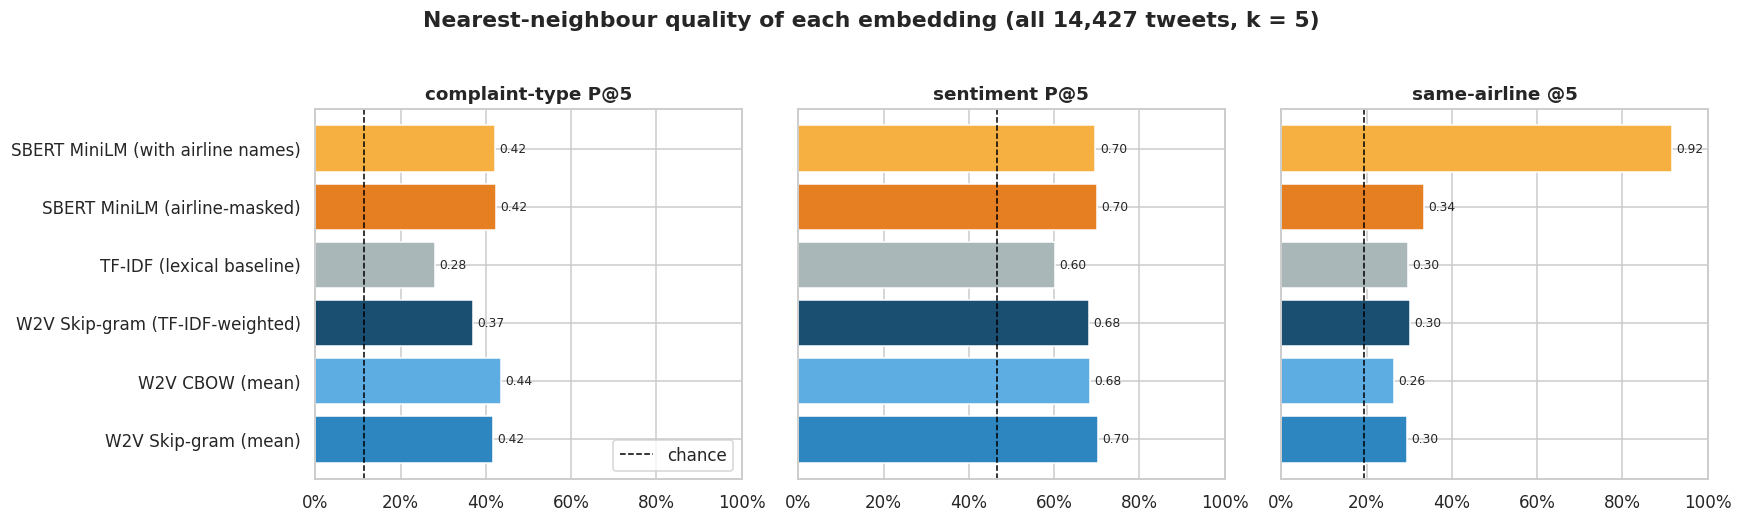

In [78]:
# Filter out chance baseline row from retrieval evaluation DataFrame for bar plot rendering
plot_df = retrieval_eval.drop(index="Chance (random neighbours)")

# Initialize multi-panel figure layout and map custom color palette to each embedding technique
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
METHOD_COLORS = {"TF-IDF (lexical baseline)": "#AAB7B8", "W2V Skip-gram (mean)": "#2E86C1", "W2V CBOW (mean)": "#5DADE2",
                 "W2V Skip-gram (TF-IDF-weighted)": "#1B4F72", "SBERT MiniLM (airline-masked)": "#E67E22",
                 "SBERT MiniLM (with airline names)": "#F5B041"}

# Iterate over retrieval metrics and plot horizontal performance comparison bars against chance baselines
for ax, metric in zip(axes, retrieval_eval.columns):
    ax.barh(plot_df.index, plot_df[metric], color=[METHOD_COLORS.get(m, "grey") for m in plot_df.index])
    ax.axvline(CHANCE[metric], color="black", ls="--", lw=1, label="chance")
    for i, v in enumerate(plot_df[metric]):
        ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8)
    ax.set(title=metric, xlim=(0, 1))
    ax.xaxis.set_major_formatter(PercentFormatter(1))

# Format axes layout, display legend, and set figure titles
axes[0].legend(loc="lower right")
plt.suptitle("Nearest-neighbour quality of each embedding (all 14,427 tweets, k = 5)", fontweight="bold", y=1.03)
plt.tight_layout()

# Save nearest-neighbor retrieval comparison plot and render display output
save_fig("fig3_01_retrieval_evaluation"); plt.show()

## 3.7 Retrieval demo
The two example queries from the brief, plus airline-specific versions, are embedded and matched against every tweet. *"Delivery was late"* is deliberately out-of-domain (airlines do not deliver), which tests whether the method generalises from meaning rather than matching words. **Hit@10** is the share of the top-10 results whose complaint label matches the query's intent.

Saved figure → figures/task3/fig3_02_query_hit_rates.png


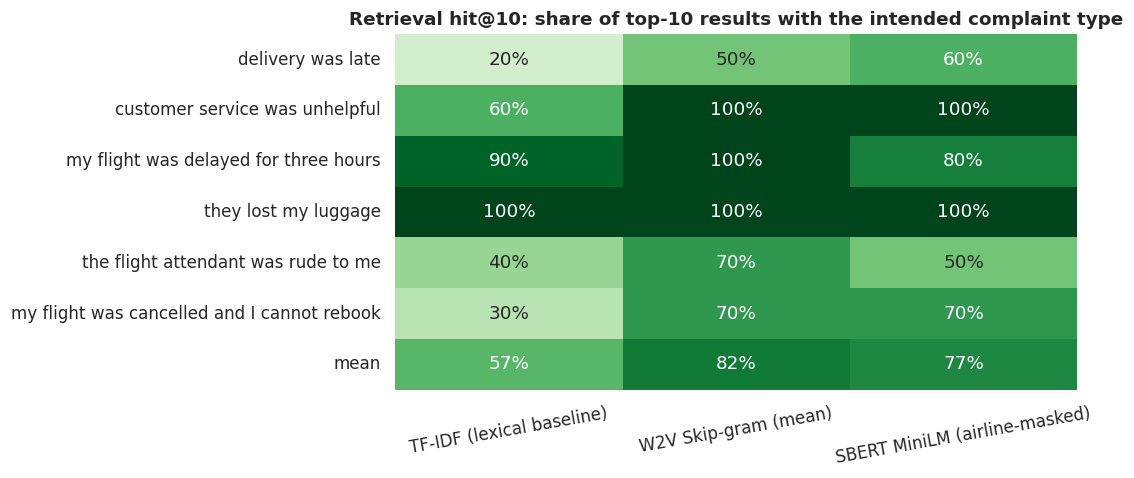

In [79]:
# Load lightweight spaCy English pipeline with parser and NER disabled for speed
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

# Define custom stop word set preserving key negation tokens
SPACY_STOP = nlp.Defaults.stop_words - {"no", "not", "never", "n't", "none", "nothing", "nobody", "nor",
                                        "neither", "nowhere", "cannot", "without"}

# Preprocess search query string into clean tokens following Task 1 normalization pipeline
def query_tokens(text):
    return [t.lemma_.lower() for t in nlp(text) if t.is_alpha and t.lower_ not in SPACY_STOP
            and t.lemma_.lower() not in AIRLINE_LEMMAS]

# Embed search query text into a normalized vector according to the selected representation strategy
def embed_query(text, method):
    if method.startswith("SBERT"):
        return sbert.encode([text], normalize_embeddings=True)[0]
    if method.startswith("TF-IDF"):
        return normalize(tfidf_vec.transform([query_tokens(text)])).toarray()[0]
    model = w2v["CBOW" if "CBOW" in method else "Skip-gram"].wv
    v = doc_vector(query_tokens(text), model, weighted="TF-IDF" in method)
    return v / (np.linalg.norm(v) or 1)

# Retrieve top-k nearest document tweets using cosine similarity in the specified embedding space
def search(text, method, k=10):
    E = EMB[method]
    sims = E @ embed_query(text, method)
    sims = np.asarray(sims).ravel()
    top = np.argsort(-sims)[:k]
    return df.iloc[top][["text_clean", "airline_sentiment", "reason"]].assign(cosine=sims[top].round(3))

# Define evaluation search queries and target complaint reason categories
QUERIES = {"delivery was late": "Late Flight",
           "customer service was unhelpful": "Customer Service Issue",
           "my flight was delayed for three hours": "Late Flight",
           "they lost my luggage": "Lost Luggage",
           "the flight attendant was rude to me": "Flight Attendant Complaints",
           "my flight was cancelled and I cannot rebook": "Cancelled Flight"}
DEMO_METHODS = ["TF-IDF (lexical baseline)", "W2V Skip-gram (mean)", "SBERT MiniLM (airline-masked)"]

# Calculate top-10 retrieval accuracy hit rates for test queries across representative embedding methods
hits = pd.DataFrame({m: {q: (search(q, m).reason == target).mean() for q, target in QUERIES.items()}
                     for m in DEMO_METHODS})
hits.loc["mean"] = hits.mean()

# Initialize heatmap plot showing top-10 complaint type retrieval hit rates
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.heatmap(hits, annot=True, fmt=".0%", cmap="Greens", vmin=0, vmax=1, cbar=False, ax=ax)
ax.set(title="Retrieval hit@10: share of top-10 results with the intended complaint type", xlabel="", ylabel="")
plt.xticks(rotation=10)

# Save query hit rate visualization and render output plot
save_fig("fig3_02_query_hit_rates"); plt.show()

In [80]:
# Iterate through test queries and embedding methods to retrieve and display top-5 search results
demo_tables = []
for q in ["delivery was late", "customer service was unhelpful"]:
    for m in ["W2V Skip-gram (mean)", "SBERT MiniLM (airline-masked)"]:
        res = search(q, m, k=5).assign(query=q, method=m)
        demo_tables.append(res)
        print(f"\nQUERY: '{q}'  |  {m}")
        display(res[["cosine", "text_clean", "airline_sentiment", "reason"]].reset_index(drop=True))

# Concatenate top-5 query retrieval results and export to CSV artifact
pd.concat(demo_tables).to_csv(os.path.join(OUT_DIR, "task3_retrieval_examples.csv"), index=False)


QUERY: 'delivery was late'  |  W2V Skip-gram (mean)


,cosine,text_clean,airline_sentiment,reason
0,0.802,American Airlines late again geez flt2417 late delays typical,negative,Late Flight
1,0.787,American Airlines But Eagle is always late,negative,Late Flight
2,0.781,Southwest too late now,negative,Can't Tell
3,0.781,US Airways too late.,negative,Can't Tell
4,0.756,United 2nd late flight today,negative,Late Flight



QUERY: 'delivery was late'  |  SBERT MiniLM (airline-masked)


,cosine,text_clean,airline_sentiment,reason
0,0.586,"American Airlines Not only was 5418 late, but we've been boarded and waiting for over 30min. WTF?",negative,Late Flight
1,0.564,American Airlines delayed.....wow,negative,Late Flight
2,0.563,"US Airways status shows ""delayed"" it was just ""waiting for takeoff"" so did it depart? It certainly didn't at 4:17pm.",negative,Late Flight
3,0.562,"United Not sure what happened @ MSP yesterday, but VERY UNHAPPY my bag was not only delayed, but sat at MSP for 8 hrs b4 delivery @ 2:30 am",negative,Lost Luggage
4,0.551,"American Airlines oh I did. All I received back was an email saying "" delays happen"".. Uh huh..",negative,Customer Service Issue



QUERY: 'customer service was unhelpful'  |  W2V Skip-gram (mean)


,cosine,text_clean,airline_sentiment,reason
0,0.890,US Airways not impressed with your customer service. everyone has been unhelpful and incredibly rude.,negative,Customer Service Issue
1,0.873,"JetBlue If this is customer service, then please call me.",negative,Customer Service Issue
2,0.873,United customer service what's That???,negative,Customer Service Issue
3,0.873,US Airways still crickets from customer service.,negative,Customer Service Issue
4,0.871,JetBlue I am But Your customer service is Brutal.,negative,Customer Service Issue



QUERY: 'customer service was unhelpful'  |  SBERT MiniLM (airline-masked)


,cosine,text_clean,airline_sentiment,reason
0,0.645,Southwest What's happened to your customer service? 2 cancelled flights in 2 days & an uninformed and unapologetic staff. nolove cali,negative,Customer Service Issue
1,0.638,Southwest extremely disappointed with poor the customer service provided after canceling my flight today! unprofessional,negative,Customer Service Issue
2,0.622,"United incompetent/rude service today. Missed my connecting flight, then the customer service desk was terrible to me. Really upset w untd.",negative,Customer Service Issue
3,0.602,JetBlue your customer service today was deplorable. There were plenty of ways u could have gotten us on that flight. badcustomerservice,negative,Customer Service Issue
4,0.589,Virgin America what is going on with customer service? Is there anyway to speak to a human asap? Thank you.,negative,Customer Service Issue


> **For the report, assess usefulness in a support or BI context:** would an agent handling the query find the results actionable (same issue, recent, resolvable)? Are the results driven by meaning or by shared words? Did the out-of-domain query *"delivery was late"* still find delay complaints?

## 3.8 Visualising the embedding space (t-SNE)
A stratified sample of 2,000 tweets is reduced with PCA (to 50 dimensions, which removes noise and speeds things up) and then t-SNE (to 2 dimensions). t-SNE preserves *local* neighbourhoods, but distances between far-apart clusters and cluster sizes are not meaningful (Wattenberg et al., 2016).

Saved figure → figures/task3/fig3_03_tsne_sentiment.png


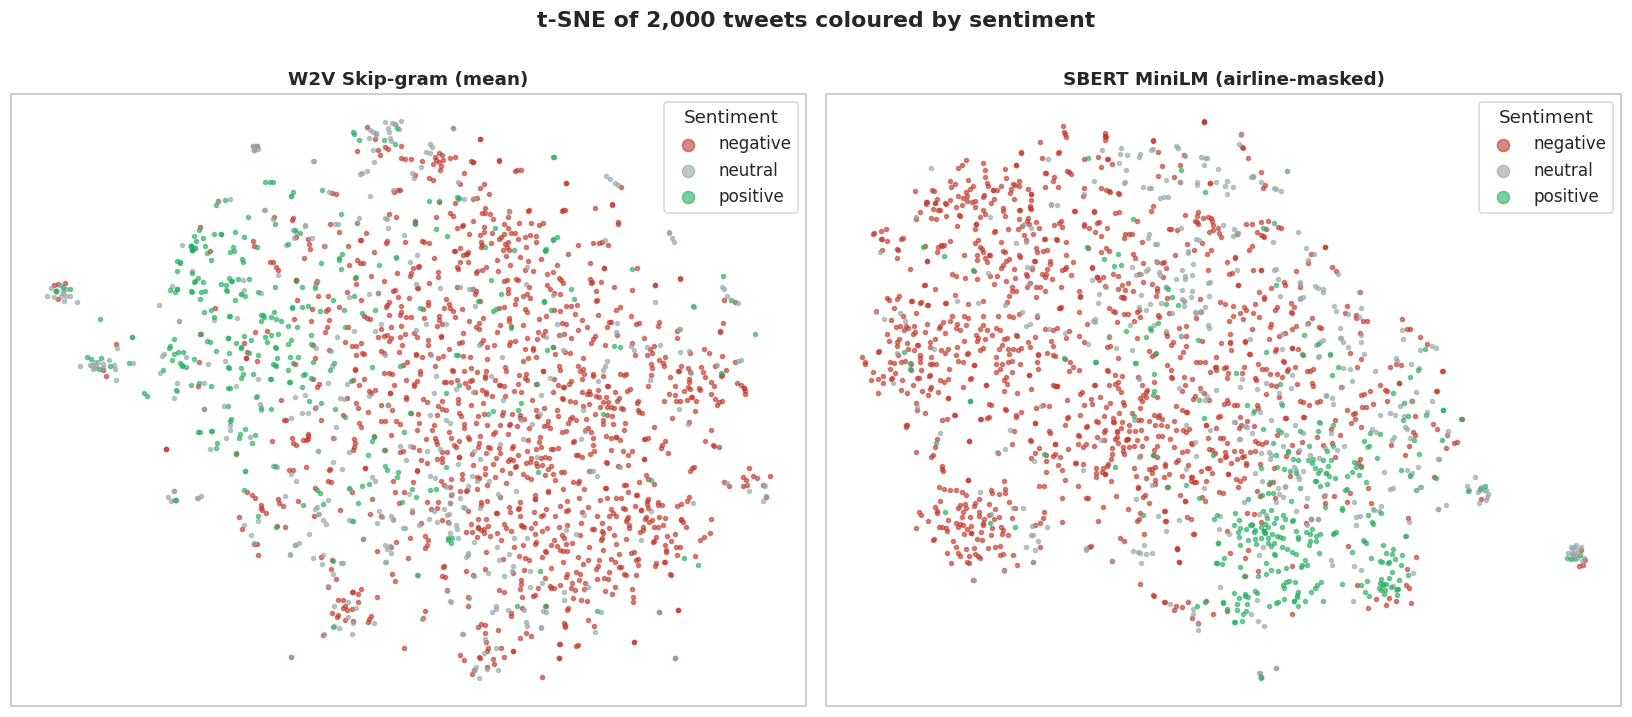

Variance captured by the first 2 PCA components: {'W2V Skip-gram (mean)': '13.1%', 'SBERT MiniLM (airline-masked)': '9.1%'}


In [81]:
# Helper function to compute 2D t-SNE projections from top 50 PCA components of sample embeddings
def tsne_2d(E, idx):
    X = E[idx].toarray() if sparse.issparse(E) else E[idx]
    X50 = PCA(n_components=50, random_state=SEED).fit_transform(X)
    return TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(X50)

# Sample 2,000 tweets maintaining class proportions for t-SNE visualization
sample_idx = (df.groupby("airline_sentiment", group_keys=False)
                .apply(lambda g: g.sample(int(round(2000 * len(g) / len(df))), random_state=SEED)).index.values)
VIS_METHODS = ["W2V Skip-gram (mean)", "SBERT MiniLM (airline-masked)"]

# Generate t-SNE sentiment cluster scatter plots for Word2Vec and SBERT embedding spaces
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, m in zip(axes, VIS_METHODS):
    Y = tsne_2d(EMB[m], sample_idx)
    for s in SENT_ORDER:
        mask = df.loc[sample_idx, "airline_sentiment"].to_numpy(dtype=str) == s
        ax.scatter(Y[mask, 0], Y[mask, 1], s=7, alpha=0.6, c=SENT_PALETTE[s], label=s)
    ax.set(title=m, xticks=[], yticks=[])
    ax.legend(markerscale=3, title="Sentiment")
plt.suptitle("t-SNE of 2,000 tweets coloured by sentiment", fontweight="bold", y=1.0)
plt.tight_layout()

# Save t-SNE plot artifact and render display
save_fig("fig3_03_tsne_sentiment"); plt.show()

# Compute cumulative variance explained by the top 2 PCA principal components
pca_var = {m: PCA(n_components=2).fit(EMB[m][sample_idx]).explained_variance_ratio_.sum() for m in VIS_METHODS}
print("Variance captured by the first 2 PCA components:", {k: f"{v:.1%}" for k, v in pca_var.items()})

Saved figure → figures/task3/fig3_04_tsne_complaint_reason.png


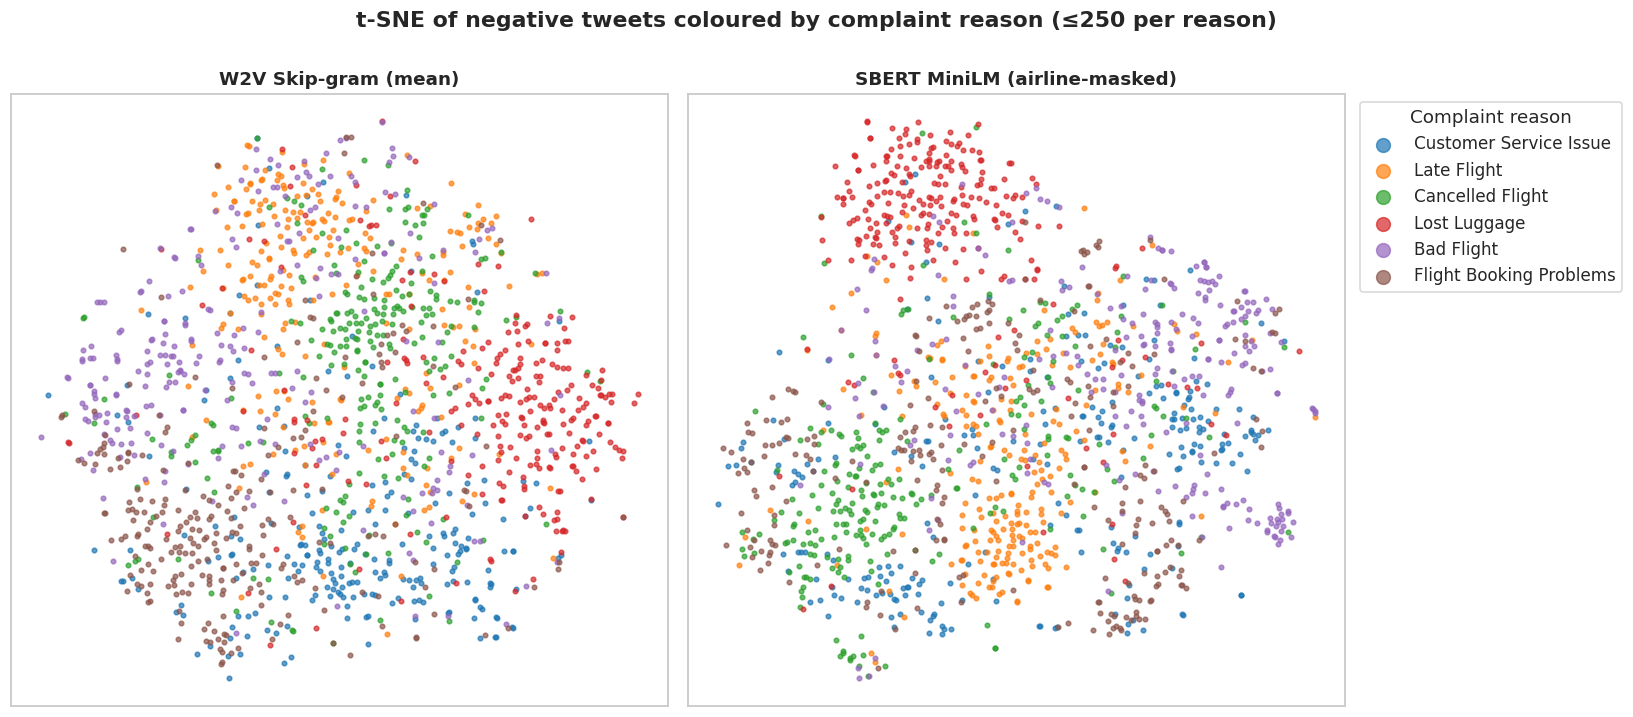

In [85]:
# Filter dataset to top negative complaint reason categories and set categorical palette colors
TOP_REASONS = ["Customer Service Issue", "Late Flight", "Cancelled Flight", "Lost Luggage", "Bad Flight",
               "Flight Booking Problems"]
REASON_COLORS = dict(zip(TOP_REASONS, sns.color_palette("tab10", len(TOP_REASONS))))

# Downsample negative complaint tweets to maximum 250 samples per reason category
neg_pool = df[df.reason.isin(TOP_REASONS)]
neg_idx = neg_pool.groupby("reason", group_keys=False).apply(
    lambda g: g.sample(min(250, len(g)), random_state=SEED)).index.values

# Generate side-by-side 2D t-SNE scatter plots colored by complaint reason across embedding spaces
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, m in zip(axes, VIS_METHODS):
    Y = tsne_2d(EMB[m], neg_idx)
    for r in TOP_REASONS:
        mask = df.loc[neg_idx, "reason"].to_numpy(dtype=str) == r
        ax.scatter(Y[mask, 0], Y[mask, 1], s=9, alpha=0.7, color=REASON_COLORS[r], label=r)
    ax.set(title=m, xticks=[], yticks=[])

# Position legend and set super-title for complaint category t-SNE comparison
axes[1].legend(markerscale=3, title="Complaint reason", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.suptitle("t-SNE of negative tweets coloured by complaint reason (≤250 per reason)", fontweight="bold", y=1.0)
plt.tight_layout()

# Save complaint reason t-SNE figure plot and render output
save_fig("fig3_04_tsne_complaint_reason"); plt.show()

## 3.9 Grouping recurring issues
K-means clustering of the Sentence-Transformer embeddings of **negative** tweets is an unsupervised way to discover complaint themes without predefined categories. The number of clusters is chosen by silhouette score. Each cluster is described by its most distinctive terms (class-based TF-IDF) and its most central tweet, and its agreement with the crowd-labelled complaint reasons is measured with normalised mutual information (NMI).

In [86]:
# Select SBERT masked embedding matrix and filter exclusively to negative sentiment tweets
CLUSTER_METHOD = "SBERT MiniLM (airline-masked)"
neg_mask = df.airline_sentiment.to_numpy(dtype=str) == "negative"
E_neg = EMB[CLUSTER_METHOD][neg_mask]

# Subsample 3,000 negative tweet vectors for fast, memory-efficient Silhouette score evaluation
rng = np.random.default_rng(SEED)
sil_idx = rng.choice(len(E_neg), size=min(3000, len(E_neg)), replace=False)

# Evaluate KMeans cosine Silhouette scores across cluster counts k = 5 to 12 to find optimal k
sil = {}
for k in range(5, 13):
    labels_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit_predict(E_neg)
    sil[k] = silhouette_score(E_neg[sil_idx], labels_k[sil_idx], metric="cosine")
BEST_K = max(sil, key=sil.get)
print("Silhouette by k:", {k: round(v, 4) for k, v in sil.items()}, "→ k =", BEST_K)

# Fit KMeans model using the optimal cluster count and assign cluster labels to negative tweets
km = KMeans(n_clusters=BEST_K, n_init=10, random_state=SEED).fit(E_neg)
neg = df[neg_mask].assign(cluster=km.labels_)

# Compute Normalized Mutual Information (NMI) between cluster assignments and ground-truth complaint reasons
specific = neg.reason != "Can't Tell"
nmi = normalized_mutual_info_score(neg.reason[specific], neg.cluster[specific])
print(f"NMI between clusters and complaint reasons (excluding Can't Tell): {nmi:.3f}")

Silhouette by k: {5: np.float32(0.0574), 6: np.float32(0.0527), 7: np.float32(0.0369), 8: np.float32(0.0337), 9: np.float32(0.033), 10: np.float32(0.0359), 11: np.float32(0.0297), 12: np.float32(0.0322)} → k = 5
NMI between clusters and complaint reasons (excluding Can't Tell): 0.204


In [87]:
# Define custom stop words to filter out common domain-generic tokens from cluster descriptions
CHART_STOP = AIRLINE_LEMMAS | {"flight", "not", "no"}

# Aggregate negative tweet tokens by assigned KMeans cluster ID
cluster_docs = neg.groupby("cluster").spacy_lemmas_nostop.apply(
    lambda s: [t for toks in s for t in toks if t not in CHART_STOP])

# Calculate class-based TF-IDF (c-TF-IDF) feature matrix across clusters using sublinear term frequency
ctfidf = TfidfVectorizer(analyzer=lambda toks: toks, sublinear_tf=True)
C = ctfidf.fit_transform(cluster_docs)
terms = ctfidf.get_feature_names_out()

# Extract cluster sizes, top c-TF-IDF terms, dominant complaint reasons, and most central exemplar tweets
rows = []
for c in range(BEST_K):
    members = np.where(km.labels_ == c)[0]
    central = members[np.argmax(E_neg[members] @ km.cluster_centers_[c])]
    top_terms = terms[np.argsort(-C[c].toarray()[0])[:8]]
    dom = neg[neg.cluster == c].reason.value_counts(normalize=True)
    rows.append({"cluster": c, "size": len(members), "share": len(members) / len(neg),
                 "distinctive terms": ", ".join(top_terms),
                 "dominant reason (share)": f"{dom.index[0]} ({dom.iloc[0]:.0%})",
                 "most central tweet": neg.iloc[central].text_clean})

# Construct cluster summary DataFrame, export results to CSV artifact, and render styled table
clusters = pd.DataFrame(rows).sort_values("size", ascending=False).set_index("cluster")
clusters.to_csv(os.path.join(OUT_DIR, "task3_issue_clusters.csv"))
clusters.style.format({"share": "{:.1%}"}).set_properties(**{"text-align": "left", "white-space": "pre-wrap"})

,size,share,distinctive terms,dominant reason (share),most central tweet
cluster,,,,,
3,2140,23.6%,"delay, hour, wait, time, hold, plane, cancel, minute",Late Flight (52%),JetBlue is a joke. Missed my connecting flight by 5 minutes. Last flight of the day and they don't hold it. 5 minutes.
4,2072,22.8%,"fly, wifi, thank, time, bad, seat, plane, hour",Can't Tell (29%),JetBlue that sucks. Oh well.
0,2017,22.2%,"cancel, help, account, hold, try, phone, disconnect, hour",Customer Service Issue (54%),US Airways I keep calling your help line (800) 428-4322 and it keeps saying they are too busy to help & to call back later. FOR A WEEK NOW!
2,1969,21.7%,"sos_button, fleek, customer, stewardess, service, serve, bad, conversation",Customer Service Issue (39%),United never flying with you guys ever again. The customer service is piss poor at best.
1,884,9.7%,"luggage, bag, baggage, lose, check, carousel, wet, hour",Lost Luggage (62%),US Airways So frustrating because I still have not gotten them back. Why my bag was sent to NY is a mystery! Shame on me this time!


## 3.10 Limitations: probing what similarity does and does not capture
Pairs of sentences with a known relationship (paraphrase, opposite polarity, negation, sarcasm) are compared with each method. In a decision-support setting, a high similarity for **opposite** meanings is a risk: a retrieval system could surface praise when an agent searches for complaints.

In [88]:
# Define sentence probe pairs covering paraphrases, negations, polar opposites, sarcasm, and unrelated topics
PROBES = [("paraphrase", "my bag was lost", "they lost my luggage"),
          ("paraphrase", "my flight was delayed three hours", "the plane was late again"),
          ("negation", "customer service was helpful", "customer service was not helpful"),
          ("opposite polarity", "the flight was great", "the flight was terrible"),
          ("sarcasm", "thanks for the help", "thanks for nothing, great help as always"),
          ("unrelated", "they lost my luggage", "the wifi on board was excellent")]

# Compute cosine similarity for each probe sentence pair across TF-IDF, Word2Vec, and SBERT representations
probe_rows = []
for kind, a, b in PROBES:
    row = {"relation": kind, "sentence A": a, "sentence B": b}
    for m in ["TF-IDF (lexical baseline)", "W2V Skip-gram (mean)", "SBERT MiniLM (airline-masked)"]:
        row[m] = float(np.dot(embed_query(a, m), embed_query(b, m)))
    probe_rows.append(row)

# Format similarity probes into a DataFrame, export to CSV artifact, and display rounded results
probes = pd.DataFrame(probe_rows)
probes.to_csv(os.path.join(OUT_DIR, "task3_similarity_probes.csv"), index=False)
probes.round(3)

,relation,sentence A,sentence B,TF-IDF (lexical baseline),W2V Skip-gram (mean),SBERT MiniLM (airline-masked)
0,paraphrase,my bag was lost,they lost my luggage,0.536,0.882,0.696
1,paraphrase,my flight was delayed three hours,the plane was late again,0.000,0.617,0.639
2,negation,customer service was helpful,customer service was not helpful,0.955,0.971,0.868
3,opposite polarity,the flight was great,the flight was terrible,0.167,0.570,0.801
4,sarcasm,thanks for the help,"thanks for nothing, great help as always",0.562,0.764,0.613
5,unrelated,they lost my luggage,the wifi on board was excellent,0.000,0.339,0.146


## 3.11 Save outputs

In [89]:
# Assemble summary metrics dictionary containing corpus statistics, model parameters, retrieval evaluation, and clustering scores
metrics = {
    "corpus": corpus_stats["value"].to_dict(),
    "w2v_params": {k: v for k, v in W2V_PARAMS.items() if k != "hashfxn"},
    "w2v_vocab": {k: len(m.wv) for k, m in w2v.items()},
    "sbert_model": SBERT_MODEL,
    "retrieval_eval_k5": retrieval_eval.round(4).to_dict(orient="index"),
    "query_hit_at_10": hits.round(4).to_dict(),
    "pca_variance_2d": {k: round(float(v), 4) for k, v in pca_var.items()},
    "clustering": {"k": BEST_K, "silhouette": {int(k): round(float(v), 4) for k, v in sil.items()}, "nmi_vs_reason": round(float(nmi), 4)},
    "probes": probes.round(4).to_dict(orient="records"),
}

# Export consolidated metrics dictionary to JSON and save evaluation DataFrames to CSV artifacts
with open(os.path.join(OUT_DIR, "task3_metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2, default=str)
retrieval_eval.to_csv(os.path.join(OUT_DIR, "task3_retrieval_evaluation.csv"))
hits.to_csv(os.path.join(OUT_DIR, "task3_query_hits.csv"))

# Task 4: Fine-Tuning a Transformer for Sentiment Classification
**Model:** `distilbert-base-uncased` (Hugging Face Transformers), fine-tuned for 3-class sentiment
**Data:** the same 5,000-tweet training sample and the same 2,886-tweet test set as Task 2, so the comparison with the classical baseline is fair

| Section | Content |
|---|---|
| 4.0 | Set-up and GPU check |
| 4.1 | Load Task 1 / Task 2 outputs |
| 4.2 | Splits: 5k train (identical to Task 2's 5k sample), 1k validation, shared test set |
| 4.3 | Transformer tokenisation (WordPiece) and choice of `max_length` |
| 4.4 | Fine-tuning loop (class-weighted loss, mixed precision, early stopping) |
| 4.5 | Test-set evaluation: accuracy, precision, recall, F1, macro/weighted F1, classification report |
| 4.6 | Comparison with Task 2: performance, significance, training time, complexity, resources, speed |
| 4.7 | Error analysis: what does the transformer fix, and what does it still get wrong? |
| 4.8 | Reliability: calibration and confidence-based routing to humans |
| 4.9 | Fairness: airline-level complaint detection, with and without airline names |
| 4.10 | Fallback / reference: pretrained Twitter sentiment pipeline (no fine-tuning) |
| 4.11 | Save outputs |

## 4.0 Set-up and GPU check

In [90]:
# Import core standard libraries, scientific packages, PyTorch, Hugging Face Transformers, and evaluation utilities
import os, json, time, random, zipfile, shutil, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
import joblib

import torch
from torch.utils.data import Dataset, DataLoader
import transformers
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding,
                          get_linear_schedule_with_warmup, pipeline)
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix)
from scipy.stats import binomtest

# Suppress non-critical warnings and set Hugging Face transformer logging level to error
warnings.filterwarnings("ignore")
transformers.logging.set_verbosity_error()

# Define global random seed and set random seeds across Python, NumPy, and PyTorch for reproducible execution
SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

# Configure active PyTorch compute device and check automatic mixed precision (AMP) availability
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
if DEVICE.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    HARDWARE = f"{props.name} ({props.total_memory / 1e9:.0f} GB)"
else:
    HARDWARE = "CPU only"
print(f"torch {torch.__version__} | transformers {transformers.__version__} | device: {HARDWARE}")

# Create output directory structure for Task 4 figures, outputs, and saved models
FIG_DIR, OUT_DIR, MODEL_DIR = "figures/task4", "outputs", "models"
for d in (FIG_DIR, OUT_DIR, MODEL_DIR):
    os.makedirs(d, exist_ok=True)

# Set global Seaborn theme, Matplotlib plotting defaults, label mappings, and model color palettes
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.titleweight": "bold", "axes.titlesize": 12})
LABELS = ["negative", "neutral", "positive"]
LABEL2ID = {l: i for i, l in enumerate(LABELS)}
ID2LABEL = {i: l for l, i in LABEL2ID.items()}
SENT_PALETTE = {"negative": "#C0392B", "neutral": "#95A5A6", "positive": "#27AE60"}
MODEL_COLORS = {"LR (full train)": "#85C1E9", "LR (5k)": "#2E86C1", "DistilBERT (5k)": "#D35400",
                "DistilBERT (5k, airline-masked)": "#F0B27A", "Twitter-RoBERTa (zero-shot)": "#7D3C98"}
pd.set_option("display.max_colwidth", 160)

# Helper function to save generated figures to Task 4 output directory
def save_fig(name):
    path = os.path.join(FIG_DIR, f"{name}.png")
    plt.savefig(path)
    print(f"Saved figure → {path}")

torch 2.11.0+cu130 | transformers 5.18.0 | device: Tesla T4 (16 GB)


In [91]:
MODEL_NAME = "distilbert-base-uncased"     # 66M parameters, ~40% smaller and ~60% faster than BERT-base
BATCH_SIZE = 32
LEARNING_RATE = 3e-5
WEIGHT_DECAY = 0.01
EPOCHS = 4                                  # upper bound; early stopping picks the best epoch
PATIENCE = 1                                # stop after 1 epoch without validation improvement
WARMUP_RATIO = 0.1
TRAIN_MASKED_VARIANT = True                 # second run without airline names (fairness test, 4.9)
RUN_ZERO_SHOT = True                        # pretrained Twitter sentiment pipeline as reference (4.10)
ZERO_SHOT_MODEL = "cardiffnlp/twitter-roberta-base-sentiment-latest"

In [92]:
# Adjust training epochs and disable masked variant training as fallback when running on CPU without GPU acceleration
if DEVICE.type == "cpu":
    EPOCHS, TRAIN_MASKED_VARIANT = 2, False
    print("⚠ No GPU detected. Running a reduced CPU fallback (2 epochs, no masked variant).\n"
          "  For the full run: Runtime → Change runtime type → T4 GPU, then Runtime → Run all.")

## 4.1 Load Task 1 and Task 2 outputs
The Task 1 and Task 2 outputs are already in `outputs/` from the earlier sections (an upload dialog for `task2_tables.zip` appears only if this section is run on its own).

In [93]:
# List required Task 1 and Task 2 input dependencies and specify Google Drive backup path
NEEDED = ["tweets_task1.pkl", "task2_split.csv", "task2_test_predictions.csv", "task2_metrics.json",
          "task2_best_model.joblib", "task2_misclassified_examples.csv"]
DRIVE_DIR = "/content/drive/MyDrive/nlp_assignment/outputs"

# Check local output directory and load missing input artifacts from Google Drive or manual zip upload
def ensure_inputs():
    missing = [f for f in NEEDED if not os.path.exists(os.path.join(OUT_DIR, f))]
    if not missing:
        return print("All Task 1/2 inputs found in outputs/")
    if os.path.isdir(DRIVE_DIR) and all(os.path.exists(os.path.join(DRIVE_DIR, f)) for f in missing):
        for f in missing:
            shutil.copy(os.path.join(DRIVE_DIR, f), OUT_DIR)
        return print("Copied inputs from Google Drive")
    print("Please upload task2_tables.zip (or the individual files):", missing)
    from google.colab import files
    for name in files.upload():
        if name.endswith(".zip"):
            zipfile.ZipFile(name).extractall(".")
        else:
            shutil.move(name, os.path.join(OUT_DIR, name))
    still = [f for f in NEEDED if not os.path.exists(os.path.join(OUT_DIR, f))]
    assert not still, f"Still missing: {still}"

# Execute input dependency verification and load dataframes and metric configurations
ensure_inputs()
df = pd.read_pickle(os.path.join(OUT_DIR, "tweets_task1.pkl"))
split = pd.read_csv(os.path.join(OUT_DIR, "task2_split.csv"))
t2_pred = pd.read_csv(os.path.join(OUT_DIR, "task2_test_predictions.csv"))
with open(os.path.join(OUT_DIR, "task2_metrics.json")) as f:
    t2_metrics = json.load(f)

# Merge dataset splits with main tweet dataframe and map string sentiment labels to target integer IDs
df = df.merge(split, on="tweet_id", how="left", validate="one_to_one")
df["label"] = df.airline_sentiment.map(LABEL2ID)
print(f"{len(df):,} tweets | Task 2 best model: {t2_metrics['best_model']} | "
      f"text variant: {t2_metrics['text_variant']}")

All Task 1/2 inputs found in outputs/
14,427 tweets | Task 2 best model: Logistic Regression | text variant: B: Lemmas, stop words kept


## 4.2 Splits
* **Train:** exactly the 5,000-tweet stratified sample saved in Task 2. This is within the brief's 1,000–5,000 range, and Task 2 also reported a classical model trained on it.
* **Validation:** 1,000 further training tweets (not in the 5k sample). They are used only for early stopping.
* **Test:** the same 2,886 tweets as Task 2, kept in the same order so predictions can be compared tweet by tweet.

**Input text:** `text_clean` from Task 1, **without** lemmatisation or stop-word removal. Transformers rely on function words, word order and inflection for context, and WordPiece handles unseen words itself.

In [95]:
# Create 5k training set subset and sample 1,000 stratified validation tweets from remaining training pool
train_df = df[df.in_train_5k].reset_index(drop=True)
pool = df[(df.split == "train") & ~df.in_train_5k]
val_df, _ = train_test_split(pool, train_size=1000, stratify=pool.airline_sentiment, random_state=SEED)
val_df = val_df.reset_index(drop=True)

# Align test set ordering with Task 2 test predictions and verify label consistency across evaluation splits
test_df = df.set_index("tweet_id").loc[t2_pred.tweet_id].reset_index()
assert (test_df.airline_sentiment.to_numpy(dtype=str) == t2_pred.airline_sentiment.to_numpy(dtype=str)).all()

# Generate split distribution overview table showing class counts and total sample sizes for train, val, and test sets
pd.DataFrame({name: d.airline_sentiment.value_counts().reindex(LABELS) for name, d in
              [("train (5k)", train_df), ("validation", val_df), ("test", test_df)]}).T.assign(
    total=lambda x: x.sum(axis=1))

airline_sentiment,negative,neutral,positive,total
train (5k),3147,1059,794,5000
validation,629,212,159,1000
test,1817,611,458,2886


## 4.3 Transformer tokenisation

In [97]:
# Initialize pre-trained DistilBERT tokenizer from Hugging Face model hub
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print(f"Tokenizer: {type(tokenizer).__name__} | vocabulary: {tokenizer.vocab_size:,} WordPiece units")

# Select representative tweet samples to demonstrate WordPiece tokenization behavior on domain-specific vocabulary
demo = list(dict.fromkeys(train_df[train_df.text_clean.str.contains("_")].text_clean.head(2).tolist() +
                          train_df[train_df.n_words > 20].text_clean.head(1).tolist()))

# Tokenize demo tweets into subword pieces and print tokenized representations
for text in demo:
    print("\nTEXT  :", text)
    print("PIECES:", tokenizer.tokenize(text))

Tokenizer: BertTokenizer | vocabulary: 30,522 WordPiece units

TEXT  : Virgin America yes, nearly every time I fly VX this “ear worm” won’t go away happy_emoticon
PIECES: ['virgin', 'america', 'yes', ',', 'nearly', 'every', 'time', 'i', 'fly', 'v', '##x', 'this', '“', 'ear', 'worm', '”', 'won', '’', 't', 'go', 'away', 'happy', '_', 'em', '##otic', '##on']

TEXT  : I red_heart flying Virgin America . smiling_face thumbs_up
PIECES: ['i', 'red', '_', 'heart', 'flying', 'virgin', 'america', '.', 'smiling', '_', 'face', 'thumbs', '_', 'up']

TEXT  : Virgin America So excited for my first cross country flight LAX to MCO I've heard nothing but great things about Virgin America. 29Days To Go
PIECES: ['virgin', 'america', 'so', 'excited', 'for', 'my', 'first', 'cross', 'country', 'flight', 'lax', 'to', 'mc', '##o', 'i', "'", 've', 'heard', 'nothing', 'but', 'great', 'things', 'about', 'virgin', 'america', '.', '29', '##day', '##s', 'to', 'go']


Saved figure → figures/task4/fig4_01_token_lengths.png


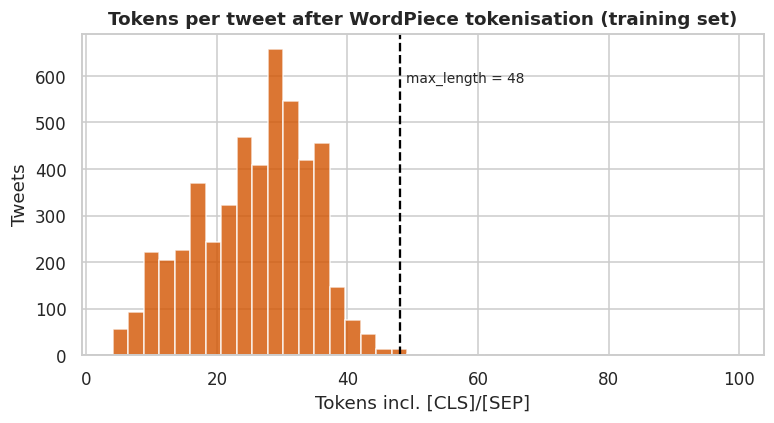

Median 27 tokens, 99th percentile 43, max 99
MAX_LEN = 48 → test tweets truncated: 0.38%
Whitespace words split into ≥2 sub-word pieces: 19.0%


In [98]:
# Compute token sequence lengths for training and test tweets using the DistilBERT tokenizer
lengths = np.array([len(ids) for ids in tokenizer(train_df.text_clean.tolist())["input_ids"]])
MAX_LEN = int(min(128, np.ceil(np.percentile(lengths, 99.5) / 8) * 8))
test_lengths = np.array([len(ids) for ids in tokenizer(test_df.text_clean.tolist())["input_ids"]])

# Calculate the proportion of whitespace words that get fragmented into subword pieces by WordPiece
words = [w for t in train_df.text_clean for w in t.split()]
fragmented = np.mean([len(tokenizer.tokenize(w)) > 1 for w in words[:20000]])

# Plot training set token length distribution histogram and annotate the selected sequence truncation limit
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(lengths, bins=40, color="#D35400", alpha=0.8)
ax.axvline(MAX_LEN, color="black", ls="--")
ax.text(MAX_LEN + 1, ax.get_ylim()[1] * 0.85, f"max_length = {MAX_LEN}", fontsize=9)
ax.set(title="Tokens per tweet after WordPiece tokenisation (training set)", xlabel="Tokens incl. [CLS]/[SEP]",
       ylabel="Tweets")

# Save token length distribution figure and display plot
save_fig("fig4_01_token_lengths"); plt.show()

# Print summary metrics for token length distribution, test truncation rates, and subword fragmentation
print(f"Median {np.median(lengths):.0f} tokens, 99th percentile {np.percentile(lengths, 99):.0f}, max {lengths.max()}")
print(f"MAX_LEN = {MAX_LEN} → test tweets truncated: {(test_lengths > MAX_LEN).mean():.2%}")
print(f"Whitespace words split into ≥2 sub-word pieces: {fragmented:.1%}")

In [99]:
# Custom PyTorch Dataset class that tokenizes input texts with truncation up to max sequence length
class TweetDataset(Dataset):
    def __init__(self, texts, labels=None):
        self.enc = tokenizer(list(texts), truncation=True, max_length=MAX_LEN)
        self.labels = None if labels is None else np.asarray(labels)

    # Return total number of samples in the dataset
    def __len__(self):
        return len(self.enc["input_ids"])

    # Retrieve tokenized feature dictionary and target sentiment label for a given index
    def __getitem__(self, i):
        item = {k: v[i] for k, v in self.enc.items()}
        if self.labels is not None:
            item["labels"] = int(self.labels[i])
        return item

# Initialize dynamic padding collator to pad sequence inputs to the longest batch item length
collator = DataCollatorWithPadding(tokenizer)

# Compute inverse class frequencies to weight the loss function during model training
counts = np.bincount(train_df.label, minlength=3)
CLASS_WEIGHTS = torch.tensor(len(train_df) / (3 * counts), dtype=torch.float)
print("Class weights:", dict(zip(LABELS, CLASS_WEIGHTS.numpy().round(3))))

Class weights: {'negative': np.float32(0.53), 'neutral': np.float32(1.574), 'positive': np.float32(2.099)}


## 4.4 Fine-tuning
The loop is written in plain PyTorch so that every step is visible: AdamW with weight decay (none on biases or LayerNorm), linear warm-up and decay, class-weighted cross-entropy, gradient clipping, fp16 mixed precision on GPU, and early stopping. After each epoch the model is scored on the validation set, and the weights from the best epoch are kept.

In [100]:
# Helper function to compute forward-pass predictions without gradients using mixed precision
@torch.no_grad()
def predict_logits(model, texts, batch_size=128):
    model.eval()
    loader = DataLoader(TweetDataset(texts), batch_size=batch_size, collate_fn=collator)
    out = []
    for batch in loader:
        batch = {k: v.to(model.device) for k, v in batch.items()}
        with torch.autocast(device_type=model.device.type, dtype=torch.float16,
                            enabled=USE_AMP and model.device.type == "cuda"):
            out.append(model(**batch).logits.float().cpu())
    return torch.cat(out)

# Fine-tune DistilBERT classification model with AdamW optimizer, warmup schedule, and early stopping
def fine_tune(text_col, run_name):
    set_seed()
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=3, id2label=ID2LABEL, label2id=LABEL2ID).to(DEVICE)
    train_loader = DataLoader(TweetDataset(train_df[text_col], train_df.label), batch_size=BATCH_SIZE,
                              shuffle=True, collate_fn=collator, generator=torch.Generator().manual_seed(SEED))
    no_decay = ("bias", "LayerNorm.weight")
    groups = [{"params": [p for n, p in model.named_parameters() if not n.endswith(no_decay)], "weight_decay": WEIGHT_DECAY},
              {"params": [p for n, p in model.named_parameters() if n.endswith(no_decay)], "weight_decay": 0.0}]
    optimizer = torch.optim.AdamW(groups, lr=LEARNING_RATE)
    total_steps = len(train_loader) * EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    loss_fn = torch.nn.CrossEntropyLoss(weight=CLASS_WEIGHTS.to(DEVICE))

    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    history, best_f1, best_state, bad_epochs = [], -1.0, None, 0
    t_start = time.perf_counter()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        t0, running = time.perf_counter(), 0.0
        for batch in train_loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            labels = batch.pop("labels")
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(**batch).logits
            loss = loss_fn(logits.float(), labels)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running += loss.item() * len(labels)

        # Compute validation loss and macro-F1 score to monitor model performance and manage early stopping
        val_logits = predict_logits(model, val_df[text_col])
        val_loss = loss_fn(val_logits.to(DEVICE), torch.tensor(val_df.label.values, device=DEVICE)).item()
        val_pred = val_logits.argmax(-1).numpy()
        val_f1 = f1_score(val_df.label, val_pred, average="macro")
        history.append({"epoch": epoch, "train_loss": running / len(train_df), "val_loss": val_loss,
                        "val_macro_f1": val_f1, "val_accuracy": accuracy_score(val_df.label, val_pred),
                        "epoch_time_s": time.perf_counter() - t0})
        print(f"[{run_name}] epoch {epoch}: train loss {history[-1]['train_loss']:.4f} | val loss {val_loss:.4f} "
              f"| val macro-F1 {val_f1:.4f} | {history[-1]['epoch_time_s']:.0f}s")
        if val_f1 > best_f1:
            best_f1, bad_epochs = val_f1, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= PATIENCE:
                print(f"[{run_name}] early stopping: no improvement for {PATIENCE} epoch(s)")
                break

    # Restore model weights from best validation epoch and log runtime statistics
    model.load_state_dict(best_state)
    info = {"train_time_s": time.perf_counter() - t_start,
            "best_epoch": int(pd.DataFrame(history).val_macro_f1.idxmax() + 1),
            "best_val_macro_f1": best_f1,
            "peak_gpu_mem_gb": torch.cuda.max_memory_allocated() / 1e9 if DEVICE.type == "cuda" else None}
    return model, pd.DataFrame(history), info

# Execute fine-tuning for standard DistilBERT model on cleaned text column
bert, hist, bert_info = fine_tune("text_clean", "DistilBERT")
n_params = sum(p.numel() for p in bert.parameters())
print(f"\nParameters: {n_params:,} | training time: {bert_info['train_time_s']:.0f}s | "
      f"best epoch: {bert_info['best_epoch']} | peak GPU memory: {bert_info['peak_gpu_mem_gb']}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[DistilBERT] epoch 1: train loss 0.7795 | val loss 0.5010 | val macro-F1 0.7870 | 19s
[DistilBERT] epoch 2: train loss 0.4371 | val loss 0.5940 | val macro-F1 0.7727 | 17s
[DistilBERT] early stopping: no improvement for 1 epoch(s)

Parameters: 66,955,779 | training time: 37s | best epoch: 1 | peak GPU memory: 1.623644672


Saved figure → figures/task4/fig4_02_training_curves.png


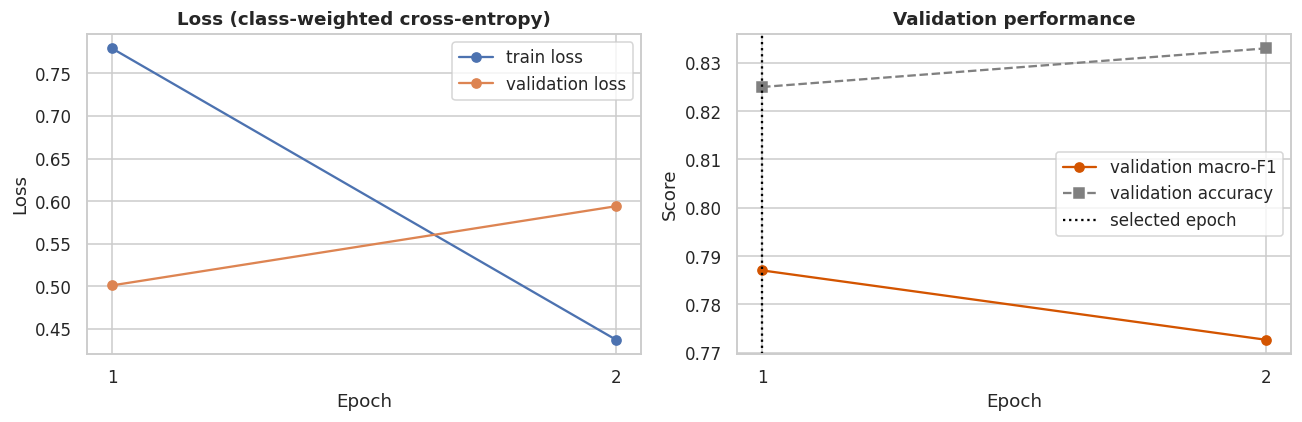

,epoch,train_loss,val_loss,val_macro_f1,val_accuracy,epoch_time_s
0,1,0.7795,0.501,0.7870,0.825,18.8298
1,2,0.4371,0.594,0.7727,0.833,16.8337


In [101]:
# Create side-by-side plot layout for training loss and validation performance curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot training and validation loss trajectories across fine-tuning epochs
axes[0].plot(hist.epoch, hist.train_loss, "o-", label="train loss")
axes[0].plot(hist.epoch, hist.val_loss, "o-", label="validation loss")
axes[0].set(title="Loss (class-weighted cross-entropy)", xlabel="Epoch", ylabel="Loss")
axes[0].legend()

# Plot validation macro-F1 and accuracy curves with vertical line marking the best model checkpoint
axes[1].plot(hist.epoch, hist.val_macro_f1, "o-", color="#D35400", label="validation macro-F1")
axes[1].plot(hist.epoch, hist.val_accuracy, "s--", color="grey", label="validation accuracy")
axes[1].axvline(bert_info["best_epoch"], color="black", ls=":", label="selected epoch")
axes[1].set(title="Validation performance", xlabel="Epoch", ylabel="Score")
axes[1].legend()

# Align x-axis ticks with discrete epoch numbers
for ax in axes:
    ax.set_xticks(hist.epoch)

# Save training curve figure plot and render output
plt.tight_layout()
save_fig("fig4_02_training_curves"); plt.show()

# Display formatted training history metrics table
hist.round(4)

## 4.5 Test-set evaluation

In [102]:
# Helper function to compute non-parametric 95% bootstrap confidence intervals for macro-F1 scores
def bootstrap_ci(y_true, y_pred, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    scores = [f1_score(y_true[i], y_pred[i], average="macro")
              for i in (rng.integers(0, len(y_true), len(y_true)) for _ in range(n_boot))]
    return np.percentile(scores, [2.5, 97.5])

# Helper function to aggregate standard evaluation metrics and confidence intervals into a single row summary
def metric_row(name, y_pred, **extra):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    lo, hi = bootstrap_ci(y_true, y_pred)
    return {"model": name, "accuracy": accuracy_score(y_true, y_pred), "macro precision": p,
            "macro recall": r, "macro F1": f, "macro F1 95% CI": f"[{lo:.3f}, {hi:.3f}]",
            "weighted F1": f1_score(y_true, y_pred, average="weighted"), **extra}

# Extract ground-truth test set sentiment labels
y_true = test_df.airline_sentiment.to_numpy(dtype=str)

# Run test set inference with fine-tuned DistilBERT and measure latency per 1k tweets
t0 = time.perf_counter()
bert_logits = predict_logits(bert, test_df.text_clean)
gpu_ms_per_1k = (time.perf_counter() - t0) / len(test_df) * 1e6
bert_proba = torch.softmax(bert_logits, -1).numpy()
bert_pred = np.array(LABELS)[bert_proba.argmax(1)]

# Display per-class precision, recall, and F1 classification report for DistilBERT on test set
print(classification_report(y_true, bert_pred, labels=LABELS, digits=3))

              precision    recall  f1-score   support

    negative      0.913     0.856     0.884      1817
     neutral      0.617     0.687     0.650       611
    positive      0.731     0.801     0.765       458

    accuracy                          0.812      2886
   macro avg      0.754     0.782     0.766      2886
weighted avg      0.821     0.812     0.815      2886



Saved figure → figures/task4/fig4_03_confusion_matrices.png


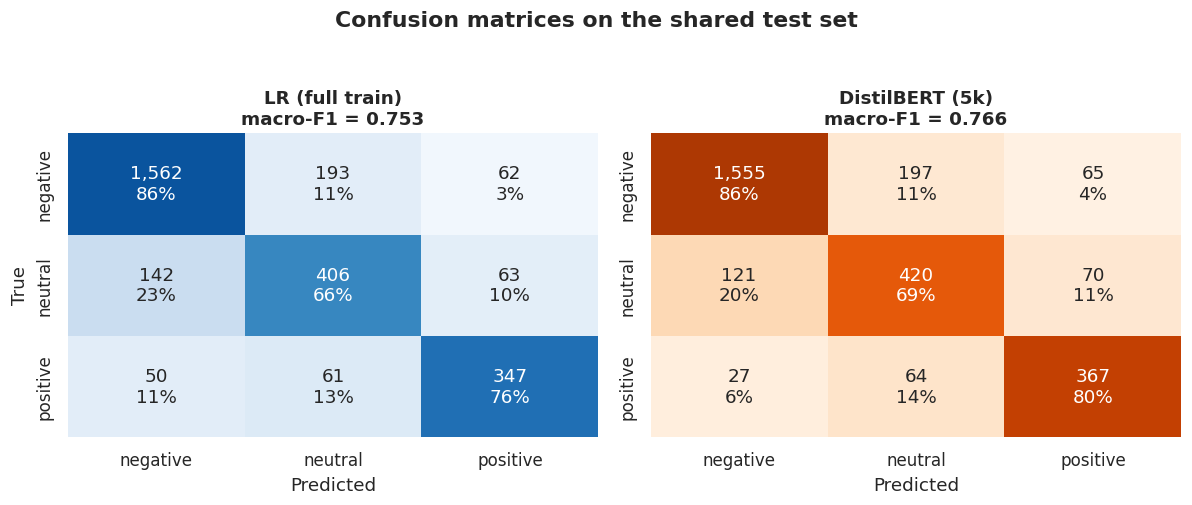

In [103]:
# Extract predictions from Task 2 Logistic Regression baseline model evaluated on the full training set
lr_full_pred = t2_pred["pred_Logistic_Regression"].to_numpy(dtype=str)

# Initialize side-by-side plot layout for comparing confusion matrices between models
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

# Iterate through prediction sets to generate normalized confusion matrices with count and percentage annotations
for ax, (name, pred) in zip(axes, [("LR (full train)", lr_full_pred), ("DistilBERT (5k)", bert_pred)]):
    cm = confusion_matrix(y_true, pred, labels=LABELS)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    annot = np.array([[f"{cm[i, j]:,}\n{cmn[i, j]:.0%}" for j in range(3)] for i in range(3)])
    sns.heatmap(cmn, annot=annot, fmt="", cmap="Oranges" if "BERT" in name else "Blues", vmin=0, vmax=1,
                cbar=False, xticklabels=LABELS, yticklabels=LABELS, ax=ax)
    ax.set(title=f"{name}\nmacro-F1 = {f1_score(y_true, pred, average='macro'):.3f}", xlabel="Predicted",
           ylabel="True" if ax is axes[0] else "")

# Set main title, apply tight layout, save figure artifact, and render plot
plt.suptitle("Confusion matrices on the shared test set", fontweight="bold", y=1.04)
plt.tight_layout()
save_fig("fig4_03_confusion_matrices"); plt.show()

## 4.6 Comparison with the classical baseline


In [104]:
# Map text variants and fit the Task 2 Logistic Regression pipeline on the 5k training subset
VARIANT_TEXT = {"A": lambda d: d.text_clean, "B": lambda d: d.spacy_lemmas.map(" ".join),
                "C": lambda d: d.spacy_lemmas_nostop.map(" ".join), "E": lambda d: d.text_masked}
variant = t2_metrics["text_variant"][0]
to_text = VARIANT_TEXT.get(variant, VARIANT_TEXT["A"])
lr5k = clone(joblib.load(os.path.join(OUT_DIR, "task2_best_model.joblib")))
t0 = time.perf_counter()
lr5k.fit(to_text(train_df), train_df.airline_sentiment)
lr5k_train_time = time.perf_counter() - t0

# Evaluate Logistic Regression inference latency on test set and count model parameters
t0 = time.perf_counter()
lr5k_pred = lr5k.predict(to_text(test_df))
lr_cpu_ms_per_1k = (time.perf_counter() - t0) / len(test_df) * 1e6
lr_n_params = sum(np.prod(a.shape) for a in [lr5k.named_steps["clf"].coef_, lr5k.named_steps["clf"].intercept_])

# Measure DistilBERT CPU inference benchmark latency on a test sample subset
sample_texts = test_df.text_clean.iloc[:256]
bert_cpu = bert.to("cpu")
t0 = time.perf_counter()
_ = predict_logits(bert_cpu, sample_texts, batch_size=64)
bert_cpu_ms_per_1k = (time.perf_counter() - t0) / len(sample_texts) * 1e6
bert = bert_cpu.to(DEVICE)

# Save fine-tuned DistilBERT weights and tokenizer artifacts to disk and calculate model size
bert.save_pretrained(os.path.join(MODEL_DIR, "distilbert_sentiment"))
tokenizer.save_pretrained(os.path.join(MODEL_DIR, "distilbert_sentiment"))
bert_size_mb = sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in
                   os.walk(os.path.join(MODEL_DIR, "distilbert_sentiment")) for f in fs) / 1e6

# Construct comprehensive model comparison DataFrame summarizing accuracy, runtime, parameter count, and size
t2_lr = t2_metrics["test"]["Logistic Regression"]
rows = [
    metric_row("LR (full train)", lr_full_pred, **{"training tweets": 11541, "train time (s)": t2_lr["train time (s)"],
               "hardware": "CPU", "parameters": t2_lr["n features"] * 3 + 3, "model size (MB)": t2_lr["model size (MB)"],
               "CPU inference (ms / 1k tweets)": t2_lr["inference (ms / 1k tweets)"], "GPU inference (ms / 1k tweets)": None}),
    metric_row("LR (5k)", lr5k_pred, **{"training tweets": 5000, "train time (s)": lr5k_train_time, "hardware": "CPU",
               "parameters": int(lr_n_params), "model size (MB)": len(pickle.dumps(lr5k)) / 1e6,
               "CPU inference (ms / 1k tweets)": lr_cpu_ms_per_1k, "GPU inference (ms / 1k tweets)": None}),
    metric_row("DistilBERT (5k)", bert_pred, **{"training tweets": 5000, "train time (s)": bert_info["train_time_s"],
               "hardware": HARDWARE, "parameters": n_params, "model size (MB)": bert_size_mb,
               "CPU inference (ms / 1k tweets)": bert_cpu_ms_per_1k,
               "GPU inference (ms / 1k tweets)": gpu_ms_per_1k if DEVICE.type == "cuda" else None}),
]
comparison = pd.DataFrame(rows).set_index("model")
comparison.round(4)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,accuracy,macro precision,macro recall,macro F1,macro F1 95% CI,weighted F1,training tweets,train time (s),hardware,parameters,model size (MB),CPU inference (ms / 1k tweets),GPU inference (ms / 1k tweets)
model,,,,,,,,,,,,,
LR (full train),0.8021,0.7470,0.7606,0.7533,"[0.736, 0.772]",0.8045,11541,5.2031,CPU,67068,1.0542,211.0583,NaN
LR (5k),0.7879,0.7278,0.7351,0.7314,"[0.713, 0.750]",0.7890,5000,3.5532,CPU,33603,0.5237,76.5950,NaN
DistilBERT (5k),0.8115,0.7536,0.7815,0.7661,"[0.748, 0.783]",0.8152,5000,36.8552,Tesla T4 (16 GB),66955779,268.5482,110825.1529,631.1985


In [105]:
# Helper function to compute exact McNemar test p-value for paired model predictions
def mcnemar(pred_a, pred_b):
    a_ok, b_ok = pred_a == y_true, pred_b == y_true
    b, c = int((a_ok & ~b_ok).sum()), int((~a_ok & b_ok).sum())
    return b, c, binomtest(min(b, c), b + c, 0.5).pvalue

# Evaluate pairwise McNemar statistical significance tests comparing DistilBERT against Logistic Regression baselines
sig = []
for ref_name, ref_pred in [("LR (full train)", lr_full_pred), ("LR (5k)", lr5k_pred)]:
    b, c, p = mcnemar(ref_pred, bert_pred)
    sig.append({"comparison": f"DistilBERT (5k) vs {ref_name}",
                "Δ macro-F1": f1_score(y_true, bert_pred, average="macro") - f1_score(y_true, ref_pred, average="macro"),
                "only classical correct": b, "only DistilBERT correct": c, "McNemar p-value": p})

# Format statistical significance results as a DataFrame and display rounded p-values
pd.DataFrame(sig).set_index("comparison").round(4)

,Δ macro-F1,only classical correct,only DistilBERT correct,McNemar p-value
comparison,,,,
DistilBERT (5k) vs LR (full train),0.0128,216,243,0.2249
DistilBERT (5k) vs LR (5k),0.0347,222,290,0.0030


Saved figure → figures/task4/fig4_04_performance_vs_cost.png


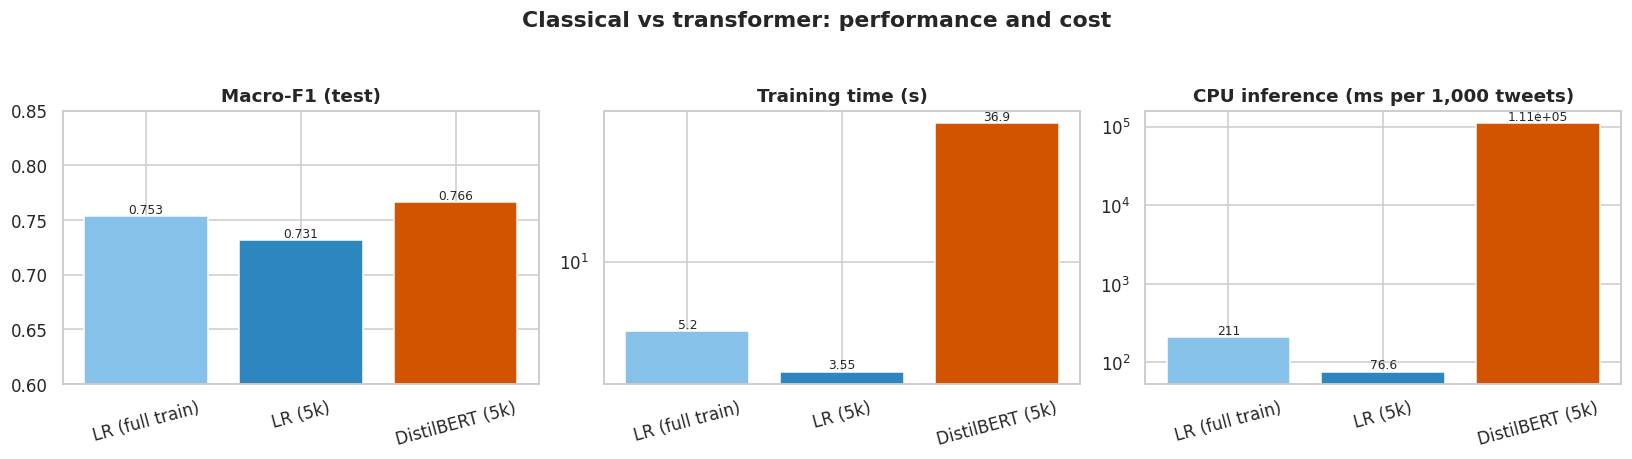

In [106]:
# Copy model comparison metrics for visualization
plot_df = comparison.copy()

# Initialize three-panel figure layout for performance and computational cost metrics
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colors = [MODEL_COLORS[m] for m in plot_df.index]

# Plot test set macro-F1 score comparison across models
axes[0].bar(plot_df.index, plot_df["macro F1"], color=colors)
axes[0].set(title="Macro-F1 (test)", ylim=(0.6, 0.85))

# Plot training runtime in seconds on a logarithmic scale
axes[1].bar(plot_df.index, plot_df["train time (s)"], color=colors)
axes[1].set(title="Training time (s)", yscale="log")

# Plot CPU inference latency per 1,000 tweets on a logarithmic scale
axes[2].bar(plot_df.index, plot_df["CPU inference (ms / 1k tweets)"], color=colors)
axes[2].set(title="CPU inference (ms per 1,000 tweets)", yscale="log")

# Format axes labels, rotate tick labels, and add data labels to bar charts
for ax in axes:
    ax.tick_params(axis="x", rotation=15)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.3g", fontsize=8)

# Set figure title, adjust layout, save figure artifact, and render plot
plt.suptitle("Classical vs transformer: performance and cost", fontweight="bold", y=1.04)
plt.tight_layout()
save_fig("fig4_04_performance_vs_cost"); plt.show()

## 4.7 Error analysis


In [107]:
# Construct test set results DataFrame with true labels, predictions, confidence scores, and correctness flags
res = test_df[["tweet_id", "text_clean", "airline_sentiment", "airline_sentiment_confidence", "negativereason",
               "airline_plot", "text_masked"]].copy()
res["lr_pred"], res["bert_pred"] = lr_full_pred, bert_pred
res["bert_conf"] = bert_proba.max(1)
res["lr_ok"], res["bert_ok"] = res.lr_pred == res.airline_sentiment, res.bert_pred == res.airline_sentiment

# Compute cross-tabulation matrix showing prediction overlap and error agreement between models
overlap = pd.crosstab(res.lr_ok.map({True: "LR correct", False: "LR wrong"}),
                      res.bert_ok.map({True: "DistilBERT correct", False: "DistilBERT wrong"}), margins=True)
display(overlap)

# Display top 5 most confident tweets correctly reclassified by DistilBERT where Logistic Regression failed
cols = ["text_clean", "airline_sentiment", "lr_pred", "bert_pred", "bert_conf", "airline_sentiment_confidence"]
print("Fixed by DistilBERT (LR wrong, DistilBERT right, most confident):")
display(res[~res.lr_ok & res.bert_ok].nlargest(5, "bert_conf")[cols])

# Display top 5 most confident tweets misclassified by both DistilBERT and Logistic Regression
print("Still wrong for both models (DistilBERT most confident):")
display(res[~res.lr_ok & ~res.bert_ok].nlargest(5, "bert_conf")[cols])

bert_ok,DistilBERT correct,DistilBERT wrong,All
lr_ok,,,
LR correct,2099,216,2315
LR wrong,243,328,571
All,2342,544,2886


Fixed by DistilBERT (LR wrong, DistilBERT right, most confident):


,text_clean,airline_sentiment,lr_pred,bert_pred,bert_conf,airline_sentiment_confidence
2885,US Airways No US Air ppl anywhere in PHL directed stranded pax. Kudos to the PHL employees getting off work at midnight. Only help we got.,negative,positive,negative,0.943317,1.00
2203,"American Airlines I am running out of battery you have my chargers,clothes,coat,contact lenses, need to be in mtg tom need help pathetic service",negative,neutral,negative,0.934887,1.00
2555,United our travel booked thru United group dept. Okc ticket agent less than willing to help with our connection in LAX.,negative,neutral,negative,0.929769,0.66
1995,United deceptive marketing practices promised me if i booked flights i would retain my status now they are not granting. Neverflyunited,negative,neutral,negative,0.927858,1.00
714,American Airlines an overzealous stewardess prevented us from bringing in a car seat! worstflight !,negative,neutral,negative,0.927216,1.00


Still wrong for both models (DistilBERT most confident):


,text_clean,airline_sentiment,lr_pred,bert_pred,bert_conf,airline_sentiment_confidence
2086,American Airlines thanks for the canned reply.,negative,positive,positive,0.930573,0.6787
1789,American Airlines at LAX & just got off the phone w/reservations. Every flight that'd get me to BOS before 11 am tmrw is apparently unavailable neutral_face,neutral,negative,negative,0.929250,0.6646
2160,United What a really GREAT & FLATTERING story about you! You should be very proud happy_emoticon (via ),negative,positive,positive,0.924582,1.0000
2361,"United OK, thanks for the clarification.",neutral,positive,positive,0.924443,0.6202
1341,JetBlue Thank you for opening the conversation. I hope you can make it right.,neutral,positive,positive,0.922241,0.6888


In [108]:
# Load Task 2 misclassified examples artifact and compute DistilBERT probability predictions
t2_errors = pd.read_csv(os.path.join(OUT_DIR, "task2_misclassified_examples.csv"))
p = torch.softmax(predict_logits(bert, t2_errors["text (cleaned)"]), -1).numpy()

# Assign DistilBERT predicted class labels, max confidence probabilities, and correction indicator flags
t2_errors["DistilBERT pred"] = np.array(LABELS)[p.argmax(1)]
t2_errors["DistilBERT P(pred)"] = p.max(1).round(2)
t2_errors["fixed?"] = np.where(t2_errors["DistilBERT pred"] == t2_errors["true"], "✔", "✘")

# Display re-scored Task 2 error examples comparing Logistic Regression and DistilBERT predictions
t2_errors[["text (cleaned)", "true", "pred", "DistilBERT pred", "DistilBERT P(pred)", "fixed?", "annotator conf."]] \
    .rename(columns={"pred": "LR pred"})

,text (cleaned),true,LR pred,DistilBERT pred,DistilBERT P(pred),fixed?,annotator conf.
0,American Airlines thanks for the canned reply.,negative,positive,positive,0.93,✘,0.6787
1,United What a really GREAT & FLATTERING story about you! You should be very proud happy_emoticon (via ),negative,positive,positive,0.92,✘,1.0000
2,"US Airways after missing my flight and rebooking 2x, I just walked onto another flight and my phone was still on the seat!!",positive,negative,negative,0.88,✘,0.3678
3,US Airways we haven't departed yet so let's not get too high hopes. But everything has been on schedule so far,positive,negative,negative,0.65,✘,0.7049
4,"Southwest I was under the impression when there is an 8 hour delay in your flight because of equipment failure, compensation is offered?",neutral,negative,negative,0.81,✘,0.6563
5,United Why have airlines always told us they can't open a cabin door once it has been closed? This plane has done it 3 times tonight.,neutral,negative,negative,0.90,✘,0.6476
6,"United Freakin""",negative,neutral,negative,0.45,✔,0.6700
7,Southwest When will the flight resume? I don's see it in the open schedule. sad_emoticon,negative,neutral,neutral,0.77,✘,1.0000


Saved figure → figures/task4/fig4_05_error_slices.png


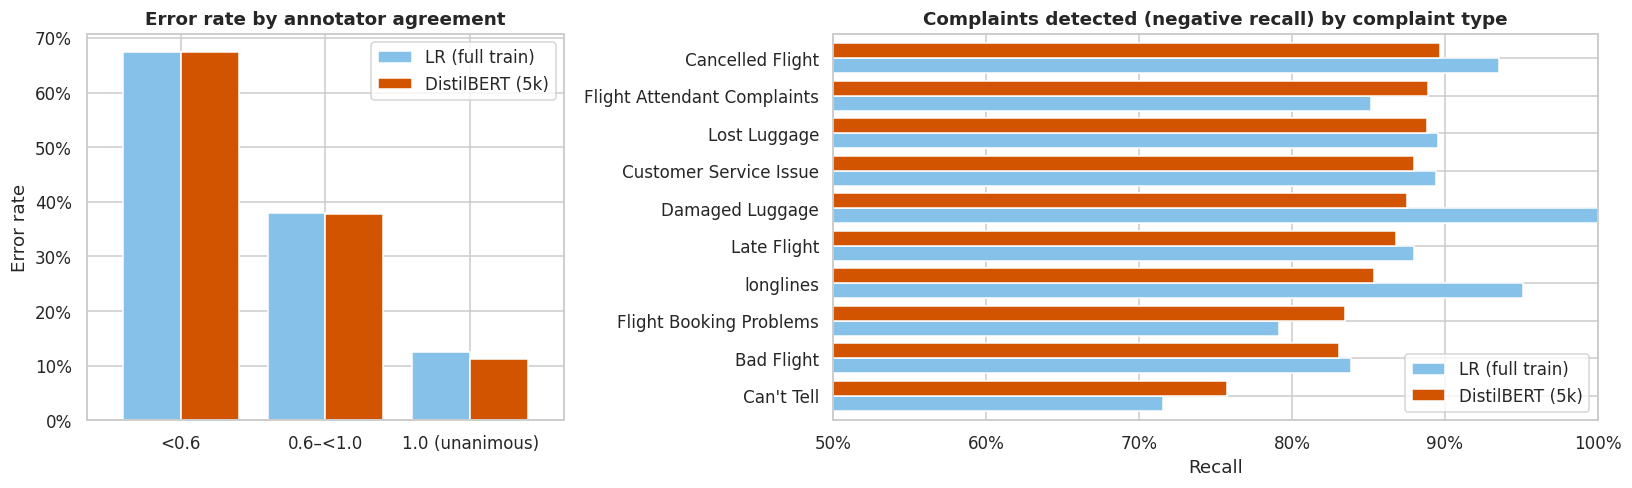

In [109]:
# Bin annotator confidence scores to evaluate error rates across label agreement levels
res["conf_bin"] = pd.cut(res.airline_sentiment_confidence, [0, 0.6, 0.999, 1.0],
                         labels=["<0.6", "0.6–<1.0", "1.0 (unanimous)"])

# Initialize side-by-side figure for error analysis across confidence bins and complaint types
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1.6]})

# Compute and plot model error rates grouped by annotator confidence bins
err = pd.DataFrame({"LR (full train)": 1 - res.groupby("conf_bin", observed=True).lr_ok.mean(),
                    "DistilBERT (5k)": 1 - res.groupby("conf_bin", observed=True).bert_ok.mean()})
err.plot(kind="bar", ax=axes[0], color=[MODEL_COLORS[c] for c in err.columns], rot=0, width=0.8)
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set(title="Error rate by annotator agreement", xlabel="", ylabel="Error rate")

# Filter negative sentiment tweets and evaluate negative recall across distinct complaint categories
neg = res[res.airline_sentiment == "negative"]
rec = pd.DataFrame({"LR (full train)": neg.groupby("negativereason").apply(lambda g: (g.lr_pred == "negative").mean(), include_groups=False),
                    "DistilBERT (5k)": neg.groupby("negativereason").apply(lambda g: (g.bert_pred == "negative").mean(), include_groups=False)})
rec = rec.sort_values("DistilBERT (5k)")

# Plot negative recall bar chart by complaint type, apply percent formatting, and adjust plot bounds
rec.plot(kind="barh", ax=axes[1], color=[MODEL_COLORS[c] for c in rec.columns], width=0.8)
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].set_xlim(0.5, 1.0)
axes[1].set(title="Complaints detected (negative recall) by complaint type", xlabel="Recall", ylabel="")

# Save error slice figure and render plot layout
plt.tight_layout()
save_fig("fig4_05_error_slices"); plt.show()

## 4.8 Reliability: calibration and confidence-based routing


Saved figure → figures/task4/fig4_06_calibration_and_routing.png


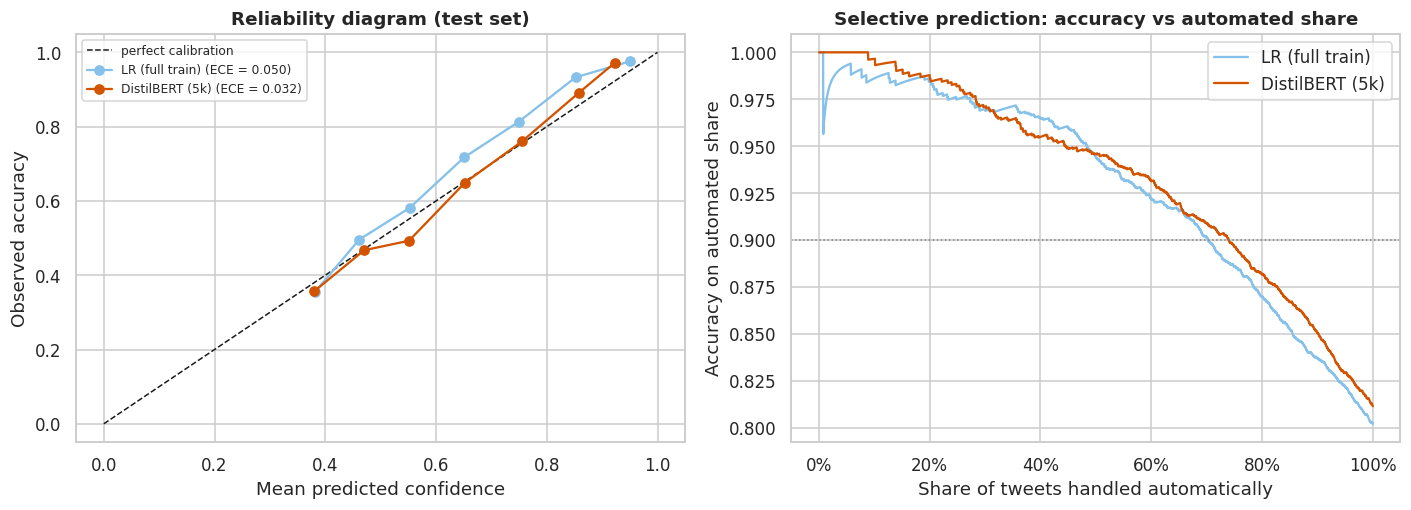

,ECE,automatable share at ≥90% accuracy,confidence threshold,tweets routed to humans
model,,,,
LR (full train),0.050,0.702,0.646,0.298
DistilBERT (5k),0.032,0.740,0.709,0.260


In [110]:
# Extract class probabilities for Logistic Regression from Task 2 test prediction inputs
lr_proba = t2_pred[[f"proba_LR_{l}" for l in LABELS]].values

# Helper function to calculate reliability diagram binned statistics and Expected Calibration Error (ECE)
def reliability(proba, y, n_bins=10):
    conf, pred = proba.max(1), np.array(LABELS)[proba.argmax(1)]
    correct = pred == y
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(conf, bins) - 1, 0, n_bins - 1)
    table = pd.DataFrame({"conf": conf, "correct": correct, "bin": idx}).groupby("bin").agg(
        conf=("conf", "mean"), acc=("correct", "mean"), n=("correct", "size"))
    ece = (table.n / len(y) * (table.acc - table.conf).abs()).sum()
    return table, ece

# Helper function to calculate selective prediction coverage curves sorted by confidence
def coverage_curve(proba, y):
    conf = proba.max(1)
    correct = np.array(LABELS)[proba.argmax(1)] == y
    order = np.argsort(-conf)
    cov = np.arange(1, len(y) + 1) / len(y)
    acc = np.cumsum(correct[order]) / np.arange(1, len(y) + 1)
    return cov, acc, conf[order]

# Initialize plot layout for calibration reliability diagrams and selective prediction curves
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
routing = []

# Evaluate calibration metrics and selective prediction thresholds across model predictions
for name, proba in [("LR (full train)", lr_proba), ("DistilBERT (5k)", bert_proba)]:
    table, ece = reliability(proba, y_true)
    axes[0].plot(table.conf, table.acc, "o-", color=MODEL_COLORS[name], label=f"{name} (ECE = {ece:.3f})")
    cov, acc, conf_sorted = coverage_curve(proba, y_true)
    axes[1].plot(cov, acc, color=MODEL_COLORS[name], label=name)
    target = 0.90
    ok = np.where(acc >= target)[0]
    auto_share = cov[ok.max()] if len(ok) else 0.0
    routing.append({"model": name, "ECE": ece, "automatable share at ≥90% accuracy": auto_share,
                    "confidence threshold": conf_sorted[ok.max()] if len(ok) else None,
                    "tweets routed to humans": 1 - auto_share})

# Format plot titles, labels, legends, and axis percentage formatting
axes[0].set(title="Reliability diagram (test set)", xlabel="Mean predicted confidence", ylabel="Observed accuracy")
axes[0].legend(fontsize=8)
axes[1].axhline(0.90, color="grey", ls=":", lw=1)
axes[1].xaxis.set_major_formatter(PercentFormatter(1))
axes[1].set(title="Selective prediction: accuracy vs automated share", xlabel="Share of tweets handled automatically",
            ylabel="Accuracy on automated share")
axes[1].legend()

# Save calibration and routing figure artifact and render plot layout
plt.tight_layout()
save_fig("fig4_06_calibration_and_routing"); plt.show()

# Display selective routing trade-off summary table rounded to three decimal places
pd.DataFrame(routing).set_index("model").round(3)

## 4.9 Fairness: airline-level complaint detection


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[DistilBERT-masked] epoch 1: train loss 0.7772 | val loss 0.5152 | val macro-F1 0.7821 | 13s
[DistilBERT-masked] epoch 2: train loss 0.4289 | val loss 0.5571 | val macro-F1 0.7795 | 12s
[DistilBERT-masked] early stopping: no improvement for 1 epoch(s)


,test macro-F1,min airline,max airline,disparity (max − min)
LR (full train),0.753,0.676,0.897,0.221
"LR, airline names removed",0.754,0.811,0.883,0.073
DistilBERT (5k),0.766,0.757,0.914,0.157
"DistilBERT (5k, airline-masked)",0.771,0.811,0.885,0.074


Saved figure → figures/task4/fig4_07_airline_fairness.png


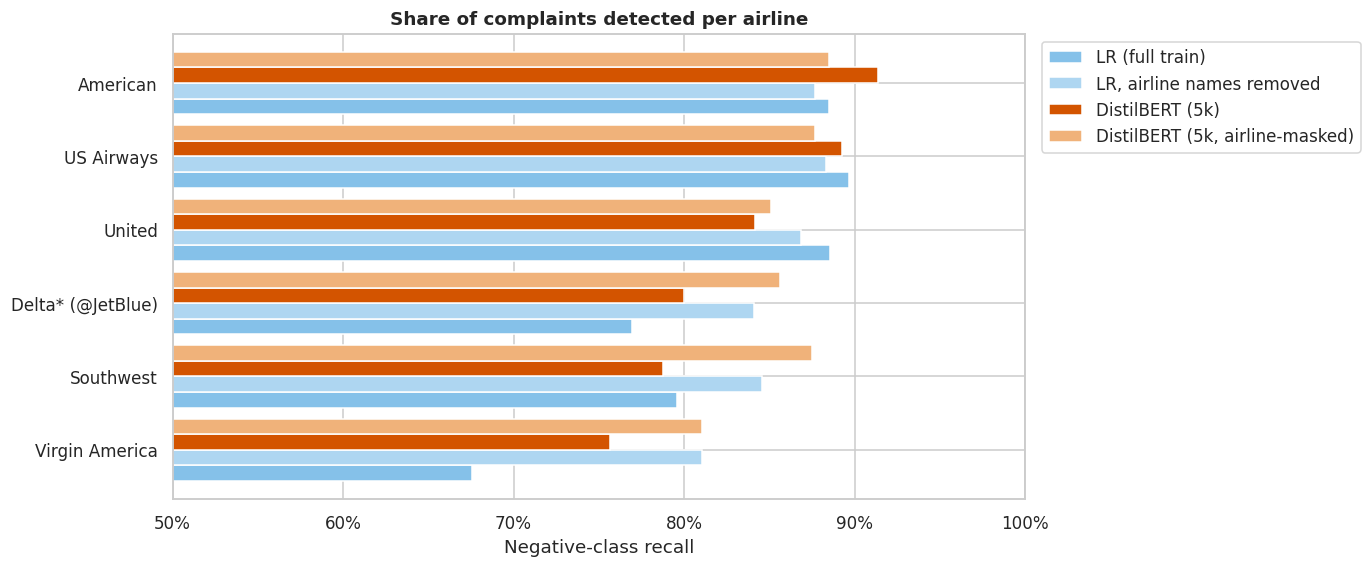

In [111]:
# Define helper function to calculate negative complaint recall segmented across different airlines
def complaint_recall_by_airline(pred):
    m = res.airline_sentiment == "negative"
    return pd.Series(pred[m.values] == "negative", index=res.index[m]).groupby(res.airline_plot[m]).mean()

# Initialize prediction dictionary with unmasked Logistic Regression baseline predictions
fair_preds = {"LR (full train)": lr_full_pred}
if "pred_best_airline_masked" in t2_pred:
    fair_preds["LR, airline names removed"] = t2_pred["pred_best_airline_masked"].to_numpy(dtype=str)
fair_preds["DistilBERT (5k)"] = bert_pred

# Fine-tune DistilBERT model on airline-masked text if training toggle flag is enabled
if TRAIN_MASKED_VARIANT:
    bert_m, hist_m, info_m = fine_tune("text_masked", "DistilBERT-masked")
    bert_m_proba = torch.softmax(predict_logits(bert_m, test_df.text_masked), -1).numpy()
    bert_m_pred = np.array(LABELS)[bert_m_proba.argmax(1)]
    fair_preds["DistilBERT (5k, airline-masked)"] = bert_m_pred
    del bert_m
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

# Compute per-airline complaint recall and construct macro fairness summary statistics
fair = pd.DataFrame({name: complaint_recall_by_airline(p) for name, p in fair_preds.items()})
fair = fair.sort_values("DistilBERT (5k)")
summary = pd.DataFrame({"test macro-F1": {n: f1_score(y_true, p, average="macro") for n, p in fair_preds.items()},
                        "min airline": fair.min(), "max airline": fair.max(),
                        "disparity (max − min)": fair.max() - fair.min()})
display(summary.round(3))

# Plot horizontal bar chart comparing per-airline negative recall across models and masking variants
palette = {"LR (full train)": "#85C1E9", "LR, airline names removed": "#AED6F1", "DistilBERT (5k)": "#D35400",
           "DistilBERT (5k, airline-masked)": "#F0B27A"}
ax = fair.plot(kind="barh", figsize=(10, 5.5), width=0.85, color=[palette[c] for c in fair.columns])
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlim(0.5, 1.0)
ax.set(title="Share of complaints detected per airline", xlabel="Negative-class recall", ylabel="")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")

# Save fairness evaluation plot artifact and render layout
save_fig("fig4_07_airline_fairness"); plt.show()

## 4.10 Reference: pretrained Twitter sentiment pipeline (no fine-tuning)


In [112]:
# Initialize zero-shot prediction variable
zs_pred = None

# Perform zero-shot sentiment evaluation using Twitter-RoBERTa model pipeline if enabled
if RUN_ZERO_SHOT:
    try:
        # Load Hugging Face text classification pipeline with GPU or CPU device targeting
        clf_zs = pipeline("text-classification", model=ZERO_SHOT_MODEL, tokenizer=ZERO_SHOT_MODEL,
                          device=0 if DEVICE.type == "cuda" else -1, truncation=True, max_length=128)
        id2label = clf_zs.model.config.id2label
        fallback_map = {"label_0": "negative", "label_1": "neutral", "label_2": "positive"}

        # Execute zero-shot sentiment inference on cleaned test set texts and measure batch processing time
        t0 = time.perf_counter()
        out = clf_zs(test_df.text_clean.tolist(), batch_size=64)
        zs_time = time.perf_counter() - t0

        # Map raw predicted class labels to standardized target sentiment strings
        zs_pred = np.array([fallback_map.get(o["label"].lower(), o["label"].lower()) for o in out])

        # Append Twitter-RoBERTa zero-shot metrics and resource usage to overall comparison table
        comparison.loc["Twitter-RoBERTa (zero-shot)"] = pd.Series(metric_row(
            "Twitter-RoBERTa (zero-shot)", zs_pred, **{"training tweets": 0, "train time (s)": 0.0, "hardware": HARDWARE,
            "parameters": sum(p.numel() for p in clf_zs.model.parameters()), "model size (MB)": None,
            "CPU inference (ms / 1k tweets)": None,
            "GPU inference (ms / 1k tweets)": zs_time / len(test_df) * 1e6 if DEVICE.type == "cuda" else None})).drop("model")

        # Print label mapping schema and full zero-shot classification evaluation report
        print(f"Label mapping used: {id2label}")
        print(classification_report(y_true, zs_pred, labels=LABELS, digits=3))

        # Clean up zero-shot pipeline to release model memory resources
        del clf_zs
    except Exception as err:
        print(f"Zero-shot reference skipped ({err})")

# Display updated comparative summary table rounded to four decimal places
comparison.round(4)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Label mapping used: {0: 'negative', 1: 'neutral', 2: 'positive'}
              precision    recall  f1-score   support

    negative      0.928     0.817     0.869      1817
     neutral      0.566     0.645     0.603       611
    positive      0.690     0.891     0.778       458

    accuracy                          0.792      2886
   macro avg      0.728     0.784     0.750      2886
weighted avg      0.814     0.792     0.798      2886



,accuracy,macro precision,macro recall,macro F1,macro F1 95% CI,weighted F1,training tweets,train time (s),hardware,parameters,model size (MB),CPU inference (ms / 1k tweets),GPU inference (ms / 1k tweets)
model,,,,,,,,,,,,,
LR (full train),0.8021,0.7470,0.7606,0.7533,"[0.736, 0.772]",0.8045,11541,5.2031,CPU,67068,1.0542,211.0583,NaN
LR (5k),0.7879,0.7278,0.7351,0.7314,"[0.713, 0.750]",0.7890,5000,3.5532,CPU,33603,0.5237,76.5950,NaN
DistilBERT (5k),0.8115,0.7536,0.7815,0.7661,"[0.748, 0.783]",0.8152,5000,36.8552,Tesla T4 (16 GB),66955779,268.5482,110825.1529,631.1985
Twitter-RoBERTa (zero-shot),0.7921,0.7282,0.7841,0.7499,"[0.732, 0.767]",0.7981,0,0.0000,Tesla T4 (16 GB),124647939,NaN,NaN,3303.7401


## 4.11 Final comparison table and saving outputs

In [113]:
# Map qualitative interpretability and deployment notes to model names in comparison table
QUALITATIVE = {
    "LR (full train)": ("High: per-word coefficients", "CPU, milliseconds, ~1 MB; retrain in seconds"),
    "LR (5k)": ("High: per-word coefficients", "CPU, milliseconds, ~1 MB; retrain in seconds"),
    "DistilBERT (5k)": ("Low: needs post-hoc tools (attention, SHAP, LIME)", "GPU preferred; ~250 MB; versioning and monitoring needed"),
    "Twitter-RoBERTa (zero-shot)": ("Low", "No training data needed, but no control over label definitions"),
}

# Attach interpretability and deployment practicality columns to final model comparison DataFrame
final = comparison.copy()
final["interpretability"] = final.index.map(lambda m: QUALITATIVE.get(m, ("", ""))[0])
final["deployment practicality"] = final.index.map(lambda m: QUALITATIVE.get(m, ("", ""))[1])

# Save final comparison summary table to CSV artifact in output directory
final.to_csv(os.path.join(OUT_DIR, "task4_comparison.csv"))

# Display final rounded comparison table
final.round(4)

,accuracy,macro precision,macro recall,macro F1,macro F1 95% CI,weighted F1,training tweets,train time (s),hardware,parameters,model size (MB),CPU inference (ms / 1k tweets),GPU inference (ms / 1k tweets),interpretability,deployment practicality
model,,,,,,,,,,,,,,,
LR (full train),0.8021,0.7470,0.7606,0.7533,"[0.736, 0.772]",0.8045,11541,5.2031,CPU,67068,1.0542,211.0583,NaN,High: per-word coefficients,"CPU, milliseconds, ~1 MB; retrain in seconds"
LR (5k),0.7879,0.7278,0.7351,0.7314,"[0.713, 0.750]",0.7890,5000,3.5532,CPU,33603,0.5237,76.5950,NaN,High: per-word coefficients,"CPU, milliseconds, ~1 MB; retrain in seconds"
DistilBERT (5k),0.8115,0.7536,0.7815,0.7661,"[0.748, 0.783]",0.8152,5000,36.8552,Tesla T4 (16 GB),66955779,268.5482,110825.1529,631.1985,"Low: needs post-hoc tools (attention, SHAP, LIME)",GPU preferred; ~250 MB; versioning and monitoring needed
Twitter-RoBERTa (zero-shot),0.7921,0.7282,0.7841,0.7499,"[0.732, 0.767]",0.7981,0,0.0000,Tesla T4 (16 GB),124647939,NaN,NaN,3303.7401,Low,"No training data needed, but no control over label definitions"


In [114]:
# Construct test predictions DataFrame with sentiment labels, model predictions, and class probabilities
pred_out = res[["tweet_id", "airline_sentiment", "airline_plot", "negativereason", "lr_pred", "bert_pred"]].copy()
for k, l in enumerate(LABELS):
    pred_out[f"proba_bert_{l}"] = bert_proba[:, k]
if TRAIN_MASKED_VARIANT:
    pred_out["bert_masked_pred"] = bert_m_pred
if zs_pred is not None:
    pred_out["zero_shot_pred"] = zs_pred

# Save prediction results and fine-tuning history to CSV files in output directory
pred_out.to_csv(os.path.join(OUT_DIR, "task4_test_predictions.csv"), index=False)
hist.to_csv(os.path.join(OUT_DIR, "task4_training_history.csv"), index=False)

# Assemble comprehensive metrics dictionary covering hyperparameters, benchmark performance, significance, calibration, and fairness
metrics = {
    "model": MODEL_NAME, "hardware": HARDWARE, "max_len": MAX_LEN, "epochs_max": EPOCHS,
    "best_epoch": bert_info["best_epoch"], "train_time_s": round(bert_info["train_time_s"], 1),
    "peak_gpu_mem_gb": bert_info["peak_gpu_mem_gb"], "parameters": int(n_params), "model_size_mb": round(bert_size_mb, 1),
    "comparison": final.drop(columns=["interpretability", "deployment practicality"]).round(4).to_dict(orient="index"),
    "significance": pd.DataFrame(sig).set_index("comparison").round(4).to_dict(orient="index"),
    "calibration_routing": pd.DataFrame(routing).set_index("model").round(4).to_dict(orient="index"),
    "fairness_complaint_recall": fair.round(4).to_dict(), "fairness_summary": summary.round(4).to_dict(orient="index"),
}

# Export metrics dictionary to JSON file and display formatted initial output string
with open(os.path.join(OUT_DIR, "task4_metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2, default=str)
print(json.dumps(metrics, indent=2, default=str)[:2000])

{
  "model": "distilbert-base-uncased",
  "hardware": "Tesla T4 (16 GB)",
  "max_len": 48,
  "epochs_max": 4,
  "best_epoch": 1,
  "train_time_s": 36.9,
  "peak_gpu_mem_gb": 1.623644672,
  "parameters": 66955779,
  "model_size_mb": 268.5,
  "comparison": {
    "LR (full train)": {
      "accuracy": 0.8021,
      "macro precision": 0.747,
      "macro recall": 0.7606,
      "macro F1": 0.7533,
      "macro F1 95% CI": "[0.736, 0.772]",
      "weighted F1": 0.8045,
      "training tweets": 11541,
      "train time (s)": 5.2031,
      "hardware": "CPU",
      "parameters": 67068,
      "model size (MB)": 1.0542,
      "CPU inference (ms / 1k tweets)": 211.0583,
      "GPU inference (ms / 1k tweets)": NaN
    },
    "LR (5k)": {
      "accuracy": 0.7879,
      "macro precision": 0.7278,
      "macro recall": 0.7351,
      "macro F1": 0.7314,
      "macro F1 95% CI": "[0.713, 0.750]",
      "weighted F1": 0.789,
      "training tweets": 5000,
      "train time (s)": 3.5532,
      "hardware"

In [115]:
# Create compressed zip archive containing generated pipeline figure plots and output data artifacts
import os, zipfile

with zipfile.ZipFile("nlp_pipeline_outputs.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for folder in ["figures", "outputs"]:
        for root, _, names in os.walk(folder):
            for name in sorted(names):
                z.write(os.path.join(root, name))

# Display total size of created zip file artifact in megabytes
print(f"nlp_pipeline_outputs.zip: {os.path.getsize('nlp_pipeline_outputs.zip') / 1e6:.1f} MB")

# Trigger automatic file download prompt if executing inside Google Colab environment
try:
    from google.colab import files
    files.download("nlp_pipeline_outputs.zip")
except ImportError:
    print("Not running in Colab: the zip is in the working directory.")

nlp_pipeline_outputs.zip: 12.0 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>